In [ ]:
Satu CSV_PATH

In [ ]:
# ============================================================
# DTW-RL Log Visualization Generator
# - Generate ordered pairwise + single-metric figures
# - Save all figures to PNG files
# - Save summary statistics to CSV/TXT
# - Suitable for PPT / paper preparation
# ============================================================

from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================
CSV_PATH = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/DTW-RL-LQL/CSVLQL/Mob2/Interval10/Mob2Interval102.csv"
OUTPUT_DIR = Path("/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/DTW-RL-LQL/CSVLQL/Mob2/Interval10/dtw_rl_figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_SIZE = 30  # seconds
LAST5_MIN_SECONDS = 300

# Pair plot options
NORMALIZE_PDR_IN_PAIR = False
NORMALIZE_DELAY_IN_PAIR = True

# Delay validity filter
DELAY_MIN_MS = 1
DELAY_MAX_MS = 5000   # ubah jika perlu, mis. 3000 / 10000


# ============================================================
# HELPERS
# ============================================================
def time_to_seconds(t: str) -> float:
    parts = str(t).split(":")
    try:
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
    except Exception:
        return np.nan
    return np.nan


def extract_float(pattern: str, text: str) -> float:
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def normalize(series: pd.Series) -> pd.Series:
    s = pd.Series(series, dtype=float).ffill().bfill()
    s_min = s.min()
    s_max = s.max()
    if pd.isna(s_min) or pd.isna(s_max) or s_max == s_min:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - s_min) / (s_max - s_min)


def save_figure(fig: plt.Figure, outpath: Path, dpi: int = 200) -> None:
    outpath.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    plt.close(fig)


def build_output_path(name: str) -> Path:
    safe = name.lower().replace(" ", "_").replace("/", "_")
    return OUTPUT_DIR / f"{safe}.png"


def safe_mean(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.mean()) if len(s) else np.nan


def safe_min(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.min()) if len(s) else np.nan


def safe_max(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.max()) if len(s) else np.nan


def safe_std(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.std()) if len(s) else np.nan


# ============================================================
# LOAD + PARSE
# ============================================================
df = pd.read_csv(CSV_PATH, engine="python", on_bad_lines="skip")

if not {"time", "node", "message"}.issubset(df.columns):
    raise ValueError("CSV harus memiliki kolom: time, node, message")

df["t"] = df["time"].apply(time_to_seconds)
msgs = df["message"].astype(str)

# ------------------------------------------------------------
# RL / network telemetry
# ------------------------------------------------------------
df["tau"]   = msgs.apply(lambda x: extract_float(r"tau=([0-9\.]+)", x))
df["invT"]  = msgs.apply(lambda x: extract_float(r"invT=([0-9\.]+)", x))

# RL state (normalized)
df["dE"]    = msgs.apply(lambda x: extract_float(r"dE=([0-9\.]+)", x))

# Total physical energy (CPU + TX + RX) in mJ
df["dE_mJ"] = msgs.apply(lambda x: extract_float(r"dE_mJ=([0-9\.]+)", x))

# CPU-only physical energy in mJ, logged as dEC
df["dEC"]   = msgs.apply(lambda x: extract_float(r"dEC=([0-9\.]+)", x))

# Instability
df["I"]     = msgs.apply(lambda x: extract_float(r"I=([0-9\.]+)", x))

# PDR
df["PDR"]   = msgs.apply(lambda x: extract_float(r"PDR=([0-9\.]+)", x))

# Delay: capture both formats
# 1) Delay=250ms

def extract_delay(text: str) -> float:
    return extract_float(r"Delay=([0-9\.]+)ms", text)

df["Delay"] = msgs.apply(extract_delay)

# Filter delay tidak valid / outlier
df["Delay"] = df["Delay"].where(
    (df["Delay"] >= DELAY_MIN_MS) & (df["Delay"] <= DELAY_MAX_MS),
    np.nan
)

# ------------------------------------------------------------
# HO event murni
# only lines like: HO,21,delay_ms=78
# ------------------------------------------------------------
df["HO_event"] = msgs.str.contains(r"HO,\d+,delay_ms=\d+", regex=True, na=False).astype(int)

# Optional debugging
df["HO_any"] = msgs.str.contains("HO", case=False, na=False).astype(int)

# Remove invalid time rows
df = df.dropna(subset=["t"]).copy()

# ------------------------------------------------------------
# Time bins
# ------------------------------------------------------------
bins = np.arange(0, df["t"].max() + BIN_SIZE, BIN_SIZE)
df["bin"] = np.digitize(df["t"], bins) - 1

# Total network-wide HO per bin
ho_sum_bin = df.groupby("bin")["HO_event"].sum()

# Mean HO per active node per bin
ho_rows = df[df["HO_event"] == 1].copy()
ho_node_bin = ho_rows.groupby(["bin", "node"]).size().reset_index(name="ho_count")
ho_mean_bin = ho_node_bin.groupby("bin")["ho_count"].mean()

agg = pd.DataFrame({
    "tau":          df.groupby("bin")["tau"].mean(),
    "invT":         df.groupby("bin")["invT"].mean(),
    "dE":           df.groupby("bin")["dE"].mean(),
    "dE_mJ":        df.groupby("bin")["dE_mJ"].mean(),
    "dEC":          df.groupby("bin")["dEC"].mean(),
    "I":            df.groupby("bin")["I"].mean(),
    "PDR":          df.groupby("bin")["PDR"].mean(),
    "Delay":        df.groupby("bin")["Delay"].mean(),
    "HO":           ho_sum_bin,     # total network-wide HO per bin
    "HO_mean_node": ho_mean_bin,    # mean HO per active node per bin
}).dropna(how="all")

agg["time"] = agg.index * BIN_SIZE


# ============================================================
# STYLE
# ============================================================
plt.rcParams.update({
    "figure.figsize": (10, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "lines.linewidth": 2.2,
})

COLORS = {
    "tau":          "tab:blue",
    "HO":           "tab:orange",
    "HO_mean_node": "goldenrod",
    "dE":           "tab:olive",
    "dE_mJ":        "tab:green",
    "invT":         "tab:red",
    "PDR":          "tab:purple",
    "dEC":          "tab:brown",
    "Delay":        "tab:pink",
    "I":            "tab:gray",
}

LABELS = {
    "tau":          "tau",
    "HO":           "HO",
    "HO_mean_node": "HO_mean_node",
    "dE":           "dE",
    "dE_mJ":        "dE_mJ",
    "invT":         "invTrust",
    "PDR":          "PDR",
    "dEC":          "dEC_CPU_mJ",
    "Delay":        "Delay",
    "I":            "Instability (I)",
}


# ============================================================
# PLOT FUNCTIONS
# ============================================================
def pair_plot(
    y1: str,
    y2: str,
    title: str,
    outname: str,
    normalize_y1: bool = True,
    normalize_y2: bool = True,
    ylabel: str = "Normalized value",
) -> None:
    s1 = normalize(agg[y1]) if normalize_y1 else agg[y1].astype(float).ffill().bfill()
    s2 = normalize(agg[y2]) if normalize_y2 else agg[y2].astype(float).ffill().bfill()

    fig, ax = plt.subplots()
    ax.plot(agg["time"], s1, label=LABELS[y1], color=COLORS[y1])
    ax.plot(agg["time"], s2, label=LABELS[y2], color=COLORS[y2])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def single_plot_raw(
    y: str,
    title: str,
    outname: str,
    ylabel: str | None = None,
    last_n_seconds: int | None = None,
) -> None:
    plot_df = agg.copy()

    if last_n_seconds is not None:
        t_max = plot_df["time"].max()
        plot_df = plot_df[plot_df["time"] >= (t_max - last_n_seconds)].copy()

    series = plot_df[y].astype(float).ffill().bfill()
    final_ylabel = ylabel or LABELS[y]

    fig, ax = plt.subplots()
    ax.plot(plot_df["time"], series, color=COLORS[y], label=LABELS[y])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(final_ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def combined_plot(cols: list[str], title: str, outname: str) -> None:
    fig, ax = plt.subplots(figsize=(11, 5.2))
    for col in cols:
        ax.plot(agg["time"], normalize(agg[col]), label=LABELS[col], color=COLORS[col])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Normalized value")
    ax.set_title(title)
    ax.legend(ncol=min(len(cols), 5))
    save_figure(fig, build_output_path(outname))


# ============================================================
# GENERATE ORDERED FIGURES
# ============================================================
pair_plot(
    "invT", "HO",
    "1. invTrust vs Handover (Normalized)",
    "01_invtrust_vs_handover_normalized"
)

pair_plot(
    "dE_mJ", "HO",
    "4b. Energy Consumption (dE_mJ) vs Network-wide Handover (Normalized)",
    "04b_demj_vs_handover_normalized"
)

pair_plot(
    "tau", "I",
    "2. Adaptive tau vs Instability I (Normalized)",
    "02_tau_vs_instability_normalized"
)

pair_plot(
    "tau", "HO",
    "3. Adaptive tau vs Handover (Normalized)",
    "03_tau_vs_handover_normalized"
)

pair_plot(
    "tau", "dE_mJ",
    "4. Adaptive tau vs Energy Consumption (dE_mJ) (Normalized)",
    "04_tau_vs_demj_normalized"
)

pair_plot(
    "tau", "PDR",
    "5. Adaptive tau vs Packet Delivery Ratio",
    "05_tau_vs_pdr",
    normalize_y1=True,
    normalize_y2=NORMALIZE_PDR_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_PDR_IN_PAIR else "Mixed scale (tau normalized, PDR raw %)"
)

pair_plot(
    "tau", "Delay",
    "6. Adaptive tau vs End-to-End Delay",
    "06_tau_vs_delay",
    normalize_y1=True,
    normalize_y2=NORMALIZE_DELAY_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_DELAY_IN_PAIR else "Mixed scale (tau normalized, Delay raw ms)"
)

combined_plot(
    ["tau", "HO", "dE_mJ", "invT", "PDR"],
    "7. Combined Normalized Metrics: tau, HO, dE_mJ, invTrust, PDR",
    "07_combined_main_metrics"
)

pair_plot(
    "tau", "dEC",
    "8. Support: Adaptive tau vs CPU Energy Consumption (dEC) (Normalized)",
    "08_tau_vs_dec_normalized"
)


# ============================================================
# SINGLE-METRIC FIGURES (RAW)
# ============================================================
single_plot_raw(
    "tau",
    "A. tau Over Time (Raw)",
    "A_tau_over_time_raw",
    ylabel="tau"
)

# HO single metric: mean HO per node, last 5 minutes
single_plot_raw(
    "HO_mean_node",
    "B. Mean HO Per Active Node (Raw, Last 5 Minutes)",
    "B_ho_mean_per_node_raw_last_5min",
    ylabel="Mean HO events per active node (30s bin)",
    last_n_seconds=LAST5_MIN_SECONDS
)

single_plot_raw(
    "dE_mJ",
    "C. dE_mJ Over Time (Raw)",
    "C_demj_over_time_raw",
    ylabel="Energy Consumption (mJ)"
)

single_plot_raw(
    "dEC",
    "D. CPU Energy Consumption dEC Over Time (Raw)",
    "D_dec_over_time_raw",
    ylabel="CPU Energy Consumption (mJ)"
)

single_plot_raw(
    "PDR",
    "E. PDR Over Time (Raw %)",
    "E_pdr_over_time_raw",
    ylabel="PDR (%)"
)

single_plot_raw(
    "Delay",
    "F. End-to-End Delay Over Time (Raw ms)",
    "F_delay_over_time_raw",
    ylabel="Delay (ms)"
)

single_plot_raw(
    "invT",
    "G. invTrust Over Time (Raw)",
    "G_invtrust_over_time_raw",
    ylabel="invTrust"
)

single_plot_raw(
    "I",
    "H. Instability I Over Time (Raw)",
    "H_instability_over_time_raw",
    ylabel="Instability (I)"
)

single_plot_raw(
    "dE",
    "I. dE Over Time (Raw, RL State)",
    "I_de_over_time_raw",
    ylabel="dE (normalized RL state)"
)


# ============================================================
# SUMMARY TABLES
# ============================================================
summary_event = pd.DataFrame([
    {"metric": "simulation_start_s", "value": float(df["t"].min()), "unit": "s"},
    {"metric": "simulation_end_s", "value": float(df["t"].max()), "unit": "s"},
    {"metric": "simulation_duration_s", "value": float(df["t"].max() - df["t"].min()), "unit": "s"},
    {"metric": "ho_any_total_lines", "value": int(df["HO_any"].sum()), "unit": "lines"},
    {"metric": "ho_event_total_lines", "value": int(df["HO_event"].sum()), "unit": "events"},
    {"metric": "tau_mean_event", "value": safe_mean(df["tau"]), "unit": "-"},
    {"metric": "tau_min_event", "value": safe_min(df["tau"]), "unit": "-"},
    {"metric": "tau_max_event", "value": safe_max(df["tau"]), "unit": "-"},
    {"metric": "invT_mean_event", "value": safe_mean(df["invT"]), "unit": "-"},
    {"metric": "I_mean_event", "value": safe_mean(df["I"]), "unit": "-"},
    {"metric": "dE_mean_event", "value": safe_mean(df["dE"]), "unit": "-"},
    {"metric": "dE_mJ_mean_event", "value": safe_mean(df["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_event", "value": safe_mean(df["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_event", "value": safe_mean(df["PDR"]), "unit": "%"},
    {"metric": "Delay_mean_event", "value": safe_mean(df["Delay"]), "unit": "ms"},
])

summary_bin = pd.DataFrame([
    {"metric": "num_bins", "value": int(len(agg)), "unit": "bins"},
    {"metric": "tau_mean_bin", "value": safe_mean(agg["tau"]), "unit": "-"},
    {"metric": "tau_std_bin", "value": safe_std(agg["tau"]), "unit": "-"},
    {"metric": "tau_min_bin", "value": safe_min(agg["tau"]), "unit": "-"},
    {"metric": "tau_max_bin", "value": safe_max(agg["tau"]), "unit": "-"},
    {"metric": "HO_mean_bin", "value": safe_mean(agg["HO"]), "unit": "events/30s"},
    {"metric": "HO_max_bin", "value": safe_max(agg["HO"]), "unit": "events/30s"},
    {"metric": "HO_mean_node_bin", "value": safe_mean(agg["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "HO_mean_node_max_bin", "value": safe_max(agg["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "invT_mean_bin", "value": safe_mean(agg["invT"]), "unit": "-"},
    {"metric": "I_mean_bin", "value": safe_mean(agg["I"]), "unit": "-"},
    {"metric": "dE_mean_bin", "value": safe_mean(agg["dE"]), "unit": "-"},
    {"metric": "dE_mJ_mean_bin", "value": safe_mean(agg["dE_mJ"]), "unit": "mJ"},
    {"metric": "dE_mJ_max_bin", "value": safe_max(agg["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_bin", "value": safe_mean(agg["dEC"]), "unit": "mJ"},
    {"metric": "dEC_max_bin", "value": safe_max(agg["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_bin", "value": safe_mean(agg["PDR"]), "unit": "%"},
    {"metric": "PDR_min_bin", "value": safe_min(agg["PDR"]), "unit": "%"},
    {"metric": "Delay_mean_bin", "value": safe_mean(agg["Delay"]), "unit": "ms"},
    {"metric": "Delay_max_bin", "value": safe_max(agg["Delay"]), "unit": "ms"},
])

# Last 5 min summary
last5 = agg[agg["time"] >= (agg["time"].max() - LAST5_MIN_SECONDS)].copy()
summary_last5 = pd.DataFrame([
    {"metric": "tau_mean_last5min", "value": safe_mean(last5["tau"]), "unit": "-"},
    {"metric": "HO_total_mean_last5min", "value": safe_mean(last5["HO"]), "unit": "events/30s"},
    {"metric": "HO_mean_node_last5min", "value": safe_mean(last5["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "dE_mJ_mean_last5min", "value": safe_mean(last5["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_last5min", "value": safe_mean(last5["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_last5min", "value": safe_mean(last5["PDR"]), "unit": "%"},
    {"metric": "Delay_mean_last5min", "value": safe_mean(last5["Delay"]), "unit": "ms"},
])

summary_event_path = OUTPUT_DIR / "summary_event_metrics.csv"
summary_bin_path = OUTPUT_DIR / "summary_binned_metrics.csv"
summary_last5_path = OUTPUT_DIR / "summary_last5min_metrics.csv"

summary_event.to_csv(summary_event_path, index=False)
summary_bin.to_csv(summary_bin_path, index=False)
summary_last5.to_csv(summary_last5_path, index=False)

summary_txt = OUTPUT_DIR / "README_figures.txt"
summary_txt.write_text(
    "\n".join([
        "DTW-RL Figure Pack Generated",
        f"Source CSV: {CSV_PATH}",
        f"Output dir: {OUTPUT_DIR}",
        "",
        "Ordered pairwise figures:",
        "01_invtrust_vs_handover_normalized.png",
        "02_tau_vs_instability_normalized.png",
        "03_tau_vs_handover_normalized.png",
        "04_tau_vs_demj_normalized.png",
        "05_tau_vs_pdr.png",
        "06_tau_vs_delay.png",
        "07_combined_main_metrics.png",
        "08_tau_vs_dec_normalized.png",
        "",
        "Single-metric figures (raw):",
        "A_tau_over_time_raw.png",
        "B_ho_mean_per_node_raw_last_5min.png",
        "C_demj_over_time_raw.png",
        "D_dec_over_time_raw.png",
        "E_pdr_over_time_raw.png",
        "F_delay_over_time_raw.png",
        "G_invtrust_over_time_raw.png",
        "H_instability_over_time_raw.png",
        "I_de_over_time_raw.png",
        "",
        "Summary tables:",
        "summary_event_metrics.csv",
        "summary_binned_metrics.csv",
        "summary_last5min_metrics.csv",
        "",
        "Sanity check metrics:",
        f"HO_any total lines = {int(df['HO_any'].sum())}",
        f"HO_event total lines = {int(df['HO_event'].sum())}",
        f"Number of 30s bins = {int(len(agg))}",
    ]),
    encoding="utf-8"
)

print(f"Done. All figures saved to: {OUTPUT_DIR}")
print(f"Summary event metrics saved to: {summary_event_path}")
print(f"Summary binned metrics saved to: {summary_bin_path}")
print(f"Summary last5min metrics saved to: {summary_last5_path}")
print(f"Index file saved to: {summary_txt}")
print("HO_any total lines =", int(df["HO_any"].sum()))
print("HO_event total lines =", int(df["HO_event"].sum()))
print("Number of 30s bins =", int(len(agg)))

ValueError: CSV harus memiliki kolom: time, node, message

5 CSV

In [ ]:
# ============================================================
# DTW-RL Multi-CSV Log Visualization Generator
# - Parse multiple CSV logs
# - Aggregate mean/std across runs
# - Generate pairwise + single-metric figures
# - Save summary statistics to CSV/TXT
# ============================================================

from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================
CSV_FILES = [
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/CSV/15Node1.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/CSV/15Node2.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/CSV/15Node3.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/CSV/15Node4.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/CSV/15Node5.csv",
]

OUTPUT_DIR = Path("/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/dtw_rl_figures_multirun")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_SIZE = 30
LAST5_MIN_SECONDS = 300

NORMALIZE_PDR_IN_PAIR = False
NORMALIZE_DELAY_IN_PAIR = True

# Delay validity filter
DELAY_MIN_MS = 1
DELAY_MAX_MS = 5000   # ubah jika perlu, mis. 3000 / 10000


# ============================================================
# HELPERS
# ============================================================
def time_to_seconds(t: str) -> float:
    parts = str(t).split(":")
    try:
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
    except Exception:
        return np.nan
    return np.nan


def extract_float(pattern: str, text: str) -> float:
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def normalize(series: pd.Series) -> pd.Series:
    s = pd.Series(series, dtype=float).ffill().bfill()
    s_min = s.min()
    s_max = s.max()
    if pd.isna(s_min) or pd.isna(s_max) or s_max == s_min:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - s_min) / (s_max - s_min)


def save_figure(fig: plt.Figure, outpath: Path, dpi: int = 200) -> None:
    outpath.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    plt.close(fig)


def build_output_path(name: str) -> Path:
    safe = name.lower().replace(" ", "_").replace("/", "_")
    return OUTPUT_DIR / f"{safe}.png"


def safe_mean(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.mean()) if len(s) else np.nan


def safe_min(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.min()) if len(s) else np.nan


def safe_max(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.max()) if len(s) else np.nan


def safe_std(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.std()) if len(s) else np.nan


# ============================================================
# STYLE
# ============================================================
plt.rcParams.update({
    "figure.figsize": (10, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "lines.linewidth": 2.2,
})

COLORS = {
    "tau":          "tab:blue",
    "HO":           "tab:orange",
    "HO_mean_node": "goldenrod",
    "dE":           "tab:olive",
    "dE_mJ":        "tab:green",
    "invT":         "tab:red",
    "PDR":          "tab:purple",
    "dEC":          "tab:brown",
    "Delay":        "tab:pink",
    "I":            "tab:gray",
}

LABELS = {
    "tau":          "tau",
    "HO":           "HO_total_net",
    "HO_mean_node": "HO_mean_node",
    "dE":           "dE",
    "dE_mJ":        "dE_mJ",
    "invT":         "invTrust",
    "PDR":          "PDR",
    "dEC":          "dEC_CPU_mJ",
    "Delay":        "Delay",
    "I":            "Instability (I)",
}


# ============================================================
# PARSE ONE CSV
# ============================================================
def parse_single_csv(csv_path: str, run_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    df = pd.read_csv(csv_path, engine="python", on_bad_lines="skip")

    if not {"time", "node", "message"}.issubset(df.columns):
        raise ValueError(f"{csv_path} harus memiliki kolom: time, node, message")

    df["t"] = df["time"].apply(time_to_seconds)
    msgs = df["message"].astype(str)

    # RL / network telemetry
    df["tau"]   = msgs.apply(lambda x: extract_float(r"tau=([0-9\.]+)", x))
    df["invT"]  = msgs.apply(lambda x: extract_float(r"invT=([0-9\.]+)", x))
    df["dE"]    = msgs.apply(lambda x: extract_float(r"dE=([0-9\.]+)", x))
    df["dE_mJ"] = msgs.apply(lambda x: extract_float(r"dE_mJ=([0-9\.]+)", x))
    df["dEC"]   = msgs.apply(lambda x: extract_float(r"dEC=([0-9\.]+)", x))
    df["I"]     = msgs.apply(lambda x: extract_float(r"I=([0-9\.]+)", x))
        # PDR
    df["PDR"] = msgs.apply(lambda x: extract_float(r"PDR=([0-9\.]+)", x))

    # Delay: only from UDP-Server log format Delay=...ms
    def extract_delay(text: str) -> float:
        return extract_float(r"Delay=([0-9\.]+)ms", text)

    df["Delay"] = msgs.apply(extract_delay)

    # Filter delay tidak valid / outlier
    df["Delay"] = df["Delay"].where(
        (df["Delay"] >= DELAY_MIN_MS) & (df["Delay"] <= DELAY_MAX_MS),
        np.nan
    )

    # HO event murni
    df["HO_event"] = msgs.str.contains(r"HO,\d+,delay_ms=\d+", regex=True, na=False).astype(int)
    df["HO_any"] = msgs.str.contains("HO", case=False, na=False).astype(int)

    df = df.dropna(subset=["t"]).copy()

    # Time bins
    bins = np.arange(0, df["t"].max() + BIN_SIZE, BIN_SIZE)
    df["bin"] = np.digitize(df["t"], bins) - 1

    ho_sum_bin = df.groupby("bin")["HO_event"].sum()

    ho_rows = df[df["HO_event"] == 1].copy()
    ho_node_bin = ho_rows.groupby(["bin", "node"]).size().reset_index(name="ho_count")
    ho_mean_bin = ho_node_bin.groupby("bin")["ho_count"].mean()

    agg = pd.DataFrame({
        "tau":          df.groupby("bin")["tau"].mean(),
        "invT":         df.groupby("bin")["invT"].mean(),
        "dE":           df.groupby("bin")["dE"].mean(),
        "dE_mJ":        df.groupby("bin")["dE_mJ"].mean(),
        "dEC":          df.groupby("bin")["dEC"].mean(),
        "I":            df.groupby("bin")["I"].mean(),
        "PDR":          df.groupby("bin")["PDR"].mean(),
        "Delay":        df.groupby("bin")["Delay"].mean(),
        "HO":           ho_sum_bin,
        "HO_mean_node": ho_mean_bin,
    }).dropna(how="all")

    agg["time"] = agg.index * BIN_SIZE
    agg["run"] = run_name
    df["run"] = run_name

    return df, agg


# ============================================================
# LOAD ALL RUNS
# ============================================================
all_event_dfs = []
all_agg_dfs = []

for i, csv_path in enumerate(CSV_FILES, start=1):
    run_name = f"run{i}"
    event_df, agg_df = parse_single_csv(csv_path, run_name)
    all_event_dfs.append(event_df)
    all_agg_dfs.append(agg_df)

events_all = pd.concat(all_event_dfs, ignore_index=True)
agg_all = pd.concat(all_agg_dfs, ignore_index=True)

# Save per-run binned data
agg_all.to_csv(OUTPUT_DIR / "all_runs_binned.csv", index=False)


# ============================================================
# AGGREGATE MULTI-RUN (MEAN / STD)
# ============================================================
metric_cols = ["tau", "invT", "dE", "dE_mJ", "dEC", "I", "PDR", "Delay", "HO", "HO_mean_node"]

agg_mean = agg_all.groupby("time")[metric_cols].mean().reset_index()
agg_std  = agg_all.groupby("time")[metric_cols].std().reset_index()

agg_mean.to_csv(OUTPUT_DIR / "agg_mean_multirun.csv", index=False)
agg_std.to_csv(OUTPUT_DIR / "agg_std_multirun.csv", index=False)


# ============================================================
# PLOT FUNCTIONS (MULTI-RUN)
# ============================================================
def pair_plot(
    y1: str,
    y2: str,
    title: str,
    outname: str,
    normalize_y1: bool = True,
    normalize_y2: bool = True,
    ylabel: str = "Normalized value",
) -> None:
    s1 = normalize(agg_mean[y1]) if normalize_y1 else agg_mean[y1].astype(float).ffill().bfill()
    s2 = normalize(agg_mean[y2]) if normalize_y2 else agg_mean[y2].astype(float).ffill().bfill()

    fig, ax = plt.subplots()
    ax.plot(agg_mean["time"], s1, label=LABELS[y1], color=COLORS[y1])
    ax.plot(agg_mean["time"], s2, label=LABELS[y2], color=COLORS[y2])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def single_plot_raw(
    y: str,
    title: str,
    outname: str,
    ylabel: str | None = None,
    last_n_seconds: int | None = None,
) -> None:
    plot_df = agg_mean.copy()

    if last_n_seconds is not None:
        t_max = plot_df["time"].max()
        plot_df = plot_df[plot_df["time"] >= (t_max - last_n_seconds)].copy()

    series = plot_df[y].astype(float).ffill().bfill()
    final_ylabel = ylabel or LABELS[y]

    fig, ax = plt.subplots()
    ax.plot(plot_df["time"], series, color=COLORS[y], label=LABELS[y])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(final_ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def combined_plot(cols: list[str], title: str, outname: str) -> None:
    fig, ax = plt.subplots(figsize=(11, 5.2))
    for col in cols:
        ax.plot(agg_mean["time"], normalize(agg_mean[col]), label=LABELS[col], color=COLORS[col])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Normalized value")
    ax.set_title(title)
    ax.legend(ncol=min(len(cols), 5))
    save_figure(fig, build_output_path(outname))


def mean_std_plot(
    y: str,
    title: str,
    outname: str,
    ylabel: str,
    last_n_seconds: int | None = None,
) -> None:
    plot_mean = agg_mean.copy()
    plot_std = agg_std.copy()

    if last_n_seconds is not None:
        t_max = plot_mean["time"].max()
        mask = plot_mean["time"] >= (t_max - last_n_seconds)
        plot_mean = plot_mean[mask].copy()
        plot_std = plot_std[mask].copy()

    m = plot_mean[y].astype(float).ffill().bfill()
    s = plot_std[y].astype(float).fillna(0)

    fig, ax = plt.subplots()
    ax.plot(plot_mean["time"], m, color=COLORS[y], label=f"{LABELS[y]} mean")
    ax.fill_between(plot_mean["time"], m - s, m + s, color=COLORS[y], alpha=0.2, label="± std")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


# ============================================================
# GENERATE ORDERED FIGURES (MEAN OF MULTI-RUN)
# ============================================================
pair_plot(
    "invT", "HO",
    "1. invTrust vs Handover (Mean of Multi-Run, Normalized)",
    "01_invtrust_vs_handover_multirun_normalized"
)

pair_plot(
    "dE_mJ", "HO",
    "1b. Energy Consumption (dE_mJ) vs Network-wide Handover (Mean of Multi-Run, Normalized)",
    "01b_demj_vs_handover_multirun_normalized"
)

pair_plot(
    "tau", "I",
    "2. Adaptive tau vs Instability I (Mean of Multi-Run, Normalized)",
    "02_tau_vs_instability_multirun_normalized"
)

pair_plot(
    "tau", "HO",
    "3. Adaptive tau vs Handover (Mean of Multi-Run, Normalized)",
    "03_tau_vs_handover_multirun_normalized"
)

pair_plot(
    "tau", "dE_mJ",
    "4. Adaptive tau vs Energy Consumption (dE_mJ) (Mean of Multi-Run, Normalized)",
    "04_tau_vs_demj_multirun_normalized"
)

pair_plot(
    "tau", "PDR",
    "5. Adaptive tau vs Packet Delivery Ratio (Mean of Multi-Run)",
    "05_tau_vs_pdr_multirun",
    normalize_y1=True,
    normalize_y2=NORMALIZE_PDR_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_PDR_IN_PAIR else "Mixed scale (tau normalized, PDR raw %)"
)

pair_plot(
    "tau", "Delay",
    "6. Adaptive tau vs End-to-End Delay (Mean of Multi-Run)",
    "06_tau_vs_delay_multirun",
    normalize_y1=True,
    normalize_y2=NORMALIZE_DELAY_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_DELAY_IN_PAIR else "Mixed scale (tau normalized, Delay raw ms)"
)

combined_plot(
    ["tau", "HO", "dE_mJ", "invT", "PDR"],
    "7. Combined Normalized Metrics (Mean of Multi-Run): tau, HO, dE_mJ, invTrust, PDR",
    "07_combined_main_metrics_multirun"
)

pair_plot(
    "tau", "dEC",
    "8. Support: Adaptive tau vs CPU Energy Consumption (dEC) (Mean of Multi-Run, Normalized)",
    "08_tau_vs_dec_multirun_normalized"
)


# ============================================================
# SINGLE-METRIC FIGURES (RAW MEAN OF MULTI-RUN)
# ============================================================
single_plot_raw("tau", "A. tau Over Time (Mean of Multi-Run)", "A_tau_over_time_multirun_raw", ylabel="tau")

single_plot_raw(
    "HO_mean_node",
    "B. Mean HO Per Active Node (Mean of Multi-Run, Last 5 Minutes)",
    "B_ho_mean_per_node_multirun_raw_last_5min",
    ylabel="Mean HO events per active node (30s bin)",
    last_n_seconds=LAST5_MIN_SECONDS
)

single_plot_raw("dE_mJ", "C. dE_mJ Over Time (Mean of Multi-Run)", "C_demj_over_time_multirun_raw", ylabel="Energy Consumption (mJ)")
single_plot_raw("dEC", "D. CPU Energy Consumption dEC Over Time (Mean of Multi-Run)", "D_dec_over_time_multirun_raw", ylabel="CPU Energy Consumption (mJ)")
single_plot_raw("PDR", "E. PDR Over Time (Mean of Multi-Run)", "E_pdr_over_time_multirun_raw", ylabel="PDR (%)")
single_plot_raw("Delay", "F. End-to-End Delay Over Time (Mean of Multi-Run)", "F_delay_over_time_multirun_raw", ylabel="Delay (ms)")
single_plot_raw("invT", "G. invTrust Over Time (Mean of Multi-Run)", "G_invtrust_over_time_multirun_raw", ylabel="invTrust")
single_plot_raw("I", "H. Instability I Over Time (Mean of Multi-Run)", "H_instability_over_time_multirun_raw", ylabel="Instability (I)")
single_plot_raw("dE", "I. dE Over Time (Mean of Multi-Run, RL State)", "I_de_over_time_multirun_raw", ylabel="dE (normalized RL state)")


# ============================================================
# OPTIONAL: MEAN ± STD FIGURES
# ============================================================
mean_std_plot("tau", "MS1. tau Over Time (Mean ± Std, Multi-Run)", "MS1_tau_mean_std_multirun", ylabel="tau")
mean_std_plot("HO", "MS2. Network-wide HO Over Time (Mean ± Std, Multi-Run)", "MS2_ho_mean_std_multirun", ylabel="HO events per 30s bin")
mean_std_plot("dE_mJ", "MS3. dE_mJ Over Time (Mean ± Std, Multi-Run)", "MS3_demj_mean_std_multirun", ylabel="Energy Consumption (mJ)")
mean_std_plot("PDR", "MS4. PDR Over Time (Mean ± Std, Multi-Run)", "MS4_pdr_mean_std_multirun", ylabel="PDR (%)")
mean_std_plot("Delay", "MS5. Delay Over Time (Mean ± Std, Multi-Run)", "MS5_delay_mean_std_multirun", ylabel="Delay (ms)")


# ============================================================
# SUMMARY TABLES
# ============================================================
# Event-level summary per run
summary_event_per_run = []
for run_name, run_df in events_all.groupby("run"):
    summary_event_per_run.append({
        "run": run_name,
        "simulation_start_s": float(run_df["t"].min()),
        "simulation_end_s": float(run_df["t"].max()),
        "simulation_duration_s": float(run_df["t"].max() - run_df["t"].min()),
        "ho_any_total_lines": int(run_df["HO_any"].sum()),
        "ho_event_total_lines": int(run_df["HO_event"].sum()),
        "tau_mean_event": safe_mean(run_df["tau"]),
        "tau_min_event": safe_min(run_df["tau"]),
        "tau_max_event": safe_max(run_df["tau"]),
        "invT_mean_event": safe_mean(run_df["invT"]),
        "I_mean_event": safe_mean(run_df["I"]),
        "dE_mean_event": safe_mean(run_df["dE"]),
        "dE_mJ_mean_event": safe_mean(run_df["dE_mJ"]),
        "dEC_mean_event": safe_mean(run_df["dEC"]),
        "PDR_mean_event": safe_mean(run_df["PDR"]),
        "Delay_mean_event": safe_mean(run_df["Delay"]),
    })

summary_event_per_run = pd.DataFrame(summary_event_per_run)

# Overall summary across runs
summary_event_overall = pd.DataFrame([
    {"metric": "num_runs", "value": len(CSV_FILES), "unit": "runs"},
    {"metric": "tau_mean_event_across_runs", "value": safe_mean(summary_event_per_run["tau_mean_event"]), "unit": "-"},
    {"metric": "tau_std_event_across_runs", "value": safe_std(summary_event_per_run["tau_mean_event"]), "unit": "-"},
    {"metric": "dE_mJ_mean_event_across_runs", "value": safe_mean(summary_event_per_run["dE_mJ_mean_event"]), "unit": "mJ"},
    {"metric": "dE_mJ_std_event_across_runs", "value": safe_std(summary_event_per_run["dE_mJ_mean_event"]), "unit": "mJ"},
    {"metric": "dEC_mean_event_across_runs", "value": safe_mean(summary_event_per_run["dEC_mean_event"]), "unit": "mJ"},
    {"metric": "dEC_std_event_across_runs", "value": safe_std(summary_event_per_run["dEC_mean_event"]), "unit": "mJ"},
    {"metric": "PDR_mean_event_across_runs", "value": safe_mean(summary_event_per_run["PDR_mean_event"]), "unit": "%"},
    {"metric": "PDR_std_event_across_runs", "value": safe_std(summary_event_per_run["PDR_mean_event"]), "unit": "%"},
    {"metric": "Delay_mean_event_across_runs", "value": safe_mean(summary_event_per_run["Delay_mean_event"]), "unit": "ms"},
    {"metric": "Delay_std_event_across_runs", "value": safe_std(summary_event_per_run["Delay_mean_event"]), "unit": "ms"},
])

# Summary from aggregated mean
summary_binned = pd.DataFrame([
    {"metric": "num_bins", "value": int(len(agg_mean)), "unit": "bins"},
    {"metric": "tau_mean_bin", "value": safe_mean(agg_mean["tau"]), "unit": "-"},
    {"metric": "tau_std_bin", "value": safe_std(agg_mean["tau"]), "unit": "-"},
    {"metric": "HO_mean_bin", "value": safe_mean(agg_mean["HO"]), "unit": "events/30s"},
    {"metric": "HO_mean_node_bin", "value": safe_mean(agg_mean["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "invT_mean_bin", "value": safe_mean(agg_mean["invT"]), "unit": "-"},
    {"metric": "I_mean_bin", "value": safe_mean(agg_mean["I"]), "unit": "-"},
    {"metric": "dE_mJ_mean_bin", "value": safe_mean(agg_mean["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_bin", "value": safe_mean(agg_mean["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_bin", "value": safe_mean(agg_mean["PDR"]), "unit": "%"},
    {"metric": "Delay_mean_bin", "value": safe_mean(agg_mean["Delay"]), "unit": "ms"},
])

# Last 5 min summary from mean aggregation
last5 = agg_mean[agg_mean["time"] >= (agg_mean["time"].max() - LAST5_MIN_SECONDS)].copy()
summary_last5 = pd.DataFrame([
    {"metric": "tau_mean_last5min", "value": safe_mean(last5["tau"]), "unit": "-"},
    {"metric": "HO_total_mean_last5min", "value": safe_mean(last5["HO"]), "unit": "events/30s"},
    {"metric": "HO_mean_node_last5min", "value": safe_mean(last5["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "dE_mJ_mean_last5min", "value": safe_mean(last5["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_last5min", "value": safe_mean(last5["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_last5min", "value": safe_mean(last5["PDR"]), "unit": "%"},
    {"metric": "Delay_mean_last5min", "value": safe_mean(last5["Delay"]), "unit": "ms"},
])

# Save summaries
summary_event_per_run_path = OUTPUT_DIR / "summary_event_per_run.csv"
summary_event_overall_path = OUTPUT_DIR / "summary_event_overall.csv"
summary_binned_path = OUTPUT_DIR / "summary_binned_multirun.csv"
summary_last5_path = OUTPUT_DIR / "summary_last5min_multirun.csv"

summary_event_per_run.to_csv(summary_event_per_run_path, index=False)
summary_event_overall.to_csv(summary_event_overall_path, index=False)
summary_binned.to_csv(summary_binned_path, index=False)
summary_last5.to_csv(summary_last5_path, index=False)

# README
summary_txt = OUTPUT_DIR / "README_multirun.txt"
summary_txt.write_text(
    "\n".join([
        "DTW-RL Multi-Run Figure Pack Generated",
        f"Number of runs: {len(CSV_FILES)}",
        "Input CSV files:",
        *CSV_FILES,
        "",
        "Saved aggregate files:",
        "all_runs_binned.csv",
        "agg_mean_multirun.csv",
        "agg_std_multirun.csv",
        "",
        "Ordered pairwise figures:",
        "01_invtrust_vs_handover_multirun_normalized.png",
        "01b_demj_vs_handover_multirun_normalized.png",
        "02_tau_vs_instability_multirun_normalized.png",
        "03_tau_vs_handover_multirun_normalized.png",
        "04_tau_vs_demj_multirun_normalized.png",
        "05_tau_vs_pdr_multirun.png",
        "06_tau_vs_delay_multirun.png",
        "07_combined_main_metrics_multirun.png",
        "08_tau_vs_dec_multirun_normalized.png",
        "",
        "Single-metric figures:",
        "A_tau_over_time_multirun_raw.png",
        "B_ho_mean_per_node_multirun_raw_last_5min.png",
        "C_demj_over_time_multirun_raw.png",
        "D_dec_over_time_multirun_raw.png",
        "E_pdr_over_time_multirun_raw.png",
        "F_delay_over_time_multirun_raw.png",
        "G_invtrust_over_time_multirun_raw.png",
        "H_instability_over_time_multirun_raw.png",
        "I_de_over_time_multirun_raw.png",
        "",
        "Mean ± std figures:",
        "MS1_tau_mean_std_multirun.png",
        "MS2_ho_mean_std_multirun.png",
        "MS3_demj_mean_std_multirun.png",
        "MS4_pdr_mean_std_multirun.png",
        "MS5_delay_mean_std_multirun.png",
        "",
        "Summary tables:",
        "summary_event_per_run.csv",
        "summary_event_overall.csv",
        "summary_binned_multirun.csv",
        "summary_last5min_multirun.csv",
    ]),
    encoding="utf-8"
)

print(f"Done. Multi-run figures saved to: {OUTPUT_DIR}")
print(f"Aggregate mean saved to: {OUTPUT_DIR / 'agg_mean_multirun.csv'}")
print(f"Aggregate std saved to: {OUTPUT_DIR / 'agg_std_multirun.csv'}")
print(f"Summary per run saved to: {summary_event_per_run_path}")
print(f"Summary overall saved to: {summary_event_overall_path}")
print(f"Summary binned saved to: {summary_binned_path}")
print(f"Summary last5 saved to: {summary_last5_path}")
print(f"README saved to: {summary_txt}")

Done. Multi-run figures saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/dtw_rl_figures_multirun
Aggregate mean saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/dtw_rl_figures_multirun/agg_mean_multirun.csv
Aggregate std saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/dtw_rl_figures_multirun/agg_std_multirun.csv
Summary per run saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/dtw_rl_figures_multirun/summary_event_per_run.csv
Summary overall saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/dtw_rl_figures_multirun/summary_event_overall.csv
Summary binned saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/dtw_rl_figures_multirun/summary_binned_multirun.csv
Summary last5 saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/12 Maret/15 Node/dtw_rl_figures_multirun/summary_last5min_multirun.csv
README saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL

Code Baru

In [ ]:
# ============================================================
# DTW-RL Log Visualization Generator (LATEST LOG FORMAT)
# - Parse latest DTW-RL CSV log
# - Use UDP_SUMMARY for PDR / DelayAvg / DelayMax / RSSIAvg
# - Use FINAL_STATS for final experiment metrics
# - Generate pairwise + single-metric figures
# - Save summary statistics to CSV/TXT
# ============================================================

from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================
CSV_PATH = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/30 Maret/DTWRL11.csv"   # ganti jika perlu
OUTPUT_DIR = Path("/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/dtw_rl_figures_latest")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_SIZE = 30
LAST5_MIN_SECONDS = 300

NORMALIZE_PDR_IN_PAIR = False
NORMALIZE_DELAY_IN_PAIR = True

DELAY_MIN_MS = 1
DELAY_MAX_MS = 5000


# ============================================================
# HELPERS
# ============================================================
def time_to_seconds(t: str) -> float:
    parts = str(t).split(":")
    try:
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
    except Exception:
        return np.nan
    return np.nan


def extract_float(pattern: str, text: str) -> float:
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def extract_int(pattern: str, text: str) -> float:
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def normalize(series: pd.Series) -> pd.Series:
    s = pd.Series(series, dtype=float).ffill().bfill()
    s_min = s.min()
    s_max = s.max()
    if pd.isna(s_min) or pd.isna(s_max) or s_max == s_min:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - s_min) / (s_max - s_min)


def save_figure(fig: plt.Figure, outpath: Path, dpi: int = 200) -> None:
    outpath.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    plt.close(fig)


def build_output_path(name: str) -> Path:
    safe = name.lower().replace(" ", "_").replace("/", "_")
    return OUTPUT_DIR / f"{safe}.png"


def safe_mean(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.mean()) if len(s) else np.nan


def safe_min(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.min()) if len(s) else np.nan


def safe_max(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.max()) if len(s) else np.nan


def safe_std(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.std()) if len(s) else np.nan


# ============================================================
# LOAD + PARSE
# ============================================================
df = pd.read_csv(CSV_PATH, engine="python", on_bad_lines="skip")

if not {"time", "node", "message"}.issubset(df.columns):
    raise ValueError("CSV harus memiliki kolom: time, node, message")

df["t"] = df["time"].apply(time_to_seconds)
msgs = df["message"].astype(str)

# ------------------------------------------------------------
# RL / network telemetry
# ------------------------------------------------------------
df["tau"]   = msgs.apply(lambda x: extract_float(r"tau=([0-9\.]+)", x))
df["invT"]  = msgs.apply(lambda x: extract_float(r"invT=([0-9\.]+)", x))
df["dE"]    = msgs.apply(lambda x: extract_float(r"dE=([0-9\.]+)", x))
df["dE_mJ"] = msgs.apply(lambda x: extract_float(r"dE_mJ=([0-9\.]+)", x))
df["dEC"]   = msgs.apply(lambda x: extract_float(r"dEC=([0-9\.]+)", x))
df["I"]     = msgs.apply(lambda x: extract_float(r"I=([0-9\.]+)", x))

# ------------------------------------------------------------
# UDP SUMMARY / FINAL STATS parsing
# ------------------------------------------------------------
df["is_udp_summary"] = msgs.str.contains("UDP_SUMMARY", na=False)
df["is_final_stats"] = msgs.str.contains("FINAL_STATS", na=False)

# PDR from UDP_SUMMARY only
df["PDR_summary"] = np.where(
    df["is_udp_summary"],
    msgs.apply(lambda x: extract_float(r"PDR=([0-9\.]+)%", x)),
    np.nan
)

# DelayAvg from UDP_SUMMARY only
df["DelayAvg"] = np.where(
    df["is_udp_summary"],
    msgs.apply(lambda x: extract_float(r"DelayAvg=([0-9\.]+)ms", x)),
    np.nan
)

# DelayMax from UDP_SUMMARY only
df["DelayMax"] = np.where(
    df["is_udp_summary"],
    msgs.apply(lambda x: extract_float(r"DelayMax=([0-9\.]+)ms", x)),
    np.nan
)

# RSSIAvg from UDP_SUMMARY only
df["RSSIAvg"] = np.where(
    df["is_udp_summary"],
    msgs.apply(lambda x: extract_float(r"RSSIAvg=(-?[0-9\.]+)dBm", x)),
    np.nan
)

# Optional: per-packet delay (not main metric)
df["Delay_pkt"] = msgs.apply(lambda x: extract_float(r"Delay=([0-9\.]+)ms", x))
df["Delay_pkt"] = df["Delay_pkt"].where(
    (df["Delay_pkt"] >= DELAY_MIN_MS) & (df["Delay_pkt"] <= DELAY_MAX_MS),
    np.nan
)

# ------------------------------------------------------------
# HO event murni
# ------------------------------------------------------------
df["HO_event"] = msgs.str.contains(r"HO,\d+,delay_ms=\d+", regex=True, na=False).astype(int)
df["HO_any"] = msgs.str.contains("HO", case=False, na=False).astype(int)

# Remove invalid time rows
df = df.dropna(subset=["t"]).copy()

# ------------------------------------------------------------
# Time bins
# ------------------------------------------------------------
bins = np.arange(0, df["t"].max() + BIN_SIZE, BIN_SIZE)
df["bin"] = np.digitize(df["t"], bins) - 1

# HO
ho_sum_bin = df.groupby("bin")["HO_event"].sum()

ho_rows = df[df["HO_event"] == 1].copy()
ho_node_bin = ho_rows.groupby(["bin", "node"]).size().reset_index(name="ho_count")
ho_mean_bin = ho_node_bin.groupby("bin")["ho_count"].mean()

# Main aggregated dataframe
agg = pd.DataFrame({
    "tau":          df.groupby("bin")["tau"].mean(),
    "invT":         df.groupby("bin")["invT"].mean(),
    "dE":           df.groupby("bin")["dE"].mean(),
    "dE_mJ":        df.groupby("bin")["dE_mJ"].mean(),
    "dEC":          df.groupby("bin")["dEC"].mean(),
    "I":            df.groupby("bin")["I"].mean(),
    "PDR":          df.groupby("bin")["PDR_summary"].mean(),   # from UDP_SUMMARY
    "Delay":        df.groupby("bin")["DelayAvg"].mean(),      # from UDP_SUMMARY
    "DelayMax":     df.groupby("bin")["DelayMax"].mean(),      # from UDP_SUMMARY
    "RSSIAvg":      df.groupby("bin")["RSSIAvg"].mean(),       # from UDP_SUMMARY
    "HO":           ho_sum_bin,
    "HO_mean_node": ho_mean_bin,
}).dropna(how="all")

agg["time"] = agg.index * BIN_SIZE

agg.to_csv(OUTPUT_DIR / "agg_binned_latest.csv", index=False)


# ============================================================
# FINAL STATS EXTRACTION
# ============================================================
final_stats_rows = df[df["is_final_stats"]].copy()

if len(final_stats_rows) > 0:
    final_msg = final_stats_rows.iloc[-1]["message"]
    final_stats = pd.DataFrame([{
        "Received": extract_int(r"Received=([0-9]+)", final_msg),
        "Lost": extract_int(r"Lost=([0-9]+)", final_msg),
        "Total": extract_int(r"Total=([0-9]+)", final_msg),
        "PDR_final_pct": extract_float(r"PDR=([0-9\.]+)%", final_msg),
        "DelayAvg_final_ms": extract_float(r"DelayAvg=([0-9\.]+)ms", final_msg),
        "DelayMax_final_ms": extract_float(r"DelayMax=([0-9\.]+)ms", final_msg),
        "RSSIAvg_final_dBm": extract_float(r"RSSIAvg=(-?[0-9\.]+)dBm", final_msg),
    }])
else:
    final_stats = pd.DataFrame([{
        "Received": np.nan,
        "Lost": np.nan,
        "Total": np.nan,
        "PDR_final_pct": np.nan,
        "DelayAvg_final_ms": np.nan,
        "DelayMax_final_ms": np.nan,
        "RSSIAvg_final_dBm": np.nan,
    }])

final_stats.to_csv(OUTPUT_DIR / "final_stats_latest.csv", index=False)


# ============================================================
# STYLE
# ============================================================
plt.rcParams.update({
    "figure.figsize": (10, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "lines.linewidth": 2.2,
})

COLORS = {
    "tau":          "tab:blue",
    "HO":           "tab:orange",
    "HO_mean_node": "goldenrod",
    "dE":           "tab:olive",
    "dE_mJ":        "tab:green",
    "invT":         "tab:red",
    "PDR":          "tab:purple",
    "dEC":          "tab:brown",
    "Delay":        "tab:pink",
    "DelayMax":     "hotpink",
    "RSSIAvg":      "teal",
    "I":            "tab:gray",
}

LABELS = {
    "tau":          "tau",
    "HO":           "HO_total_net",
    "HO_mean_node": "HO_mean_node",
    "dE":           "dE",
    "dE_mJ":        "dE_mJ",
    "invT":         "invTrust",
    "PDR":          "PDR_summary",
    "dEC":          "dEC_CPU_mJ",
    "Delay":        "DelayAvg",
    "DelayMax":     "DelayMax",
    "RSSIAvg":      "RSSIAvg",
    "I":            "Instability (I)",
}


# ============================================================
# PLOT FUNCTIONS
# ============================================================
def pair_plot(
    y1: str,
    y2: str,
    title: str,
    outname: str,
    normalize_y1: bool = True,
    normalize_y2: bool = True,
    ylabel: str = "Normalized value",
) -> None:
    s1 = normalize(agg[y1]) if normalize_y1 else agg[y1].astype(float).ffill().bfill()
    s2 = normalize(agg[y2]) if normalize_y2 else agg[y2].astype(float).ffill().bfill()

    fig, ax = plt.subplots()
    ax.plot(agg["time"], s1, label=LABELS[y1], color=COLORS[y1])
    ax.plot(agg["time"], s2, label=LABELS[y2], color=COLORS[y2])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def single_plot_raw(
    y: str,
    title: str,
    outname: str,
    ylabel: str | None = None,
    last_n_seconds: int | None = None,
) -> None:
    plot_df = agg.copy()

    if last_n_seconds is not None:
        t_max = plot_df["time"].max()
        plot_df = plot_df[plot_df["time"] >= (t_max - last_n_seconds)].copy()

    series = plot_df[y].astype(float).ffill().bfill()
    final_ylabel = ylabel or LABELS[y]

    fig, ax = plt.subplots()
    ax.plot(plot_df["time"], series, color=COLORS[y], label=LABELS[y])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(final_ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def combined_plot(cols: list[str], title: str, outname: str) -> None:
    fig, ax = plt.subplots(figsize=(11, 5.2))
    for col in cols:
        ax.plot(agg["time"], normalize(agg[col]), label=LABELS[col], color=COLORS[col])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Normalized value")
    ax.set_title(title)
    ax.legend(ncol=min(len(cols), 5))
    save_figure(fig, build_output_path(outname))


# ============================================================
# GENERATE ORDERED FIGURES
# ============================================================
pair_plot("invT", "HO", "1. invTrust vs Handover (Normalized)", "01_invtrust_vs_handover_normalized")
pair_plot("dE_mJ", "HO", "1b. Energy Consumption (dE_mJ) vs Network-wide Handover (Normalized)", "01b_demj_vs_handover_normalized")
pair_plot("tau", "I", "2. Adaptive tau vs Instability I (Normalized)", "02_tau_vs_instability_normalized")
pair_plot("tau", "HO", "3. Adaptive tau vs Handover (Normalized)", "03_tau_vs_handover_normalized")
pair_plot("tau", "dE_mJ", "4. Adaptive tau vs Energy Consumption (dE_mJ) (Normalized)", "04_tau_vs_demj_normalized")

pair_plot(
    "tau", "PDR",
    "5. Adaptive tau vs Packet Delivery Ratio (UDP_SUMMARY)",
    "05_tau_vs_pdr",
    normalize_y1=True,
    normalize_y2=NORMALIZE_PDR_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_PDR_IN_PAIR else "Mixed scale (tau normalized, PDR raw %)"
)

pair_plot(
    "tau", "Delay",
    "6. Adaptive tau vs End-to-End Delay Avg (UDP_SUMMARY)",
    "06_tau_vs_delayavg",
    normalize_y1=True,
    normalize_y2=NORMALIZE_DELAY_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_DELAY_IN_PAIR else "Mixed scale (tau normalized, DelayAvg raw ms)"
)

pair_plot(
    "tau", "DelayMax",
    "6b. Adaptive tau vs End-to-End Delay Max (UDP_SUMMARY)",
    "06b_tau_vs_delaymax",
    normalize_y1=True,
    normalize_y2=True,
    ylabel="Normalized value"
)

combined_plot(
    ["tau", "HO", "dE_mJ", "invT", "PDR"],
    "7. Combined Normalized Metrics: tau, HO, dE_mJ, invTrust, PDR",
    "07_combined_main_metrics"
)

pair_plot(
    "tau", "dEC",
    "8. Support: Adaptive tau vs CPU Energy Consumption (dEC) (Normalized)",
    "08_tau_vs_dec_normalized"
)


# ============================================================
# SINGLE-METRIC FIGURES (RAW)
# ============================================================
single_plot_raw("tau", "A. tau Over Time (Raw)", "A_tau_over_time_raw", ylabel="tau")

single_plot_raw(
    "HO_mean_node",
    "B. Mean HO Per Active Node (Raw, Last 5 Minutes)",
    "B_ho_mean_per_node_raw_last_5min",
    ylabel="Mean HO events per active node (30s bin)",
    last_n_seconds=LAST5_MIN_SECONDS
)

single_plot_raw("dE_mJ", "C. dE_mJ Over Time (Raw)", "C_demj_over_time_raw", ylabel="Energy Consumption (mJ)")
single_plot_raw("dEC", "D. CPU Energy Consumption dEC Over Time (Raw)", "D_dec_over_time_raw", ylabel="CPU Energy Consumption (mJ)")
single_plot_raw("PDR", "E. PDR Over Time (UDP_SUMMARY Raw %)", "E_pdr_over_time_raw", ylabel="PDR (%)")
single_plot_raw("Delay", "F. End-to-End Delay Avg Over Time (UDP_SUMMARY Raw ms)", "F_delayavg_over_time_raw", ylabel="DelayAvg (ms)")
single_plot_raw("DelayMax", "F2. End-to-End Delay Max Over Time (UDP_SUMMARY Raw ms)", "F2_delaymax_over_time_raw", ylabel="DelayMax (ms)")
single_plot_raw("RSSIAvg", "F3. RSSI Average Over Time (UDP_SUMMARY Raw dBm)", "F3_rssiavg_over_time_raw", ylabel="RSSIAvg (dBm)")
single_plot_raw("invT", "G. invTrust Over Time (Raw)", "G_invtrust_over_time_raw", ylabel="invTrust")
single_plot_raw("I", "H. Instability I Over Time (Raw)", "H_instability_over_time_raw", ylabel="Instability (I)")
single_plot_raw("dE", "I. dE Over Time (Raw, RL State)", "I_de_over_time_raw", ylabel="dE (normalized RL state)")


# ============================================================
# SUMMARY TABLES
# ============================================================
summary_event = pd.DataFrame([
    {"metric": "simulation_start_s", "value": float(df["t"].min()), "unit": "s"},
    {"metric": "simulation_end_s", "value": float(df["t"].max()), "unit": "s"},
    {"metric": "simulation_duration_s", "value": float(df["t"].max() - df["t"].min()), "unit": "s"},
    {"metric": "ho_any_total_lines", "value": int(df["HO_any"].sum()), "unit": "lines"},
    {"metric": "ho_event_total_lines", "value": int(df["HO_event"].sum()), "unit": "events"},
    {"metric": "tau_mean_event", "value": safe_mean(df["tau"]), "unit": "-"},
    {"metric": "tau_min_event", "value": safe_min(df["tau"]), "unit": "-"},
    {"metric": "tau_max_event", "value": safe_max(df["tau"]), "unit": "-"},
    {"metric": "invT_mean_event", "value": safe_mean(df["invT"]), "unit": "-"},
    {"metric": "I_mean_event", "value": safe_mean(df["I"]), "unit": "-"},
    {"metric": "dE_mean_event", "value": safe_mean(df["dE"]), "unit": "-"},
    {"metric": "dE_mJ_mean_event", "value": safe_mean(df["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_event", "value": safe_mean(df["dEC"]), "unit": "mJ"},
    {"metric": "PDR_summary_mean_event", "value": safe_mean(df["PDR_summary"]), "unit": "%"},
    {"metric": "DelayAvg_mean_event", "value": safe_mean(df["DelayAvg"]), "unit": "ms"},
    {"metric": "DelayMax_mean_event", "value": safe_mean(df["DelayMax"]), "unit": "ms"},
    {"metric": "RSSIAvg_mean_event", "value": safe_mean(df["RSSIAvg"]), "unit": "dBm"},
])

summary_bin = pd.DataFrame([
    {"metric": "num_bins", "value": int(len(agg)), "unit": "bins"},
    {"metric": "tau_mean_bin", "value": safe_mean(agg["tau"]), "unit": "-"},
    {"metric": "tau_std_bin", "value": safe_std(agg["tau"]), "unit": "-"},
    {"metric": "tau_min_bin", "value": safe_min(agg["tau"]), "unit": "-"},
    {"metric": "tau_max_bin", "value": safe_max(agg["tau"]), "unit": "-"},
    {"metric": "HO_mean_bin", "value": safe_mean(agg["HO"]), "unit": "events/30s"},
    {"metric": "HO_max_bin", "value": safe_max(agg["HO"]), "unit": "events/30s"},
    {"metric": "HO_mean_node_bin", "value": safe_mean(agg["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "HO_mean_node_max_bin", "value": safe_max(agg["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "invT_mean_bin", "value": safe_mean(agg["invT"]), "unit": "-"},
    {"metric": "I_mean_bin", "value": safe_mean(agg["I"]), "unit": "-"},
    {"metric": "dE_mean_bin", "value": safe_mean(agg["dE"]), "unit": "-"},
    {"metric": "dE_mJ_mean_bin", "value": safe_mean(agg["dE_mJ"]), "unit": "mJ"},
    {"metric": "dE_mJ_max_bin", "value": safe_max(agg["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_bin", "value": safe_mean(agg["dEC"]), "unit": "mJ"},
    {"metric": "dEC_max_bin", "value": safe_max(agg["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_bin", "value": safe_mean(agg["PDR"]), "unit": "%"},
    {"metric": "PDR_min_bin", "value": safe_min(agg["PDR"]), "unit": "%"},
    {"metric": "DelayAvg_mean_bin", "value": safe_mean(agg["Delay"]), "unit": "ms"},
    {"metric": "DelayAvg_max_bin", "value": safe_max(agg["Delay"]), "unit": "ms"},
    {"metric": "DelayMax_mean_bin", "value": safe_mean(agg["DelayMax"]), "unit": "ms"},
    {"metric": "DelayMax_max_bin", "value": safe_max(agg["DelayMax"]), "unit": "ms"},
    {"metric": "RSSIAvg_mean_bin", "value": safe_mean(agg["RSSIAvg"]), "unit": "dBm"},
])

last5 = agg[agg["time"] >= (agg["time"].max() - LAST5_MIN_SECONDS)].copy()
summary_last5 = pd.DataFrame([
    {"metric": "tau_mean_last5min", "value": safe_mean(last5["tau"]), "unit": "-"},
    {"metric": "HO_total_mean_last5min", "value": safe_mean(last5["HO"]), "unit": "events/30s"},
    {"metric": "HO_mean_node_last5min", "value": safe_mean(last5["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "dE_mJ_mean_last5min", "value": safe_mean(last5["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_last5min", "value": safe_mean(last5["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_last5min", "value": safe_mean(last5["PDR"]), "unit": "%"},
    {"metric": "DelayAvg_mean_last5min", "value": safe_mean(last5["Delay"]), "unit": "ms"},
    {"metric": "DelayMax_mean_last5min", "value": safe_mean(last5["DelayMax"]), "unit": "ms"},
    {"metric": "RSSIAvg_mean_last5min", "value": safe_mean(last5["RSSIAvg"]), "unit": "dBm"},
])

summary_event_path = OUTPUT_DIR / "summary_event_metrics_latest.csv"
summary_bin_path = OUTPUT_DIR / "summary_binned_metrics_latest.csv"
summary_last5_path = OUTPUT_DIR / "summary_last5min_metrics_latest.csv"

summary_event.to_csv(summary_event_path, index=False)
summary_bin.to_csv(summary_bin_path, index=False)
summary_last5.to_csv(summary_last5_path, index=False)

summary_txt = OUTPUT_DIR / "README_figures_latest.txt"
summary_txt.write_text(
    "\n".join([
        "DTW-RL Figure Pack Generated (Latest Log Format)",
        f"Source CSV: {CSV_PATH}",
        f"Output dir: {OUTPUT_DIR}",
        "",
        "PDR / Delay source:",
        "- PDR from UDP_SUMMARY",
        "- DelayAvg from UDP_SUMMARY",
        "- DelayMax from UDP_SUMMARY",
        "- Final experiment stats from FINAL_STATS",
        "",
        "Ordered pairwise figures:",
        "01_invtrust_vs_handover_normalized.png",
        "01b_demj_vs_handover_normalized.png",
        "02_tau_vs_instability_normalized.png",
        "03_tau_vs_handover_normalized.png",
        "04_tau_vs_demj_normalized.png",
        "05_tau_vs_pdr.png",
        "06_tau_vs_delayavg.png",
        "06b_tau_vs_delaymax.png",
        "07_combined_main_metrics.png",
        "08_tau_vs_dec_normalized.png",
        "",
        "Single-metric figures (raw):",
        "A_tau_over_time_raw.png",
        "B_ho_mean_per_node_raw_last_5min.png",
        "C_demj_over_time_raw.png",
        "D_dec_over_time_raw.png",
        "E_pdr_over_time_raw.png",
        "F_delayavg_over_time_raw.png",
        "F2_delaymax_over_time_raw.png",
        "F3_rssiavg_over_time_raw.png",
        "G_invtrust_over_time_raw.png",
        "H_instability_over_time_raw.png",
        "I_de_over_time_raw.png",
        "",
        "Summary tables:",
        "agg_binned_latest.csv",
        "final_stats_latest.csv",
        "summary_event_metrics_latest.csv",
        "summary_binned_metrics_latest.csv",
        "summary_last5min_metrics_latest.csv",
    ]),
    encoding="utf-8"
)

print(f"Done. All figures saved to: {OUTPUT_DIR}")
print(f"Final stats saved to: {OUTPUT_DIR / 'final_stats_latest.csv'}")
print(f"Summary event metrics saved to: {summary_event_path}")
print(f"Summary binned metrics saved to: {summary_bin_path}")
print(f"Summary last5min metrics saved to: {summary_last5_path}")
print(f"Index file saved to: {summary_txt}")

Done. All figures saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/dtw_rl_figures_latest
Final stats saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/dtw_rl_figures_latest/final_stats_latest.csv
Summary event metrics saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/dtw_rl_figures_latest/summary_event_metrics_latest.csv
Summary binned metrics saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/dtw_rl_figures_latest/summary_binned_metrics_latest.csv
Summary last5min metrics saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/dtw_rl_figures_latest/summary_last5min_metrics_latest.csv
Index file saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/dtw_rl_figures_latest/README_figures_latest.txt


Lengkapp Final

In [ ]:
# ============================================================
# DTW-RL Integrated Log Analysis (LATEST FORMAT)
# - Parse TC / RL telemetry
# - Parse UDP_SUMMARY / FINAL_STATS
# - Parse transmission statistics per node
# - Generate figures
# - Save summary tables
# ============================================================

from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================
CSV_PATH = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/DTW-RLmob2Interval101.csv"   # ganti jika perlu
OUTPUT_DIR = Path("/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/dtw_rl_integrated_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_SIZE = 30
LAST5_MIN_SECONDS = 300

NORMALIZE_PDR_IN_PAIR = False
NORMALIZE_DELAY_IN_PAIR = True

DELAY_MIN_MS = 1
DELAY_MAX_MS = 10000


# ============================================================
# HELPERS
# ============================================================
def time_to_seconds(t: str) -> float:
    parts = str(t).split(":")
    try:
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
    except Exception:
        return np.nan
    return np.nan


def extract_float(pattern: str, text: str) -> float:
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def extract_int(pattern: str, text: str) -> float:
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def normalize(series: pd.Series) -> pd.Series:
    s = pd.Series(series, dtype=float).ffill().bfill()
    s_min = s.min()
    s_max = s.max()
    if pd.isna(s_min) or pd.isna(s_max) or s_max == s_min:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - s_min) / (s_max - s_min)


def save_figure(fig: plt.Figure, outpath: Path, dpi: int = 200) -> None:
    outpath.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    plt.close(fig)


def build_output_path(name: str) -> Path:
    safe = name.lower().replace(" ", "_").replace("/", "_")
    return OUTPUT_DIR / f"{safe}.png"


def safe_mean(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.mean()) if len(s) else np.nan


def safe_min(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.min()) if len(s) else np.nan


def safe_max(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.max()) if len(s) else np.nan


def safe_std(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.std()) if len(s) else np.nan


def extract_node_from_ip(msg: str) -> float:
    # contoh: fd00::c30c:0:0:5 -> node = 5
    m = re.search(r'::.*:([0-9a-fA-F]+)', str(msg))
    if m:
        try:
            return int(m.group(1), 16)
        except Exception:
            return np.nan
    return np.nan


def extract_value(pattern, text, cast=float, default=np.nan):
    m = re.search(pattern, str(text))
    if not m:
        return default
    try:
        return cast(m.group(1))
    except Exception:
        return default


# ============================================================
# LOAD RAW CSV
# ============================================================
df = pd.read_csv(CSV_PATH, engine="python", on_bad_lines="skip")

if not {"time", "node", "message"}.issubset(df.columns):
    raise ValueError("CSV harus memiliki kolom: time, node, message")

df["message"] = df["message"].astype(str)
df["t"] = df["time"].apply(time_to_seconds)

msgs = df["message"]


# ============================================================
# PARSE RL / TC TELEMETRY
# ============================================================
df["tau"]   = msgs.apply(lambda x: extract_float(r"tau=([0-9]+(?:\.[0-9]+)?)", x))
df["tgt"]   = msgs.apply(lambda x: extract_float(r"tgt=([0-9]+(?:\.[0-9]+)?)", x))
df["action"] = msgs.apply(lambda x: extract_int(r"a=([0-9]+)", x))
df["invT"]  = msgs.apply(lambda x: extract_float(r"invT=([0-9]+(?:\.[0-9]+)?)", x))
df["dE"]    = msgs.apply(lambda x: extract_float(r"dE=([0-9]+(?:\.[0-9]+)?)", x))
df["dE_mJ"] = msgs.apply(lambda x: extract_float(r"dE_mJ=([0-9]+(?:\.[0-9]+)?)", x))
df["dEC"]   = msgs.apply(lambda x: extract_float(r"dEC=([0-9]+(?:\.[0-9]+)?)", x))
df["I"]     = msgs.apply(lambda x: extract_float(r"I=([0-9]+(?:\.[0-9]+)?)", x))
df["evid"]  = msgs.apply(lambda x: extract_int(r"evid=([0-9]+)", x))
df["eps"]   = msgs.apply(lambda x: extract_float(r"eps=([0-9]+(?:\.[0-9]+)?)", x))

df["is_tc"] = msgs.str.contains(r"\bTC,", regex=True, na=False)


# ============================================================
# PARSE UDP LOGS
# ============================================================
df["is_udp_server"] = msgs.str.contains("UDP-Server", na=False)
df["is_udp_summary"] = msgs.str.contains("UDP_SUMMARY", na=False)
df["is_final_stats"] = msgs.str.contains("FINAL_STATS", na=False)
df["is_sent"] = msgs.str.contains("Sent Seq", na=False)

# Per-packet UDP receive (server side)
df["udp_seq"] = msgs.apply(lambda x: extract_int(r"Seq=([0-9]+)", x))
df["udp_delay_pkt"] = msgs.apply(lambda x: extract_float(r"Delay=([0-9]+)ms", x))
df["udp_rssi_pkt"] = msgs.apply(lambda x: extract_float(r"RSSI=(-?[0-9]+)dBm", x))

df["udp_delay_pkt"] = df["udp_delay_pkt"].where(
    (df["udp_delay_pkt"] >= DELAY_MIN_MS) & (df["udp_delay_pkt"] <= DELAY_MAX_MS),
    np.nan
)

# UDP_SUMMARY fields
df["PDR_summary"] = np.where(
    df["is_udp_summary"],
    msgs.apply(lambda x: extract_float(r"PDR=([0-9]+(?:\.[0-9]+)?)%", x)),
    np.nan
)

df["DelayAvg"] = np.where(
    df["is_udp_summary"],
    msgs.apply(lambda x: extract_float(r"DelayAvg=([0-9]+(?:\.[0-9]+)?)ms", x)),
    np.nan
)

df["DelayMax"] = np.where(
    df["is_udp_summary"],
    msgs.apply(lambda x: extract_float(r"DelayMax=([0-9]+(?:\.[0-9]+)?)ms", x)),
    np.nan
)

df["RSSIAvg"] = np.where(
    df["is_udp_summary"],
    msgs.apply(lambda x: extract_float(r"RSSIAvg=(-?[0-9]+(?:\.[0-9]+)?)dBm", x)),
    np.nan
)

# sender node inferred from IPv6 in UDP server logs
df["src_node"] = msgs.apply(extract_node_from_ip)


# ============================================================
# PARSE HO
# ============================================================
df["HO_event"] = msgs.str.contains(r"HO,\d+,delay_ms=\d+", regex=True, na=False).astype(int)
df["HO_any"] = msgs.str.contains("HO", case=False, na=False).astype(int)

df = df.dropna(subset=["t"]).copy()


# ============================================================
# BINNING
# ============================================================
bins = np.arange(0, df["t"].max() + BIN_SIZE, BIN_SIZE)
df["bin"] = np.digitize(df["t"], bins) - 1

ho_sum_bin = df.groupby("bin")["HO_event"].sum()

ho_rows = df[df["HO_event"] == 1].copy()
ho_node_bin = ho_rows.groupby(["bin", "node"]).size().reset_index(name="ho_count")
ho_mean_bin = ho_node_bin.groupby("bin")["ho_count"].mean()

agg = pd.DataFrame({
    "tau":          df.groupby("bin")["tau"].mean(),
    "invT":         df.groupby("bin")["invT"].mean(),
    "dE":           df.groupby("bin")["dE"].mean(),
    "dE_mJ":        df.groupby("bin")["dE_mJ"].mean(),
    "dEC":          df.groupby("bin")["dEC"].mean(),
    "I":            df.groupby("bin")["I"].mean(),
    "PDR":          df.groupby("bin")["PDR_summary"].mean(),
    "Delay":        df.groupby("bin")["DelayAvg"].mean(),
    "DelayMax":     df.groupby("bin")["DelayMax"].mean(),
    "RSSIAvg":      df.groupby("bin")["RSSIAvg"].mean(),
    "HO":           ho_sum_bin,
    "HO_mean_node": ho_mean_bin,
}).dropna(how="all")

agg["time"] = agg.index * BIN_SIZE
agg.to_csv(OUTPUT_DIR / "agg_binned_integrated.csv", index=False)


# ============================================================
# FINAL STATS
# ============================================================
final_stats_rows = df[df["is_final_stats"]].copy()

if len(final_stats_rows) > 0:
    final_msg = final_stats_rows.iloc[-1]["message"]
    final_stats = pd.DataFrame([{
        "Received": extract_int(r"Received=([0-9]+)", final_msg),
        "Lost": extract_int(r"Lost=([0-9]+)", final_msg),
        "Total": extract_int(r"Total=([0-9]+)", final_msg),
        "PDR_final_pct": extract_float(r"PDR=([0-9]+(?:\.[0-9]+)?)%", final_msg),
        "DelayAvg_final_ms": extract_float(r"DelayAvg=([0-9]+(?:\.[0-9]+)?)ms", final_msg),
        "DelayMax_final_ms": extract_float(r"DelayMax=([0-9]+(?:\.[0-9]+)?)ms", final_msg),
        "RSSIAvg_final_dBm": extract_float(r"RSSIAvg=(-?[0-9]+(?:\.[0-9]+)?)dBm", final_msg),
    }])
else:
    final_stats = pd.DataFrame([{
        "Received": np.nan,
        "Lost": np.nan,
        "Total": np.nan,
        "PDR_final_pct": np.nan,
        "DelayAvg_final_ms": np.nan,
        "DelayMax_final_ms": np.nan,
        "RSSIAvg_final_dBm": np.nan,
    }])

final_stats.to_csv(OUTPUT_DIR / "final_stats_integrated.csv", index=False)


# ============================================================
# TC SUMMARY PER NODE
# ============================================================
tc = df[df["is_tc"]].copy()

tc_valid = tc.dropna(subset=["tau", "action", "evid"], how="any").copy()

tc_results = []
for node_id in sorted(tc_valid["node"].dropna().unique()):
    sub = tc_valid[tc_valid["node"] == node_id]
    tc_results.append({
        "node": int(node_id),
        "tau_mean": safe_mean(sub["tau"]),
        "tau_last": sub["tau"].iloc[-1] if len(sub) else np.nan,
        "tau_min": safe_min(sub["tau"]),
        "tau_max": safe_max(sub["tau"]),
        "evid_zero": int((sub["evid"] == 0).sum()),
        "total_window": int(len(sub)),
        "a_dec": int((sub["action"] == 0).sum()),
        "a_inc": int((sub["action"] == 1).sum()),
        "instab_mean": safe_mean(sub["I"]),
        "invT_mean": safe_mean(sub["invT"]),
        "dE_mean": safe_mean(sub["dE"]),
        "dE_mJ_mean": safe_mean(sub["dE_mJ"]),
        "dEC_mean": safe_mean(sub["dEC"]),
        "eps_last": sub["eps"].iloc[-1] if len(sub) else np.nan,
    })

tc_summary = pd.DataFrame(tc_results).sort_values("node").reset_index(drop=True)
tc_summary.to_csv(OUTPUT_DIR / "tc_summary_per_node.csv", index=False)


# ============================================================
# TRANSMISSION ANALYSIS
# ============================================================
sent = df[df["is_sent"]].copy()
udp_recv = df[df["udp_seq"].notna()].copy()

# Sent count per node
sent_counts = sent.groupby("node").size().rename("sent_count").reset_index()

# Recv count per node (server-side inferred source node)
recv_counts = (
    udp_recv.dropna(subset=["src_node"])
    .groupby("src_node")
    .size()
    .rename("recv_count")
    .reset_index()
)

recv_counts["src_node"] = recv_counts["src_node"].astype(int)

merged_tx = pd.merge(
    sent_counts,
    recv_counts,
    left_on="node",
    right_on="src_node",
    how="left"
)

merged_tx["recv_count"] = merged_tx["recv_count"].fillna(0)
merged_tx["delivery"] = (merged_tx["recv_count"] / merged_tx["sent_count"] * 100).round(2)
merged_tx = merged_tx[["node", "sent_count", "recv_count", "delivery"]].sort_values("node")
merged_tx.to_csv(OUTPUT_DIR / "transmission_delivery_per_node.csv", index=False)


# ============================================================
# HO TOTAL PER NODE (FINAL-LIKE METRIC)
# ============================================================
ho_per_node_total = (
    df[df["HO_event"] == 1]
    .groupby("node")
    .size()
    .reset_index(name="ho_total_per_node")
)

# pastikan semua node tetap muncul, walaupun HO = 0
all_nodes = pd.DataFrame({"node": sorted(df["node"].dropna().unique())})
ho_per_node_total = pd.merge(all_nodes, ho_per_node_total, on="node", how="left")
ho_per_node_total["ho_total_per_node"] = ho_per_node_total["ho_total_per_node"].fillna(0)

ho_per_node_total.to_csv(OUTPUT_DIR / "ho_total_per_node.csv", index=False)

avg_ho_final_per_node = ho_per_node_total["ho_total_per_node"].mean()
total_ho_network = ho_per_node_total["ho_total_per_node"].sum()



# ============================================================
# STYLE
# ============================================================
plt.rcParams.update({
    "figure.figsize": (10, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "lines.linewidth": 2.2,
})

COLORS = {
    "tau":          "tab:blue",
    "HO":           "tab:orange",
    "HO_mean_node": "goldenrod",
    "dE":           "tab:olive",
    "dE_mJ":        "tab:green",
    "invT":         "tab:red",
    "PDR":          "tab:purple",
    "dEC":          "tab:brown",
    "Delay":        "tab:pink",
    "DelayMax":     "hotpink",
    "RSSIAvg":      "teal",
    "I":            "tab:gray",
}

LABELS = {
    "tau":          "tau",
    "HO":           "HO_total_net",
    "HO_mean_node": "HO_mean_node",
    "dE":           "dE",
    "dE_mJ":        "dE_mJ",
    "invT":         "invTrust",
    "PDR":          "PDR_summary",
    "dEC":          "dEC_CPU_mJ",
    "Delay":        "DelayAvg",
    "DelayMax":     "DelayMax",
    "RSSIAvg":      "RSSIAvg",
    "I":            "Instability (I)",
}


# ============================================================
# PLOT FUNCTIONS
# ============================================================
def pair_plot(
    y1: str,
    y2: str,
    title: str,
    outname: str,
    normalize_y1: bool = True,
    normalize_y2: bool = True,
    ylabel: str = "Normalized value",
) -> None:
    s1 = normalize(agg[y1]) if normalize_y1 else agg[y1].astype(float).ffill().bfill()
    s2 = normalize(agg[y2]) if normalize_y2 else agg[y2].astype(float).ffill().bfill()

    fig, ax = plt.subplots()
    ax.plot(agg["time"], s1, label=LABELS[y1], color=COLORS[y1])
    ax.plot(agg["time"], s2, label=LABELS[y2], color=COLORS[y2])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def single_plot_raw(
    y: str,
    title: str,
    outname: str,
    ylabel: str | None = None,
    last_n_seconds: int | None = None,
) -> None:
    plot_df = agg.copy()

    if last_n_seconds is not None:
        t_max = plot_df["time"].max()
        plot_df = plot_df[plot_df["time"] >= (t_max - last_n_seconds)].copy()

    series = plot_df[y].astype(float).ffill().bfill()
    final_ylabel = ylabel or LABELS[y]

    fig, ax = plt.subplots()
    ax.plot(plot_df["time"], series, color=COLORS[y], label=LABELS[y])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(final_ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def combined_plot(cols: list[str], title: str, outname: str) -> None:
    fig, ax = plt.subplots(figsize=(11, 5.2))
    for col in cols:
        ax.plot(agg["time"], normalize(agg[col]), label=LABELS[col], color=COLORS[col])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Normalized value")
    ax.set_title(title)
    ax.legend(ncol=min(len(cols), 5))
    save_figure(fig, build_output_path(outname))


# ============================================================
# FIGURES: RL / NETWORK
# ============================================================
pair_plot("invT", "HO", "1. invTrust vs Handover (Normalized)", "01_invtrust_vs_handover_normalized")
pair_plot("dE_mJ", "HO", "1b. Energy Consumption (dE_mJ) vs Network-wide Handover (Normalized)", "01b_demj_vs_handover_normalized")
pair_plot("tau", "I", "2. Adaptive tau vs Instability I (Normalized)", "02_tau_vs_instability_normalized")
pair_plot("tau", "HO", "3. Adaptive tau vs Handover (Normalized)", "03_tau_vs_handover_normalized")
pair_plot("tau", "dE_mJ", "4. Adaptive tau vs Energy Consumption (dE_mJ) (Normalized)", "04_tau_vs_demj_normalized")

pair_plot(
    "tau", "PDR",
    "5. Adaptive tau vs Packet Delivery Ratio (UDP_SUMMARY)",
    "05_tau_vs_pdr",
    normalize_y1=True,
    normalize_y2=NORMALIZE_PDR_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_PDR_IN_PAIR else "Mixed scale (tau normalized, PDR raw %)"
)

pair_plot(
    "tau", "Delay",
    "6. Adaptive tau vs End-to-End Delay Avg (UDP_SUMMARY)",
    "06_tau_vs_delayavg",
    normalize_y1=True,
    normalize_y2=NORMALIZE_DELAY_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_DELAY_IN_PAIR else "Mixed scale (tau normalized, DelayAvg raw ms)"
)

pair_plot(
    "tau", "DelayMax",
    "6b. Adaptive tau vs End-to-End Delay Max (UDP_SUMMARY)",
    "06b_tau_vs_delaymax",
    normalize_y1=True,
    normalize_y2=True,
    ylabel="Normalized value"
)

combined_plot(
    ["tau", "HO", "dE_mJ", "invT", "PDR"],
    "7. Combined Normalized Metrics: tau, HO, dE_mJ, invTrust, PDR",
    "07_combined_main_metrics"
)

pair_plot(
    "tau", "dEC",
    "8. Support: Adaptive tau vs CPU Energy Consumption (dEC) (Normalized)",
    "08_tau_vs_dec_normalized"
)

single_plot_raw("tau", "A. tau Over Time (Raw)", "A_tau_over_time_raw", ylabel="tau")
single_plot_raw("HO_mean_node", "B. Mean HO Per Active Node (Raw, Last 5 Minutes)", "B_ho_mean_per_node_raw_last_5min", ylabel="Mean HO events per active node (30s bin)", last_n_seconds=LAST5_MIN_SECONDS)
single_plot_raw("dE_mJ", "C. dE_mJ Over Time (Raw)", "C_demj_over_time_raw", ylabel="Energy Consumption (mJ)")
single_plot_raw("dEC", "D. CPU Energy Consumption dEC Over Time (Raw)", "D_dec_over_time_raw", ylabel="CPU Energy Consumption (mJ)")
single_plot_raw("PDR", "E. PDR Over Time (UDP_SUMMARY Raw %)", "E_pdr_over_time_raw", ylabel="PDR (%)")
single_plot_raw("Delay", "F. End-to-End Delay Avg Over Time (UDP_SUMMARY Raw ms)", "F_delayavg_over_time_raw", ylabel="DelayAvg (ms)")
single_plot_raw("DelayMax", "F2. End-to-End Delay Max Over Time (UDP_SUMMARY Raw ms)", "F2_delaymax_over_time_raw", ylabel="DelayMax (ms)")
single_plot_raw("RSSIAvg", "F3. RSSI Average Over Time (UDP_SUMMARY Raw dBm)", "F3_rssiavg_over_time_raw", ylabel="RSSIAvg (dBm)")
single_plot_raw("invT", "G. invTrust Over Time (Raw)", "G_invtrust_over_time_raw", ylabel="invTrust")
single_plot_raw("I", "H. Instability I Over Time (Raw)", "H_instability_over_time_raw", ylabel="Instability (I)")
single_plot_raw("dE", "I. dE Over Time (Raw, RL State)", "I_de_over_time_raw", ylabel="dE (normalized RL state)")


# ============================================================
# FIGURES: TRANSMISSION
# ============================================================
# Tau evolution per node
if len(tc_valid) > 0:
    fig, ax = plt.subplots(figsize=(12, 6))
    for node_id in sorted(tc_valid["node"].dropna().unique()):
        sub = tc_valid[tc_valid["node"] == node_id]
        ax.plot(range(len(sub)), sub["tau"].values, label=f"Node {int(node_id)}")
    ax.set_title("Tau evolution per node")
    ax.set_xlabel("Window index")
    ax.set_ylabel("Tau")
    ax.legend(ncol=2, fontsize=8)
    ax.grid(True)
    save_figure(fig, build_output_path("tx_tau_evolution_per_node"))

# Delivery ratio per node
if len(merged_tx) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(merged_tx["node"], merged_tx["delivery"])
    ax.set_xlabel("Node")
    ax.set_ylabel("Delivery (%)")
    ax.set_title("Delivery Ratio per Node")
    ax.grid(True)
    save_figure(fig, build_output_path("tx_delivery_ratio_per_node"))




# ============================================================
# SUMMARY TABLES
# ============================================================
summary_event = pd.DataFrame([
    {"metric": "simulation_start_s", "value": float(df["t"].min()), "unit": "s"},
    {"metric": "simulation_end_s", "value": float(df["t"].max()), "unit": "s"},
    {"metric": "simulation_duration_s", "value": float(df["t"].max() - df["t"].min()), "unit": "s"},
    {"metric": "ho_any_total_lines", "value": int(df["HO_any"].sum()), "unit": "lines"},
    {"metric": "ho_event_total_lines", "value": int(df["HO_event"].sum()), "unit": "events"},
    {"metric": "tau_mean_event", "value": safe_mean(df["tau"]), "unit": "-"},
    {"metric": "invT_mean_event", "value": safe_mean(df["invT"]), "unit": "-"},
    {"metric": "I_mean_event", "value": safe_mean(df["I"]), "unit": "-"},
    {"metric": "dE_mean_event", "value": safe_mean(df["dE"]), "unit": "-"},
    {"metric": "dE_mJ_mean_event", "value": safe_mean(df["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_event", "value": safe_mean(df["dEC"]), "unit": "mJ"},
    {"metric": "PDR_summary_mean_event", "value": safe_mean(df["PDR_summary"]), "unit": "%"},
    {"metric": "DelayAvg_mean_event", "value": safe_mean(df["DelayAvg"]), "unit": "ms"},
    {"metric": "DelayMax_mean_event", "value": safe_mean(df["DelayMax"]), "unit": "ms"},
    {"metric": "RSSIAvg_mean_event", "value": safe_mean(df["RSSIAvg"]), "unit": "dBm"},
    {"metric": "HO_total_network", "value": float(total_ho_network), "unit": "events"},
{"metric": "HO_avg_final_per_node", "value": float(avg_ho_final_per_node), "unit": "events/node"},
])

summary_bin = pd.DataFrame([
    {"metric": "num_bins", "value": int(len(agg)), "unit": "bins"},
    {"metric": "tau_mean_bin", "value": safe_mean(agg["tau"]), "unit": "-"},
    {"metric": "tau_std_bin", "value": safe_std(agg["tau"]), "unit": "-"},
    {"metric": "HO_mean_bin", "value": safe_mean(agg["HO"]), "unit": "events/30s"},
    {"metric": "HO_mean_node_bin", "value": safe_mean(agg["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "dE_mJ_mean_bin", "value": safe_mean(agg["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_bin", "value": safe_mean(agg["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_bin", "value": safe_mean(agg["PDR"]), "unit": "%"},
    {"metric": "DelayAvg_mean_bin", "value": safe_mean(agg["Delay"]), "unit": "ms"},
    {"metric": "DelayMax_mean_bin", "value": safe_mean(agg["DelayMax"]), "unit": "ms"},
    {"metric": "RSSIAvg_mean_bin", "value": safe_mean(agg["RSSIAvg"]), "unit": "dBm"},
])

last5 = agg[agg["time"] >= (agg["time"].max() - LAST5_MIN_SECONDS)].copy()
summary_last5 = pd.DataFrame([
    {"metric": "tau_mean_last5min", "value": safe_mean(last5["tau"]), "unit": "-"},
    {"metric": "HO_total_mean_last5min", "value": safe_mean(last5["HO"]), "unit": "events/30s"},
    {"metric": "HO_mean_node_last5min", "value": safe_mean(last5["HO_mean_node"]), "unit": "events/node/30s"},
    {"metric": "dE_mJ_mean_last5min", "value": safe_mean(last5["dE_mJ"]), "unit": "mJ"},
    {"metric": "dEC_mean_last5min", "value": safe_mean(last5["dEC"]), "unit": "mJ"},
    {"metric": "PDR_mean_last5min", "value": safe_mean(last5["PDR"]), "unit": "%"},
    {"metric": "DelayAvg_mean_last5min", "value": safe_mean(last5["Delay"]), "unit": "ms"},
    {"metric": "DelayMax_mean_last5min", "value": safe_mean(last5["DelayMax"]), "unit": "ms"},
    {"metric": "RSSIAvg_mean_last5min", "value": safe_mean(last5["RSSIAvg"]), "unit": "dBm"},
    {"metric": "HO_total_network", "value": float(total_ho_network), "unit": "events"},
{"metric": "HO_avg_final_per_node", "value": float(avg_ho_final_per_node), "unit": "events/node"},
])

summary_event.to_csv(OUTPUT_DIR / "summary_event_metrics_integrated.csv", index=False)
summary_bin.to_csv(OUTPUT_DIR / "summary_binned_metrics_integrated.csv", index=False)
summary_last5.to_csv(OUTPUT_DIR / "summary_last5min_metrics_integrated.csv", index=False)

summary_txt = OUTPUT_DIR / "README_integrated.txt"
summary_txt.write_text(
    "\n".join([
        "DTW-RL Integrated Analysis Generated",
        f"Source CSV: {CSV_PATH}",
        f"Output dir: {OUTPUT_DIR}",
        "",
        "Main outputs:",
        "agg_binned_integrated.csv",
        "final_stats_integrated.csv",
        "tc_summary_per_node.csv",
        "transmission_delivery_per_node.csv",
        "",
        "Figures:",
        "01_invtrust_vs_handover_normalized.png",
        "01b_demj_vs_handover_normalized.png",
        "02_tau_vs_instability_normalized.png",
        "03_tau_vs_handover_normalized.png",
        "04_tau_vs_demj_normalized.png",
        "05_tau_vs_pdr.png",
        "06_tau_vs_delayavg.png",
        "06b_tau_vs_delaymax.png",
        "07_combined_main_metrics.png",
        "08_tau_vs_dec_normalized.png",
        "tx_tau_evolution_per_node.png",
        "tx_delivery_ratio_per_node.png",
    ]),
    encoding="utf-8"
)

print(f"Done. All outputs saved to: {OUTPUT_DIR}")
print(f"Final stats: {OUTPUT_DIR / 'final_stats_integrated.csv'}")
print(f"TC summary: {OUTPUT_DIR / 'tc_summary_per_node.csv'}")
print(f"Transmission summary: {OUTPUT_DIR / 'transmission_delivery_per_node.csv'}")
print(f"README: {OUTPUT_DIR / 'README_integrated.txt'}")

KeyboardInterrupt: 

5 Gabungan

In [ ]:
# ============================================================
# DTW-RL MULTI-RUN INTEGRATED ANALYSIS
# ============================================================

from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================
CSV_FILES = [
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/DTW-RLmob2Interval101.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/DTW-RLmob2Interval102.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/DTW-RLmob2Interval103.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/DTW-RLmob2Interval104.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/DTW-RLmob2Interval105.csv",
]

OUTPUT_DIR = Path("/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/dtw_rl_multirun_integrated")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_SIZE = 30


# ============================================================
# HELPERS
# ============================================================
def time_to_seconds(t: str) -> float:
    parts = str(t).split(":")
    try:
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
    except:
        return np.nan
    return np.nan


def extract_float(pattern, text):
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def extract_int(pattern, text):
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def extract_node_from_ip(msg):
    m = re.search(r'::.*:([0-9a-fA-F]+)', str(msg))
    if m:
        try:
            return int(m.group(1), 16)
        except:
            return np.nan
    return np.nan


def safe_mean(s):
    return pd.to_numeric(s, errors="coerce").mean()


def safe_std(s):
    return pd.to_numeric(s, errors="coerce").std()


# ============================================================
# PARSE SINGLE RUN
# ============================================================
def parse_single_run(csv_path, run_id):

    df = pd.read_csv(csv_path, engine="python", on_bad_lines="skip")
    df["message"] = df["message"].astype(str)
    df["t"] = df["time"].apply(time_to_seconds)

    msgs = df["message"]

    # ================= RL =================
    df["tau"] = msgs.apply(lambda x: extract_float(r"tau=([0-9\.]+)", x))
    df["invT"] = msgs.apply(lambda x: extract_float(r"invT=([0-9\.]+)", x))
    df["dE_mJ"] = msgs.apply(lambda x: extract_float(r"dE_mJ=([0-9\.]+)", x))
    df["dEC"] = msgs.apply(lambda x: extract_float(r"dEC=([0-9\.]+)", x))
    df["I"] = msgs.apply(lambda x: extract_float(r"I=([0-9\.]+)", x))

    # ================= UDP =================
    df["is_udp_summary"] = msgs.str.contains("UDP_SUMMARY", na=False)
    df["is_final"] = msgs.str.contains("FINAL_STATS", na=False)

    df["PDR"] = np.where(
        df["is_udp_summary"],
        msgs.apply(lambda x: extract_float(r"PDR=([0-9\.]+)%", x)),
        np.nan
    )

    df["Delay"] = np.where(
        df["is_udp_summary"],
        msgs.apply(lambda x: extract_float(r"DelayAvg=([0-9\.]+)ms", x)),
        np.nan
    )

    # ================= HO =================
    df["HO"] = msgs.str.contains(r"HO,\d+,delay_ms=\d+", regex=True).astype(int)

    df = df.dropna(subset=["t"]).copy()

    # ================= BIN =================
    bins = np.arange(0, df["t"].max() + BIN_SIZE, BIN_SIZE)
    df["bin"] = np.digitize(df["t"], bins) - 1

    agg = df.groupby("bin").agg({
        "tau": "mean",
        "invT": "mean",
        "dE_mJ": "mean",
        "dEC": "mean",
        "I": "mean",
        "PDR": "mean",
        "Delay": "mean",
        "HO": "sum"
    }).reset_index()

    agg["time"] = agg["bin"] * BIN_SIZE
    agg["run"] = run_id

    # ================= FINAL =================
    final_row = df[df["is_final"]]
    if len(final_row) > 0:
        msg = final_row.iloc[-1]["message"]
        final = {
            "run": run_id,
            "PDR_final": extract_float(r"PDR=([0-9\.]+)%", msg),
            "Delay_final": extract_float(r"DelayAvg=([0-9\.]+)ms", msg),
        }
    else:
        final = {"run": run_id}

    # ================= TRANSMISSION =================
    sent = df[df["message"].str.contains("Sent Seq", na=False)]
    recv = df[df["message"].str.contains("UDP-Server", na=False)].copy()

    recv["src"] = recv["message"].apply(extract_node_from_ip)

    sent_count = sent.groupby("node").size()
    recv_count = recv.groupby("src").size()

    tx = pd.DataFrame({
        "sent": sent_count,
        "recv": recv_count
    }).fillna(0)

    tx["delivery"] = tx["recv"] / tx["sent"] * 100
    tx["run"] = run_id

    return agg, final, tx


# ============================================================
# PROCESS ALL RUNS
# ============================================================
all_agg = []
all_final = []
all_tx = []

for i, f in enumerate(CSV_FILES, start=1):
    agg, final, tx = parse_single_run(f, f"run{i}")
    all_agg.append(agg)
    all_final.append(final)
    all_tx.append(tx)

agg_all = pd.concat(all_agg)
tx_all = pd.concat(all_tx)
final_df = pd.DataFrame(all_final)


# ============================================================
# MULTI-RUN AGGREGATION
# ============================================================
metrics = ["tau", "invT", "dE_mJ", "dEC", "I", "PDR", "Delay", "HO"]

agg_mean = agg_all.groupby("time")[metrics].mean().reset_index()
agg_std = agg_all.groupby("time")[metrics].std().reset_index()

agg_mean.to_csv(OUTPUT_DIR / "agg_mean.csv", index=False)
agg_std.to_csv(OUTPUT_DIR / "agg_std.csv", index=False)


# ============================================================
# FINAL STATS MULTI-RUN
# ============================================================
final_summary = pd.DataFrame({
    "metric": ["PDR", "Delay"],
    "mean": [safe_mean(final_df["PDR_final"]),
             safe_mean(final_df["Delay_final"])],
    "std": [safe_std(final_df["PDR_final"]),
            safe_std(final_df["Delay_final"])]
})

final_summary.to_csv(OUTPUT_DIR / "final_summary.csv", index=False)


# ============================================================
# TRANSMISSION MULTI-RUN
# ============================================================
tx_summary = tx_all.groupby(tx_all.index).agg({
    "sent": "mean",
    "recv": "mean",
    "delivery": "mean"
}).reset_index()

tx_summary.to_csv(OUTPUT_DIR / "tx_summary_multirun.csv", index=False)


# ============================================================
# PLOT (MEAN)
# ============================================================
plt.figure(figsize=(10,5))
plt.plot(agg_mean["time"], agg_mean["tau"], label="tau")
plt.plot(agg_mean["time"], agg_mean["HO"], label="HO")
plt.legend()
plt.grid()
plt.title("Tau vs HO (Mean Multi-Run)")
plt.savefig(OUTPUT_DIR / "tau_vs_ho_multirun.png")
plt.close()


# ============================================================
# DONE
# ============================================================
print("DONE MULTI-RUN ANALYSIS")
print("Output folder:", OUTPUT_DIR)

DONE MULTI-RUN ANALYSIS
Output folder: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/DTW-RL/Mob2/10/dtw_rl_multirun_integrated


Terbaruuuu FINALLLLLL

In [6]:
# ============================================================
# DTW-RL MULTI-CSV INTEGRATED ANALYSIS (FULL VERSION)
# - Parse 5 CSV logs
# - Aggregate mean/std across runs
# - Support TC / RL telemetry
# - Support UDP_SUMMARY / FINAL_STATS
# - Support transmission analysis per node
# - Generate full figures + summaries
# ============================================================

from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================
CSV_FILES = [
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/Mob5/new/tau8/DTWRL101.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/Mob5/new/tau8/DTWRL201.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/Mob5/new/tau8/DTWRL301.csv",
      "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/Mob5/new/tau8/DTWRL101.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/Mob5/new/tau8/DTWRL201.csv",
]

OUTPUT_DIR = Path("/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/Mob5/new/tau8/dtw_rl_multirun_integrated_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_SIZE = 30
LAST5_MIN_SECONDS = 300

NORMALIZE_PDR_IN_PAIR = False
NORMALIZE_DELAY_IN_PAIR = True

DELAY_MIN_MS = 1
DELAY_MAX_MS = 10000


# ============================================================
# HELPERS
# ============================================================
def time_to_seconds(t: str) -> float:
    parts = str(t).split(":")
    try:
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
    except Exception:
        return np.nan
    return np.nan


def extract_float(pattern: str, text: str) -> float:
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def extract_int(pattern: str, text: str) -> float:
    m = re.search(pattern, str(text))
    return float(m.group(1)) if m else np.nan


def normalize(series: pd.Series) -> pd.Series:
    s = pd.Series(series, dtype=float).ffill().bfill()
    s_min = s.min()
    s_max = s.max()
    if pd.isna(s_min) or pd.isna(s_max) or s_max == s_min:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - s_min) / (s_max - s_min)


def save_figure(fig: plt.Figure, outpath: Path, dpi: int = 200) -> None:
    outpath.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    plt.close(fig)


def build_output_path(name: str) -> Path:
    safe = name.lower().replace(" ", "_").replace("/", "_")
    return OUTPUT_DIR / f"{safe}.png"


def safe_mean(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.mean()) if len(s) else np.nan


def safe_min(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.min()) if len(s) else np.nan


def safe_max(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.max()) if len(s) else np.nan


def safe_std(s: pd.Series) -> float:
    s = pd.to_numeric(s, errors="coerce").dropna()
    return float(s.std()) if len(s) else np.nan


def extract_node_from_ip(msg: str) -> float:
    m = re.search(r'::.*:([0-9a-fA-F]+)', str(msg))
    if m:
        try:
            return int(m.group(1), 16)
        except Exception:
            return np.nan
    return np.nan


# ============================================================
# STYLE
# ============================================================
plt.rcParams.update({
    "figure.figsize": (10, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "lines.linewidth": 2.2,
})

COLORS = {
    "tau":          "tab:blue",
    "HO":           "tab:orange",
    "HO_mean_node": "goldenrod",
    "dE":           "tab:olive",
    "dE_mJ":        "tab:green",
    "dEC":          "tab:brown",
    "invT":         "tab:red",
    "PDR":          "tab:purple",
    "Delay":        "tab:pink",
    "DelayMax":     "hotpink",
    "RSSIAvg":      "teal",
    "I":            "tab:gray",
}

LABELS = {
    "tau":          "tau",
    "HO":           "HO_total_net",
    "HO_mean_node": "HO_mean_node",
    "dE":           "dE",
    "dE_mJ":        "dE_mJ",
    "dEC":          "dEC_CPU_mJ",
    "invT":         "invTrust",
    "PDR":          "PDR_summary",
    "Delay":        "DelayAvg",
    "DelayMax":     "DelayMax",
    "RSSIAvg":      "RSSIAvg",
    "I":            "Instability (I)",
}


# ============================================================
# PARSE ONE RUN
# ============================================================
def parse_single_run(csv_path: str, run_name: str):
    df = pd.read_csv(csv_path, engine="python", on_bad_lines="skip")

    if not {"time", "node", "message"}.issubset(df.columns):
        raise ValueError(f"{csv_path} harus memiliki kolom: time, node, message")

    df["message"] = df["message"].astype(str)
    df["t"] = df["time"].apply(time_to_seconds)

    msgs = df["message"]

    # --------------------------------------------------------
    # RL / TC telemetry
    # --------------------------------------------------------
    df["tau"]    = msgs.apply(lambda x: extract_float(r"tau=([0-9]+(?:\.[0-9]+)?)", x))
    df["tgt"]    = msgs.apply(lambda x: extract_float(r"tgt=([0-9]+(?:\.[0-9]+)?)", x))
    df["action"] = msgs.apply(lambda x: extract_int(r"a=([0-9]+)", x))
    df["invT"]   = msgs.apply(lambda x: extract_float(r"invT=([0-9]+(?:\.[0-9]+)?)", x))
    df["dE"]     = msgs.apply(lambda x: extract_float(r"dE=([0-9]+(?:\.[0-9]+)?)", x))
    df["dE_mJ"]  = msgs.apply(lambda x: extract_float(r"dE_mJ=([0-9]+(?:\.[0-9]+)?)", x))
    df["dEC"]    = msgs.apply(lambda x: extract_float(r"dEC=([0-9]+(?:\.[0-9]+)?)", x))
    df["I"]      = msgs.apply(lambda x: extract_float(r"I=([0-9]+(?:\.[0-9]+)?)", x))
    df["evid"]   = msgs.apply(lambda x: extract_int(r"evid=([0-9]+)", x))
    df["eps"]    = msgs.apply(lambda x: extract_float(r"eps=([0-9]+(?:\.[0-9]+)?)", x))

    df["is_tc"] = msgs.str.contains(r"\bTC,", regex=True, na=False)

    # --------------------------------------------------------
    # UDP logs
    # --------------------------------------------------------
    df["is_udp_server"]  = msgs.str.contains("UDP-Server", na=False)
    df["is_udp_summary"] = msgs.str.contains("UDP_SUMMARY", na=False)
    df["is_final_stats"] = msgs.str.contains("FINAL_STATS", na=False)
    df["is_sent"]        = msgs.str.contains("Sent Seq", na=False)

    df["udp_seq"]       = msgs.apply(lambda x: extract_int(r"Seq=([0-9]+)", x))
    df["udp_delay_pkt"] = msgs.apply(lambda x: extract_float(r"Delay=([0-9]+)ms", x))
    df["udp_rssi_pkt"]  = msgs.apply(lambda x: extract_float(r"RSSI=(-?[0-9]+)dBm", x))

    df["udp_delay_pkt"] = df["udp_delay_pkt"].where(
        (df["udp_delay_pkt"] >= DELAY_MIN_MS) & (df["udp_delay_pkt"] <= DELAY_MAX_MS),
        np.nan
    )

    df["PDR_summary"] = np.where(
        df["is_udp_summary"],
        msgs.apply(lambda x: extract_float(r"PDR=([0-9]+(?:\.[0-9]+)?)%", x)),
        np.nan
    )

    df["DelayAvg"] = np.where(
        df["is_udp_summary"],
        msgs.apply(lambda x: extract_float(r"DelayAvg=([0-9]+(?:\.[0-9]+)?)ms", x)),
        np.nan
    )

    df["DelayMax"] = np.where(
        df["is_udp_summary"],
        msgs.apply(lambda x: extract_float(r"DelayMax=([0-9]+(?:\.[0-9]+)?)ms", x)),
        np.nan
    )

    df["RSSIAvg"] = np.where(
        df["is_udp_summary"],
        msgs.apply(lambda x: extract_float(r"RSSIAvg=(-?[0-9]+(?:\.[0-9]+)?)dBm", x)),
        np.nan
    )

    df["src_node"] = msgs.apply(extract_node_from_ip)

    # --------------------------------------------------------
    # HO
    # --------------------------------------------------------
    df["HO_event"] = msgs.str.contains(r"HO,\d+,delay_ms=\d+", regex=True, na=False).astype(int)
    df["HO_any"] = msgs.str.contains("HO", case=False, na=False).astype(int)

    df = df.dropna(subset=["t"]).copy()

    # --------------------------------------------------------
    # BINNING
    # --------------------------------------------------------
    bins = np.arange(0, df["t"].max() + BIN_SIZE, BIN_SIZE)
    df["bin"] = np.digitize(df["t"], bins) - 1

    ho_sum_bin = df.groupby("bin")["HO_event"].sum()

    ho_rows = df[df["HO_event"] == 1].copy()
    ho_node_bin = ho_rows.groupby(["bin", "node"]).size().reset_index(name="ho_count")
    ho_mean_bin = ho_node_bin.groupby("bin")["ho_count"].mean()

    agg = pd.DataFrame({
        "tau":          df.groupby("bin")["tau"].mean(),
        "invT":         df.groupby("bin")["invT"].mean(),
        "dE":           df.groupby("bin")["dE"].mean(),
        "dE_mJ":        df.groupby("bin")["dE_mJ"].mean(),
        "dEC":          df.groupby("bin")["dEC"].mean(),
        "I":            df.groupby("bin")["I"].mean(),
        "PDR":          df.groupby("bin")["PDR_summary"].mean(),
        "Delay":        df.groupby("bin")["DelayAvg"].mean(),
        "DelayMax":     df.groupby("bin")["DelayMax"].mean(),
        "RSSIAvg":      df.groupby("bin")["RSSIAvg"].mean(),
        "HO":           ho_sum_bin,
        "HO_mean_node": ho_mean_bin,
    }).dropna(how="all")

    agg["time"] = agg.index * BIN_SIZE
    agg["run"] = run_name

    # --------------------------------------------------------
    # FINAL STATS
    # --------------------------------------------------------
    final_stats_rows = df[df["is_final_stats"]].copy()
    if len(final_stats_rows) > 0:
        final_msg = final_stats_rows.iloc[-1]["message"]
        final_stats = {
            "run": run_name,
            "Received": extract_int(r"Received=([0-9]+)", final_msg),
            "Lost": extract_int(r"Lost=([0-9]+)", final_msg),
            "Total": extract_int(r"Total=([0-9]+)", final_msg),
            "PDR_final_pct": extract_float(r"PDR=([0-9]+(?:\.[0-9]+)?)%", final_msg),
            "DelayAvg_final_ms": extract_float(r"DelayAvg=([0-9]+(?:\.[0-9]+)?)ms", final_msg),
            "DelayMax_final_ms": extract_float(r"DelayMax=([0-9]+(?:\.[0-9]+)?)ms", final_msg),
            "RSSIAvg_final_dBm": extract_float(r"RSSIAvg=(-?[0-9]+(?:\.[0-9]+)?)dBm", final_msg),
        }
    else:
        final_stats = {
            "run": run_name,
            "Received": np.nan,
            "Lost": np.nan,
            "Total": np.nan,
            "PDR_final_pct": np.nan,
            "DelayAvg_final_ms": np.nan,
            "DelayMax_final_ms": np.nan,
            "RSSIAvg_final_dBm": np.nan,
        }

    # --------------------------------------------------------
    # TC SUMMARY PER NODE
    # --------------------------------------------------------
    tc = df[df["is_tc"]].copy()
    tc_valid = tc.dropna(subset=["tau", "action", "evid"], how="any").copy()

    tc_results = []
    for node_id in sorted(tc_valid["node"].dropna().unique()):
        sub = tc_valid[tc_valid["node"] == node_id]
        tc_results.append({
            "run": run_name,
            "node": int(node_id),
            "tau_mean": safe_mean(sub["tau"]),
            "tau_last": sub["tau"].iloc[-1] if len(sub) else np.nan,
            "tau_min": safe_min(sub["tau"]),
            "tau_max": safe_max(sub["tau"]),
            "evid_zero": int((sub["evid"] == 0).sum()),
            "total_window": int(len(sub)),
            "a_dec": int((sub["action"] == 0).sum()),
            "a_inc": int((sub["action"] == 1).sum()),
            "instab_mean": safe_mean(sub["I"]),
            "invT_mean": safe_mean(sub["invT"]),
            "dE_mean": safe_mean(sub["dE"]),
            "dE_mJ_mean": safe_mean(sub["dE_mJ"]),
            "dEC_mean": safe_mean(sub["dEC"]),
            "eps_last": sub["eps"].iloc[-1] if len(sub) else np.nan,
        })
    tc_summary = pd.DataFrame(tc_results)

    # --------------------------------------------------------
    # TRANSMISSION ANALYSIS
    # --------------------------------------------------------
    sent = df[df["is_sent"]].copy()
    udp_recv = df[df["udp_seq"].notna()].copy()

    sent_counts = sent.groupby("node").size().rename("sent_count").reset_index()

    recv_counts = (
        udp_recv.dropna(subset=["src_node"])
        .groupby("src_node")
        .size()
        .rename("recv_count")
        .reset_index()
    )

    if len(recv_counts) > 0:
        recv_counts["src_node"] = recv_counts["src_node"].astype(int)

    merged_tx = pd.merge(
        sent_counts,
        recv_counts,
        left_on="node",
        right_on="src_node",
        how="left"
    )

    merged_tx["recv_count"] = merged_tx["recv_count"].fillna(0)
    merged_tx["delivery"] = (merged_tx["recv_count"] / merged_tx["sent_count"] * 100).round(2)
    merged_tx = merged_tx[["node", "sent_count", "recv_count", "delivery"]].sort_values("node")
    merged_tx["run"] = run_name

    # --------------------------------------------------------
    # HO TOTAL PER NODE
    # --------------------------------------------------------
    ho_per_node_total = (
        df[df["HO_event"] == 1]
        .groupby("node")
        .size()
        .reset_index(name="ho_total_per_node")
    )

    all_nodes = pd.DataFrame({"node": sorted(df["node"].dropna().unique())})
    ho_per_node_total = pd.merge(all_nodes, ho_per_node_total, on="node", how="left")
    ho_per_node_total["ho_total_per_node"] = ho_per_node_total["ho_total_per_node"].fillna(0)
    ho_per_node_total["run"] = run_name

    avg_ho_final_per_node = ho_per_node_total["ho_total_per_node"].mean()
    total_ho_network = ho_per_node_total["ho_total_per_node"].sum()

    # --------------------------------------------------------
    # EVENT SUMMARY
    # --------------------------------------------------------
    summary_event = {
        "run": run_name,
        "simulation_start_s": float(df["t"].min()),
        "simulation_end_s": float(df["t"].max()),
        "simulation_duration_s": float(df["t"].max() - df["t"].min()),
        "ho_any_total_lines": int(df["HO_any"].sum()),
        "ho_event_total_lines": int(df["HO_event"].sum()),
        "tau_mean_event": safe_mean(df["tau"]),
        "invT_mean_event": safe_mean(df["invT"]),
        "I_mean_event": safe_mean(df["I"]),
        "dE_mean_event": safe_mean(df["dE"]),
        "dE_mJ_mean_event": safe_mean(df["dE_mJ"]),
        "dEC_mean_event": safe_mean(df["dEC"]),
        "PDR_summary_mean_event": safe_mean(df["PDR_summary"]),
        "DelayAvg_mean_event": safe_mean(df["DelayAvg"]),
        "DelayMax_mean_event": safe_mean(df["DelayMax"]),
        "RSSIAvg_mean_event": safe_mean(df["RSSIAvg"]),
        "HO_total_network": float(total_ho_network),
        "HO_avg_final_per_node": float(avg_ho_final_per_node),
    }

    return {
        "df": df,
        "agg": agg,
        "final_stats": final_stats,
        "tc_summary": tc_summary,
        "merged_tx": merged_tx,
        "ho_per_node_total": ho_per_node_total,
        "summary_event": summary_event,
    }


# ============================================================
# PROCESS ALL RUNS
# ============================================================
all_runs = []
all_aggs = []
all_final_stats = []
all_tc = []
all_tx = []
all_ho_per_node = []
all_event_summary = []

for i, csv_path in enumerate(CSV_FILES, start=1):
    run_name = f"run{i}"
    result = parse_single_run(csv_path, run_name)

    all_runs.append(result)
    all_aggs.append(result["agg"])
    all_final_stats.append(result["final_stats"])
    all_tc.append(result["tc_summary"])
    all_tx.append(result["merged_tx"])
    all_ho_per_node.append(result["ho_per_node_total"])
    all_event_summary.append(result["summary_event"])

agg_all = pd.concat(all_aggs, ignore_index=True)
final_stats_all = pd.DataFrame(all_final_stats)
tc_all = pd.concat(all_tc, ignore_index=True) if len(all_tc) > 0 else pd.DataFrame()
tx_all = pd.concat(all_tx, ignore_index=True) if len(all_tx) > 0 else pd.DataFrame()
ho_per_node_all = pd.concat(all_ho_per_node, ignore_index=True) if len(all_ho_per_node) > 0 else pd.DataFrame()
summary_event_all = pd.DataFrame(all_event_summary)

agg_all.to_csv(OUTPUT_DIR / "agg_binned_all_runs.csv", index=False)
final_stats_all.to_csv(OUTPUT_DIR / "final_stats_all_runs.csv", index=False)
summary_event_all.to_csv(OUTPUT_DIR / "summary_event_all_runs.csv", index=False)

if len(tc_all) > 0:
    tc_all.to_csv(OUTPUT_DIR / "tc_summary_per_node_all_runs.csv", index=False)

if len(tx_all) > 0:
    tx_all.to_csv(OUTPUT_DIR / "transmission_delivery_per_node_all_runs.csv", index=False)

if len(ho_per_node_all) > 0:
    ho_per_node_all.to_csv(OUTPUT_DIR / "ho_total_per_node_all_runs.csv", index=False)


# ============================================================
# MULTI-RUN AGGREGATION (MEAN / STD BY TIME)
# ============================================================
metric_cols = [
    "tau", "invT", "dE", "dE_mJ", "dEC", "I",
    "PDR", "Delay", "DelayMax", "RSSIAvg",
    "HO", "HO_mean_node"
]

agg_mean = agg_all.groupby("time")[metric_cols].mean().reset_index()
agg_std = agg_all.groupby("time")[metric_cols].std().reset_index()

agg_mean.to_csv(OUTPUT_DIR / "agg_mean_multirun.csv", index=False)
agg_std.to_csv(OUTPUT_DIR / "agg_std_multirun.csv", index=False)


# ============================================================
# AGGREGATION: FINAL STATS / EVENT SUMMARY / PER NODE
# ============================================================
final_stats_mean = pd.DataFrame([{
    "Received_mean": safe_mean(final_stats_all["Received"]),
    "Received_std": safe_std(final_stats_all["Received"]),
    "Lost_mean": safe_mean(final_stats_all["Lost"]),
    "Lost_std": safe_std(final_stats_all["Lost"]),
    "Total_mean": safe_mean(final_stats_all["Total"]),
    "Total_std": safe_std(final_stats_all["Total"]),
    "PDR_final_pct_mean": safe_mean(final_stats_all["PDR_final_pct"]),
    "PDR_final_pct_std": safe_std(final_stats_all["PDR_final_pct"]),
    "DelayAvg_final_ms_mean": safe_mean(final_stats_all["DelayAvg_final_ms"]),
    "DelayAvg_final_ms_std": safe_std(final_stats_all["DelayAvg_final_ms"]),
    "DelayMax_final_ms_mean": safe_mean(final_stats_all["DelayMax_final_ms"]),
    "DelayMax_final_ms_std": safe_std(final_stats_all["DelayMax_final_ms"]),
    "RSSIAvg_final_dBm_mean": safe_mean(final_stats_all["RSSIAvg_final_dBm"]),
    "RSSIAvg_final_dBm_std": safe_std(final_stats_all["RSSIAvg_final_dBm"]),
}])
final_stats_mean.to_csv(OUTPUT_DIR / "final_stats_multirun_mean_std.csv", index=False)

summary_event_mean = pd.DataFrame([{
    "simulation_duration_s_mean": safe_mean(summary_event_all["simulation_duration_s"]),
    "simulation_duration_s_std": safe_std(summary_event_all["simulation_duration_s"]),
    "HO_total_network_mean": safe_mean(summary_event_all["HO_total_network"]),
    "HO_total_network_std": safe_std(summary_event_all["HO_total_network"]),
    "HO_avg_final_per_node_mean": safe_mean(summary_event_all["HO_avg_final_per_node"]),
    "HO_avg_final_per_node_std": safe_std(summary_event_all["HO_avg_final_per_node"]),
    "tau_mean_event_mean": safe_mean(summary_event_all["tau_mean_event"]),
    "tau_mean_event_std": safe_std(summary_event_all["tau_mean_event"]),
    "dE_mJ_mean_event_mean": safe_mean(summary_event_all["dE_mJ_mean_event"]),
    "dE_mJ_mean_event_std": safe_std(summary_event_all["dE_mJ_mean_event"]),
    "dEC_mean_event_mean": safe_mean(summary_event_all["dEC_mean_event"]),
    "dEC_mean_event_std": safe_std(summary_event_all["dEC_mean_event"]),
    "PDR_summary_mean_event_mean": safe_mean(summary_event_all["PDR_summary_mean_event"]),
    "PDR_summary_mean_event_std": safe_std(summary_event_all["PDR_summary_mean_event"]),
    "DelayAvg_mean_event_mean": safe_mean(summary_event_all["DelayAvg_mean_event"]),
    "DelayAvg_mean_event_std": safe_std(summary_event_all["DelayAvg_mean_event"]),
    "DelayMax_mean_event_mean": safe_mean(summary_event_all["DelayMax_mean_event"]),
    "DelayMax_mean_event_std": safe_std(summary_event_all["DelayMax_mean_event"]),
    "RSSIAvg_mean_event_mean": safe_mean(summary_event_all["RSSIAvg_mean_event"]),
    "RSSIAvg_mean_event_std": safe_std(summary_event_all["RSSIAvg_mean_event"]),
}])
summary_event_mean.to_csv(OUTPUT_DIR / "summary_event_multirun_mean_std.csv", index=False)

if len(tc_all) > 0:
    tc_mean_per_node = (
        tc_all.groupby("node")[[
            "tau_mean", "tau_last", "tau_min", "tau_max",
            "evid_zero", "total_window", "a_dec", "a_inc",
            "instab_mean", "invT_mean", "dE_mean",
            "dE_mJ_mean", "dEC_mean", "eps_last"
        ]]
        .mean()
        .reset_index()
    )
    tc_std_per_node = (
        tc_all.groupby("node")[[
            "tau_mean", "tau_last", "tau_min", "tau_max",
            "evid_zero", "total_window", "a_dec", "a_inc",
            "instab_mean", "invT_mean", "dE_mean",
            "dE_mJ_mean", "dEC_mean", "eps_last"
        ]]
        .std()
        .reset_index()
    )
    tc_mean_per_node.to_csv(OUTPUT_DIR / "tc_summary_per_node_mean.csv", index=False)
    tc_std_per_node.to_csv(OUTPUT_DIR / "tc_summary_per_node_std.csv", index=False)
else:
    tc_mean_per_node = pd.DataFrame()

if len(tx_all) > 0:
    tx_mean_per_node = (
        tx_all.groupby("node")[["sent_count", "recv_count", "delivery"]]
        .mean()
        .reset_index()
    )
    tx_std_per_node = (
        tx_all.groupby("node")[["sent_count", "recv_count", "delivery"]]
        .std()
        .reset_index()
    )
    tx_mean_per_node.to_csv(OUTPUT_DIR / "transmission_delivery_per_node_mean.csv", index=False)
    tx_std_per_node.to_csv(OUTPUT_DIR / "transmission_delivery_per_node_std.csv", index=False)
else:
    tx_mean_per_node = pd.DataFrame()

if len(ho_per_node_all) > 0:
    ho_mean_per_node = (
        ho_per_node_all.groupby("node")[["ho_total_per_node"]]
        .mean()
        .reset_index()
    )
    ho_std_per_node = (
        ho_per_node_all.groupby("node")[["ho_total_per_node"]]
        .std()
        .reset_index()
    )
    ho_mean_per_node.to_csv(OUTPUT_DIR / "ho_total_per_node_mean.csv", index=False)
    ho_std_per_node.to_csv(OUTPUT_DIR / "ho_total_per_node_std.csv", index=False)
else:
    ho_mean_per_node = pd.DataFrame()


# ============================================================
# LAST 5 MIN SUMMARY (MULTI-RUN MEAN)
# ============================================================
last5 = agg_mean[agg_mean["time"] >= (agg_mean["time"].max() - LAST5_MIN_SECONDS)].copy()
summary_last5 = pd.DataFrame([{
    "tau_mean_last5min": safe_mean(last5["tau"]),
    "HO_total_mean_last5min": safe_mean(last5["HO"]),
    "HO_mean_node_last5min": safe_mean(last5["HO_mean_node"]),
    "dE_mJ_mean_last5min": safe_mean(last5["dE_mJ"]),
    "dEC_mean_last5min": safe_mean(last5["dEC"]),
    "PDR_mean_last5min": safe_mean(last5["PDR"]),
    "DelayAvg_mean_last5min": safe_mean(last5["Delay"]),
    "DelayMax_mean_last5min": safe_mean(last5["DelayMax"]),
    "RSSIAvg_mean_last5min": safe_mean(last5["RSSIAvg"]),
}])
summary_last5.to_csv(OUTPUT_DIR / "summary_last5min_multirun_mean.csv", index=False)


# ============================================================
# PLOT FUNCTIONS
# ============================================================
def pair_plot(y1, y2, title, outname, normalize_y1=True, normalize_y2=True, ylabel="Normalized value"):
    s1 = normalize(agg_mean[y1]) if normalize_y1 else agg_mean[y1].astype(float).ffill().bfill()
    s2 = normalize(agg_mean[y2]) if normalize_y2 else agg_mean[y2].astype(float).ffill().bfill()

    fig, ax = plt.subplots()
    ax.plot(agg_mean["time"], s1, label=LABELS[y1], color=COLORS[y1])
    ax.plot(agg_mean["time"], s2, label=LABELS[y2], color=COLORS[y2])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def single_plot_raw(y, title, outname, ylabel=None, last_n_seconds=None):
    plot_df = agg_mean.copy()

    if last_n_seconds is not None:
        t_max = plot_df["time"].max()
        plot_df = plot_df[plot_df["time"] >= (t_max - last_n_seconds)].copy()

    series = plot_df[y].astype(float).ffill().bfill()
    final_ylabel = ylabel or LABELS[y]

    fig, ax = plt.subplots()
    ax.plot(plot_df["time"], series, color=COLORS[y], label=LABELS[y])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(final_ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


def combined_plot(cols, title, outname):
    fig, ax = plt.subplots(figsize=(11, 5.2))
    for col in cols:
        ax.plot(agg_mean["time"], normalize(agg_mean[col]), label=LABELS[col], color=COLORS[col])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Normalized value")
    ax.set_title(title)
    ax.legend(ncol=min(len(cols), 5))
    save_figure(fig, build_output_path(outname))


def mean_std_plot(y, title, outname, ylabel=None, last_n_seconds=None):
    plot_mean = agg_mean.copy()
    plot_std = agg_std.copy()

    if last_n_seconds is not None:
        t_max = plot_mean["time"].max()
        mask = plot_mean["time"] >= (t_max - last_n_seconds)
        plot_mean = plot_mean[mask].copy()
        plot_std = plot_std[mask].copy()

    m = plot_mean[y].astype(float).ffill().bfill()
    s = plot_std[y].astype(float).fillna(0)

    final_ylabel = ylabel or LABELS[y]

    fig, ax = plt.subplots()
    ax.plot(plot_mean["time"], m, color=COLORS[y], label=f"{LABELS[y]} mean")
    ax.fill_between(plot_mean["time"], m - s, m + s, color=COLORS[y], alpha=0.2, label="± std")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(final_ylabel)
    ax.set_title(title)
    ax.legend()
    save_figure(fig, build_output_path(outname))


# ============================================================
# FIGURES: RL / NETWORK (MULTI-RUN MEAN)
# ============================================================
pair_plot("invT", "HO", "1. invTrust vs Handover (Mean, Normalized)", "01_invtrust_vs_handover_multirun_normalized")
pair_plot("dE_mJ", "HO", "1b. Energy Consumption (dE_mJ) vs Handover (Mean, Normalized)", "01b_demj_vs_handover_multirun_normalized")
pair_plot("tau", "I", "2. Adaptive tau vs Instability I (Mean, Normalized)", "02_tau_vs_instability_multirun_normalized")
pair_plot("tau", "HO", "3. Adaptive tau vs Handover (Mean, Normalized)", "03_tau_vs_handover_multirun_normalized")
pair_plot("tau", "dE_mJ", "4. Adaptive tau vs Energy Consumption dE_mJ (Mean, Normalized)", "04_tau_vs_demj_multirun_normalized")
pair_plot("tau", "dEC", "4b. Adaptive tau vs CPU Energy Consumption dEC (Mean, Normalized)", "04b_tau_vs_dec_multirun_normalized")

pair_plot(
    "tau", "PDR",
    "5. Adaptive tau vs Packet Delivery Ratio (Mean)",
    "05_tau_vs_pdr_multirun",
    normalize_y1=True,
    normalize_y2=NORMALIZE_PDR_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_PDR_IN_PAIR else "Mixed scale (tau normalized, PDR raw %)"
)

pair_plot(
    "tau", "Delay",
    "6. Adaptive tau vs End-to-End Delay Avg (Mean)",
    "06_tau_vs_delayavg_multirun",
    normalize_y1=True,
    normalize_y2=NORMALIZE_DELAY_IN_PAIR,
    ylabel="Normalized value" if NORMALIZE_DELAY_IN_PAIR else "Mixed scale (tau normalized, DelayAvg raw ms)"
)

pair_plot(
    "tau", "DelayMax",
    "6b. Adaptive tau vs End-to-End Delay Max (Mean)",
    "06b_tau_vs_delaymax_multirun",
    normalize_y1=True,
    normalize_y2=True,
    ylabel="Normalized value"
)

pair_plot(
    "tau", "RSSIAvg",
    "6c. Adaptive tau vs RSSI Average (Mean)",
    "06c_tau_vs_rssi_multirun",
    normalize_y1=True,
    normalize_y2=True,
    ylabel="Normalized value"
)

pair_plot(
    "RSSIAvg", "HO",
    "6d. RSSI Average vs Handover (Mean, Normalized)",
    "06d_rssi_vs_handover_multirun",
    normalize_y1=True,
    normalize_y2=True,
    ylabel="Normalized value"
)

combined_plot(
    ["tau", "HO", "dE_mJ", "invT", "PDR"],
    "7. Combined Normalized Metrics (Mean): tau, HO, dE_mJ, invTrust, PDR",
    "07_combined_main_metrics_multirun"
)

combined_plot(
    ["tau", "HO", "Delay", "RSSIAvg", "dEC"],
    "7b. Combined Normalized Metrics (Mean): tau, HO, DelayAvg, RSSIAvg, dEC",
    "07b_combined_support_metrics_multirun"
)


# ============================================================
# SINGLE-METRIC FIGURES (RAW MEAN)
# ============================================================
single_plot_raw("tau", "A. tau Over Time (Mean of 5 Runs)", "A_tau_over_time_multirun_raw", ylabel="tau")
single_plot_raw("HO_mean_node", "B. Mean HO Per Active Node (Mean of 5 Runs, Last 5 Minutes)", "B_ho_mean_per_node_multirun_raw_last_5min", ylabel="Mean HO events per active node (30s bin)", last_n_seconds=LAST5_MIN_SECONDS)
single_plot_raw("dE_mJ", "C. dE_mJ Over Time (Mean of 5 Runs)", "C_demj_over_time_multirun_raw", ylabel="Energy Consumption (mJ)")
single_plot_raw("dEC", "D. dEC Over Time (Mean of 5 Runs)", "D_dec_over_time_multirun_raw", ylabel="CPU Energy Consumption (mJ)")
single_plot_raw("PDR", "E. PDR Over Time (Mean of 5 Runs)", "E_pdr_over_time_multirun_raw", ylabel="PDR (%)")
single_plot_raw("Delay", "F. DelayAvg Over Time (Mean of 5 Runs)", "F_delayavg_over_time_multirun_raw", ylabel="DelayAvg (ms)")
single_plot_raw("DelayMax", "F2. DelayMax Over Time (Mean of 5 Runs)", "F2_delaymax_over_time_multirun_raw", ylabel="DelayMax (ms)")
single_plot_raw("RSSIAvg", "F3. RSSI Average Over Time (Mean of 5 Runs)", "F3_rssiavg_over_time_multirun_raw", ylabel="RSSIAvg (dBm)")
single_plot_raw("invT", "G. invTrust Over Time (Mean of 5 Runs)", "G_invtrust_over_time_multirun_raw", ylabel="invTrust")
single_plot_raw("I", "H. Instability I Over Time (Mean of 5 Runs)", "H_instability_over_time_multirun_raw", ylabel="Instability (I)")
single_plot_raw("dE", "I. dE Over Time (Mean of 5 Runs, RL State)", "I_de_over_time_multirun_raw", ylabel="dE (normalized RL state)")


# ============================================================
# MEAN ± STD FIGURES
# ============================================================
mean_std_plot("tau", "MS1. tau Over Time (Mean ± Std)", "MS1_tau_mean_std_multirun", ylabel="tau")
mean_std_plot("HO", "MS2. Network-wide HO Over Time (Mean ± Std)", "MS2_ho_mean_std_multirun", ylabel="HO events per 30s bin")
mean_std_plot("dE_mJ", "MS3. dE_mJ Over Time (Mean ± Std)", "MS3_demj_mean_std_multirun", ylabel="Energy Consumption (mJ)")
mean_std_plot("dEC", "MS4. dEC Over Time (Mean ± Std)", "MS4_dec_mean_std_multirun", ylabel="CPU Energy Consumption (mJ)")
mean_std_plot("PDR", "MS5. PDR Over Time (Mean ± Std)", "MS5_pdr_mean_std_multirun", ylabel="PDR (%)")
mean_std_plot("Delay", "MS6. DelayAvg Over Time (Mean ± Std)", "MS6_delayavg_mean_std_multirun", ylabel="DelayAvg (ms)")
mean_std_plot("DelayMax", "MS7. DelayMax Over Time (Mean ± Std)", "MS7_delaymax_mean_std_multirun", ylabel="DelayMax (ms)")
mean_std_plot("RSSIAvg", "MS8. RSSIAvg Over Time (Mean ± Std)", "MS8_rssi_mean_std_multirun", ylabel="RSSIAvg (dBm)")


# ============================================================
# FIGURES: TRANSMISSION
# ============================================================
if len(tc_mean_per_node) > 0:
    fig, ax = plt.subplots(figsize=(12, 6))
    for _, row in tc_mean_per_node.iterrows():
        ax.scatter(row["node"], row["tau_mean"], label=f"Node {int(row['node'])}")
    ax.set_title("Mean Tau per Node Across 5 Runs")
    ax.set_xlabel("Node")
    ax.set_ylabel("Mean Tau")
    ax.grid(True)
    save_figure(fig, build_output_path("tx_tau_mean_per_node_multirun"))

if len(tx_mean_per_node) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(tx_mean_per_node["node"], tx_mean_per_node["delivery"])
    ax.set_xlabel("Node")
    ax.set_ylabel("Delivery (%)")
    ax.set_title("Mean Delivery Ratio per Node Across 5 Runs")
    ax.grid(True)
    save_figure(fig, build_output_path("tx_delivery_ratio_per_node_multirun"))

if len(ho_mean_per_node) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(ho_mean_per_node["node"], ho_mean_per_node["ho_total_per_node"])
    ax.set_xlabel("Node")
    ax.set_ylabel("Mean HO Total")
    ax.set_title("Mean HO Total per Node Across 5 Runs")
    ax.grid(True)
    save_figure(fig, build_output_path("tx_ho_total_per_node_multirun"))


# ============================================================
# README
# ============================================================
summary_txt = OUTPUT_DIR / "README_multirun_integrated.txt"
summary_txt.write_text(
    "\n".join([
        "DTW-RL Multi-Run Integrated Analysis Generated",
        f"Number of runs: {len(CSV_FILES)}",
        "",
        "Main aggregate outputs:",
        "agg_binned_all_runs.csv",
        "agg_mean_multirun.csv",
        "agg_std_multirun.csv",
        "final_stats_all_runs.csv",
        "final_stats_multirun_mean_std.csv",
        "summary_event_all_runs.csv",
        "summary_event_multirun_mean_std.csv",
        "summary_last5min_multirun_mean.csv",
        "tc_summary_per_node_all_runs.csv",
        "tc_summary_per_node_mean.csv",
        "tc_summary_per_node_std.csv",
        "transmission_delivery_per_node_all_runs.csv",
        "transmission_delivery_per_node_mean.csv",
        "transmission_delivery_per_node_std.csv",
        "ho_total_per_node_all_runs.csv",
        "ho_total_per_node_mean.csv",
        "ho_total_per_node_std.csv",
        "",
        "Figures include:",
        "- tau vs HO",
        "- tau vs PDR",
        "- tau vs DelayAvg",
        "- tau vs DelayMax",
        "- tau vs RSSIAvg",
        "- RSSIAvg vs HO",
        "- tau vs dE_mJ",
        "- tau vs dEC",
        "- combined plots",
        "- raw mean plots",
        "- mean ± std plots",
        "- transmission plots",
    ]),
    encoding="utf-8"
)

print(f"Done. All multi-run outputs saved to: {OUTPUT_DIR}")
print(f"README: {summary_txt}")

Done. All multi-run outputs saved to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/Mob5/new/tau8/dtw_rl_multirun_integrated_analysis
README: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/Mob5/new/tau8/dtw_rl_multirun_integrated_analysis/README_multirun_integrated.txt


tambahan

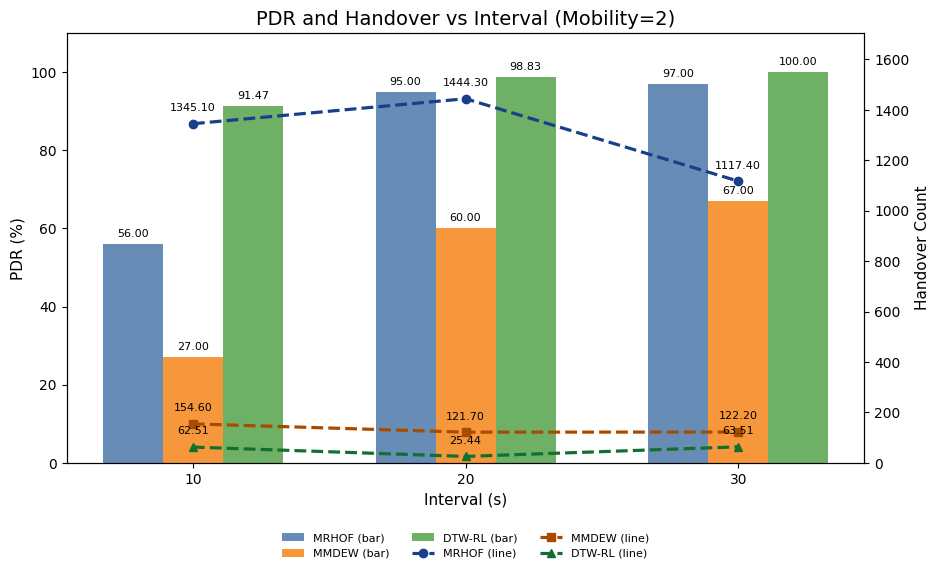

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/01_pdr_ho_mob2.png


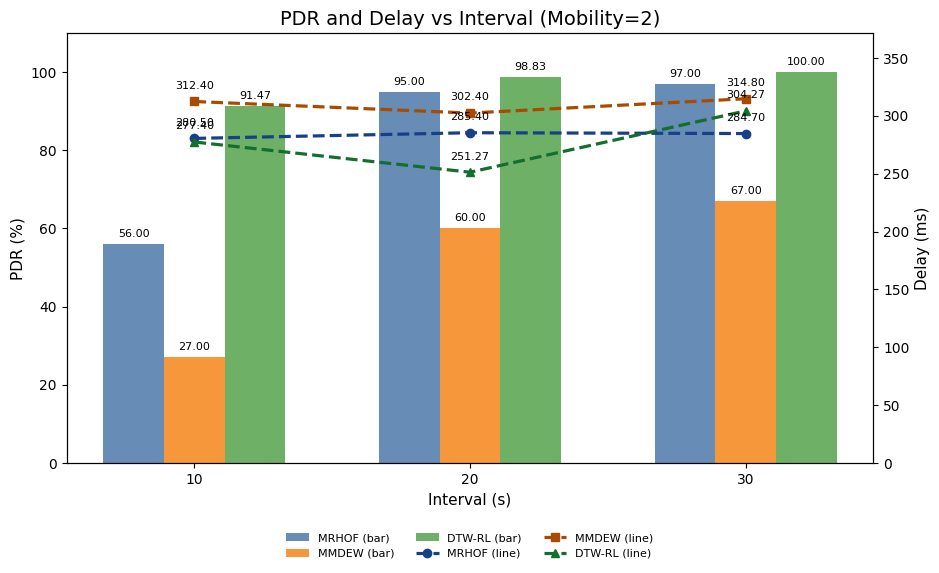

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/02_pdr_delay_mob2.png


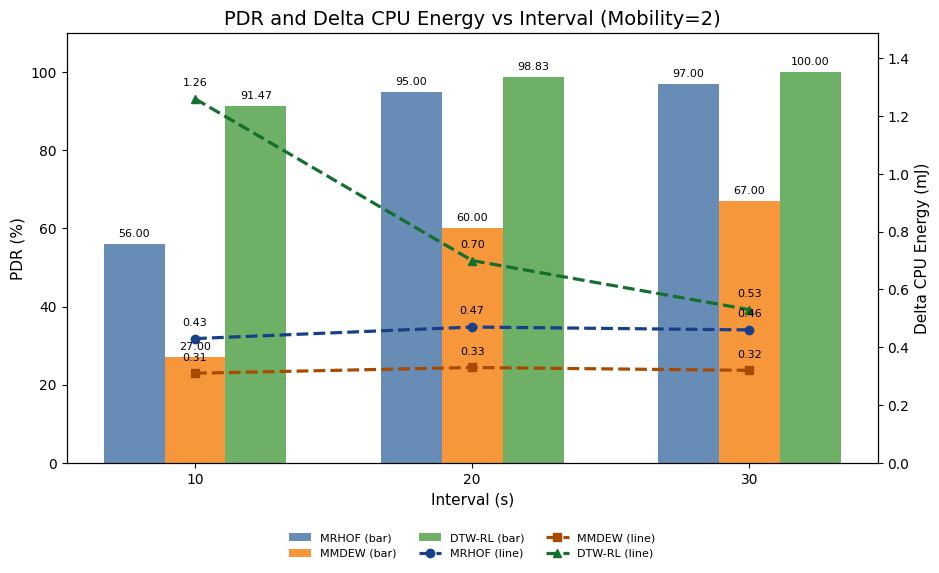

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/03_pdr_delta_cpu_energy_mob2.png


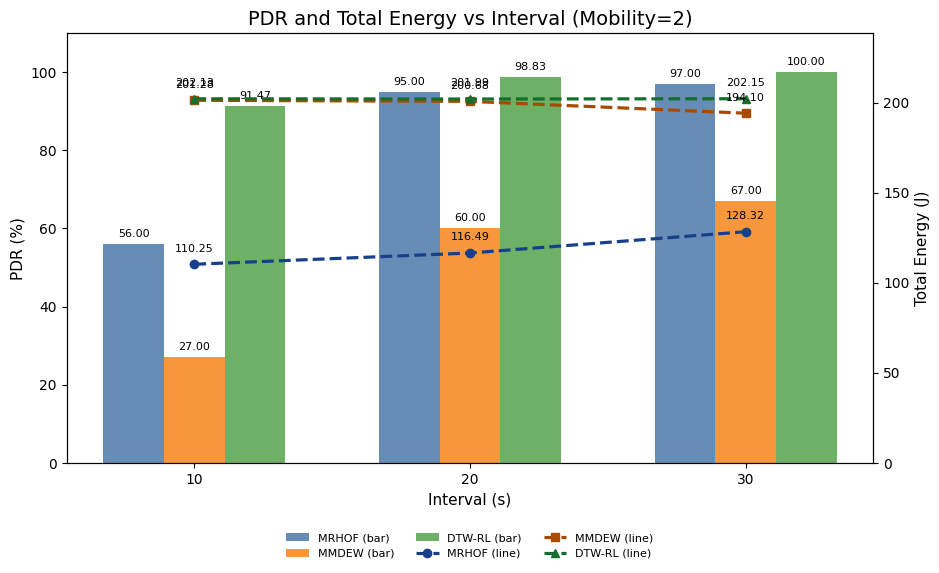

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/04_pdr_total_energy_mob2.png


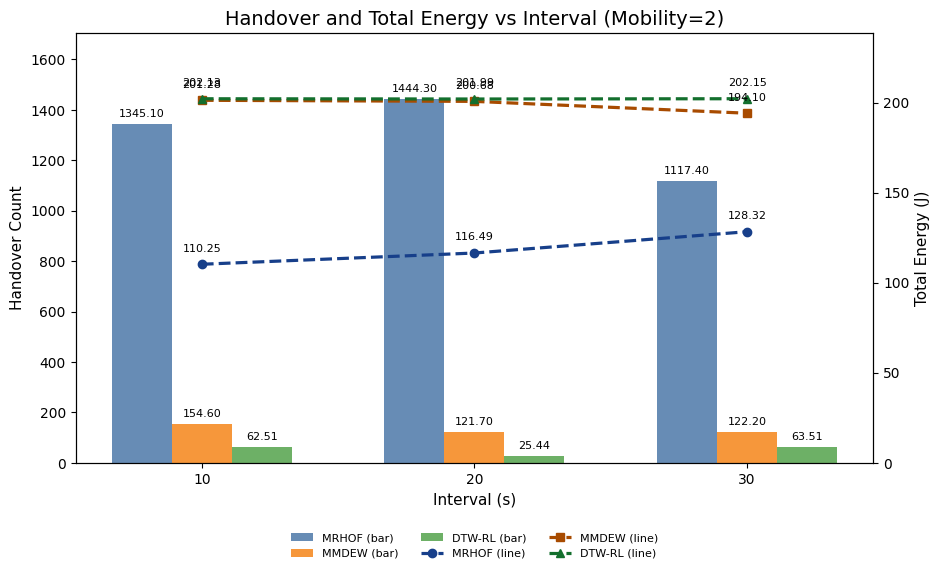

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/05_ho_total_energy_mob2.png


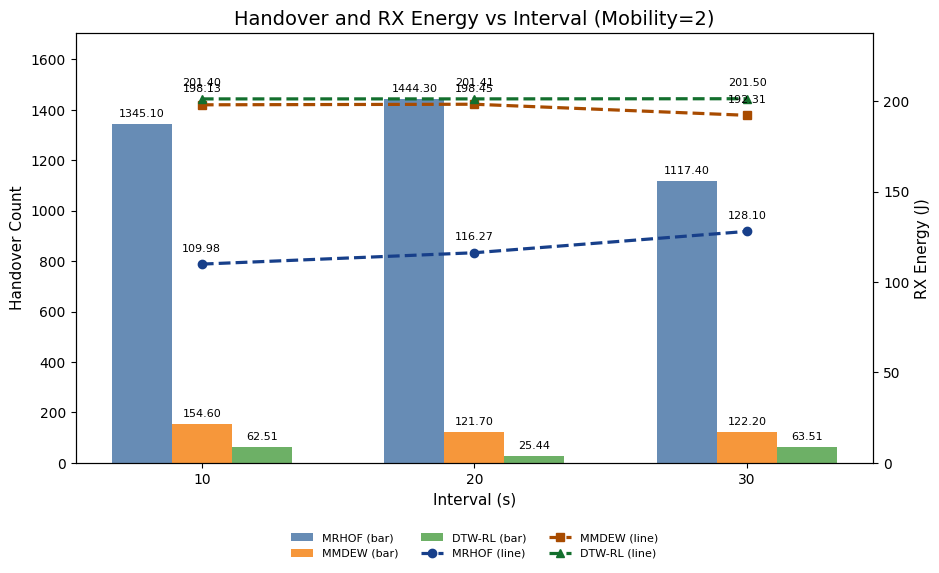

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/06_ho_rx_energy_mob2.png


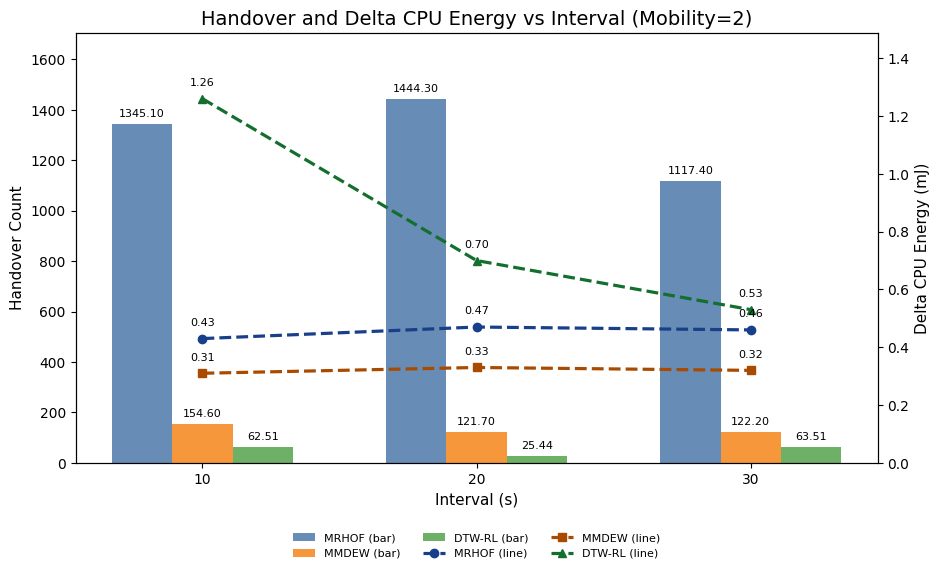

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/07_ho_delta_cpu_energy_mob2.png


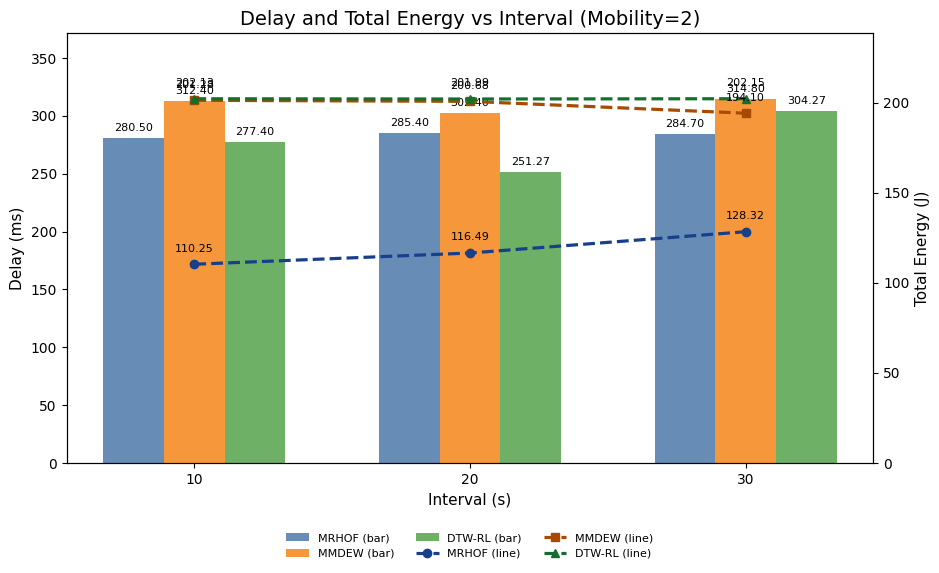

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/08_delay_total_energy_mob2.png


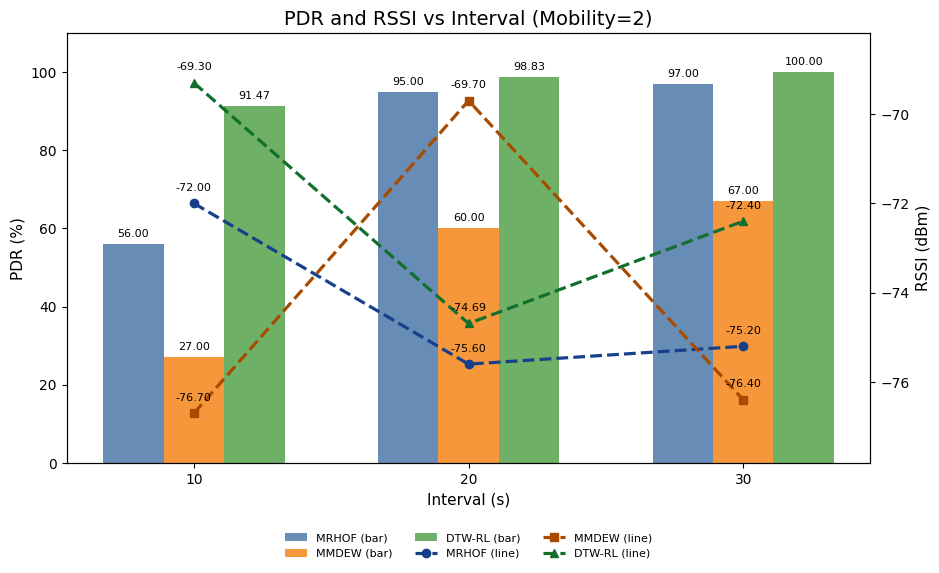

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/09_pdr_rssi_mob2.png


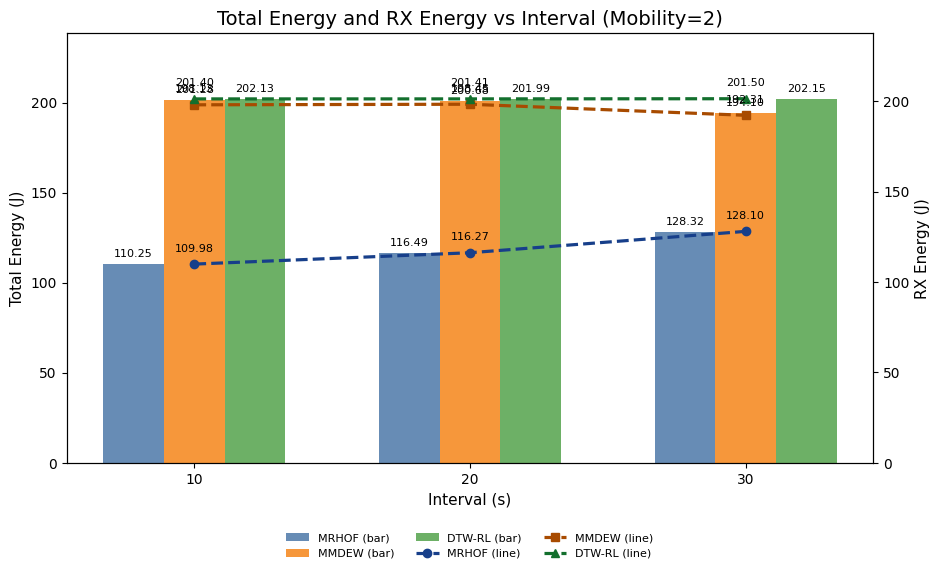

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/10_total_energy_rx_energy_mob2.png


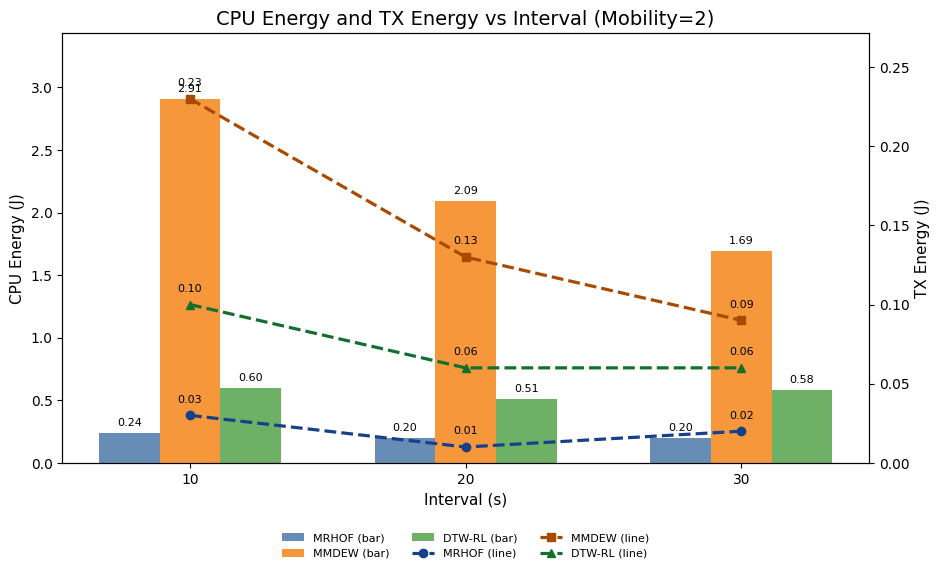

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/11_cpu_tx_energy_mob2.png


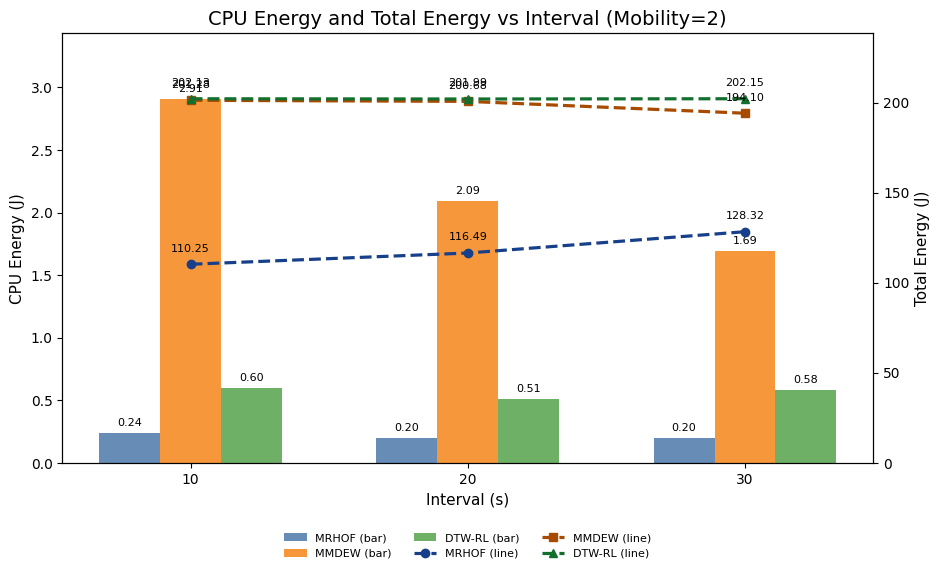

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/12_cpu_total_energy_mob2.png


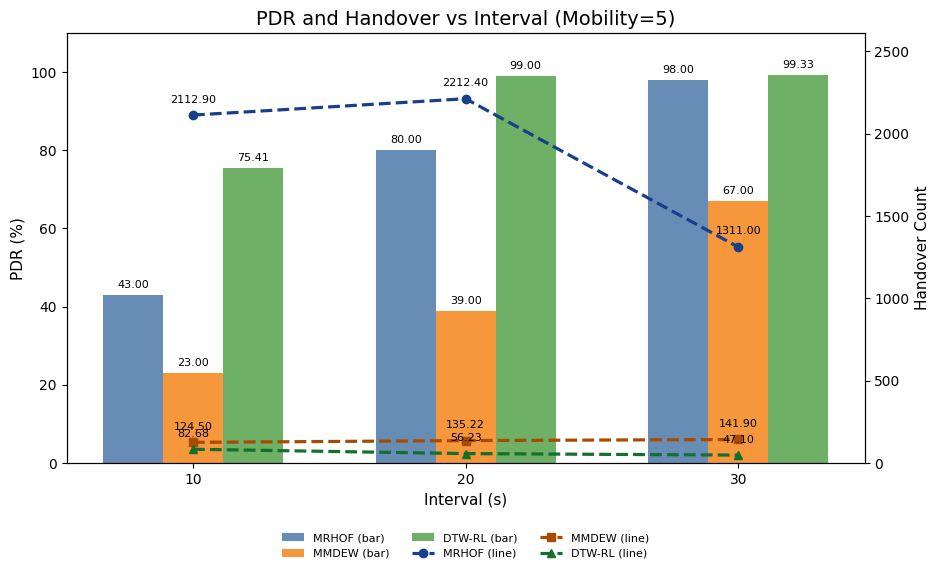

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/01_pdr_ho_mob5.png


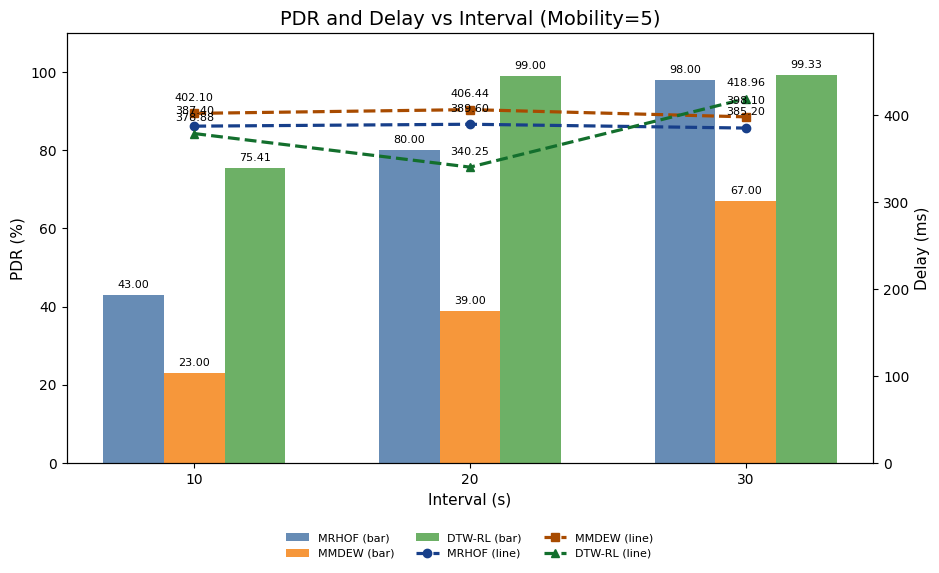

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/02_pdr_delay_mob5.png


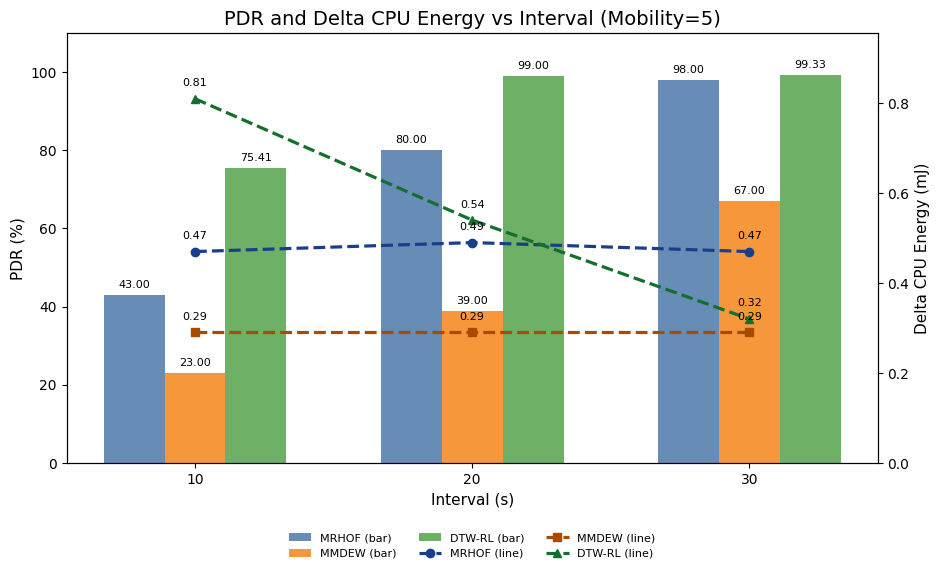

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/03_pdr_delta_cpu_energy_mob5.png


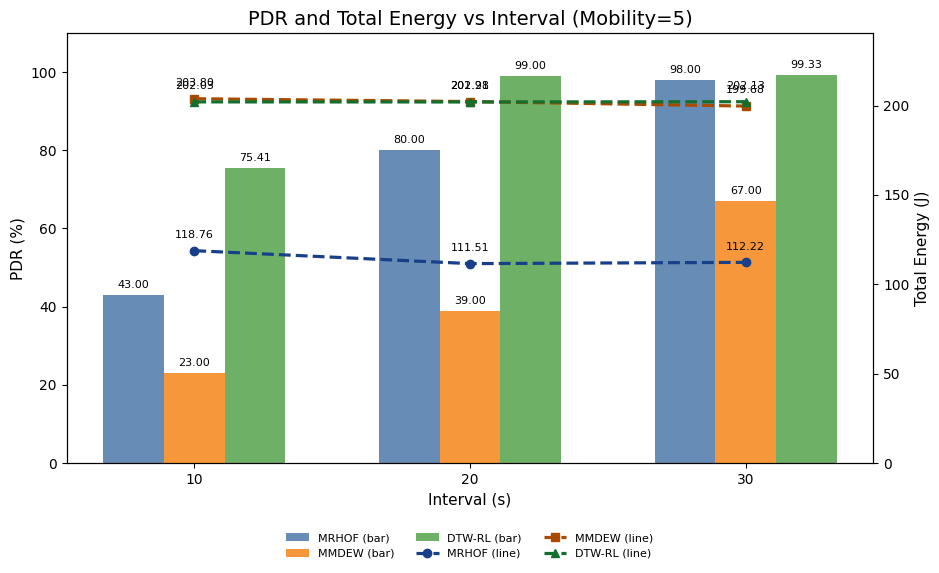

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/04_pdr_total_energy_mob5.png


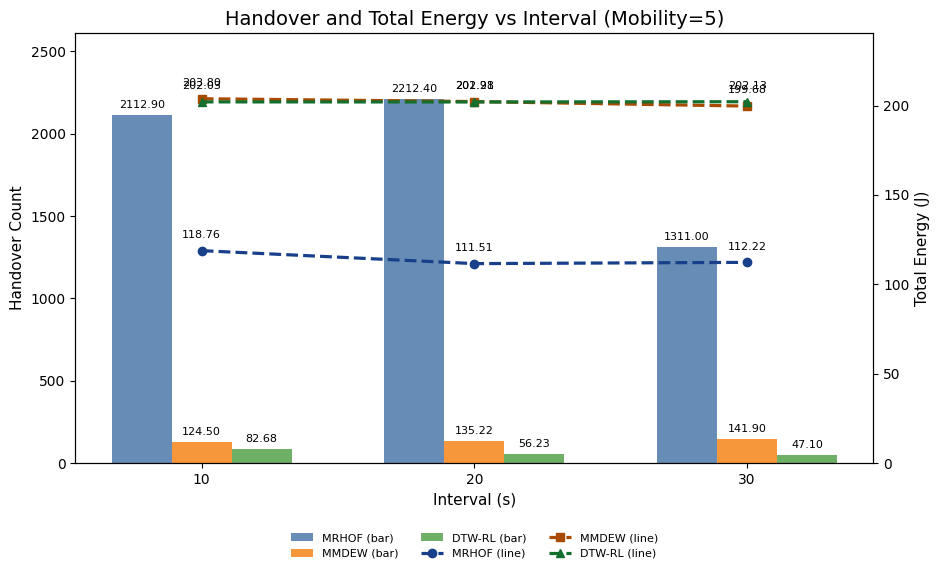

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/05_ho_total_energy_mob5.png


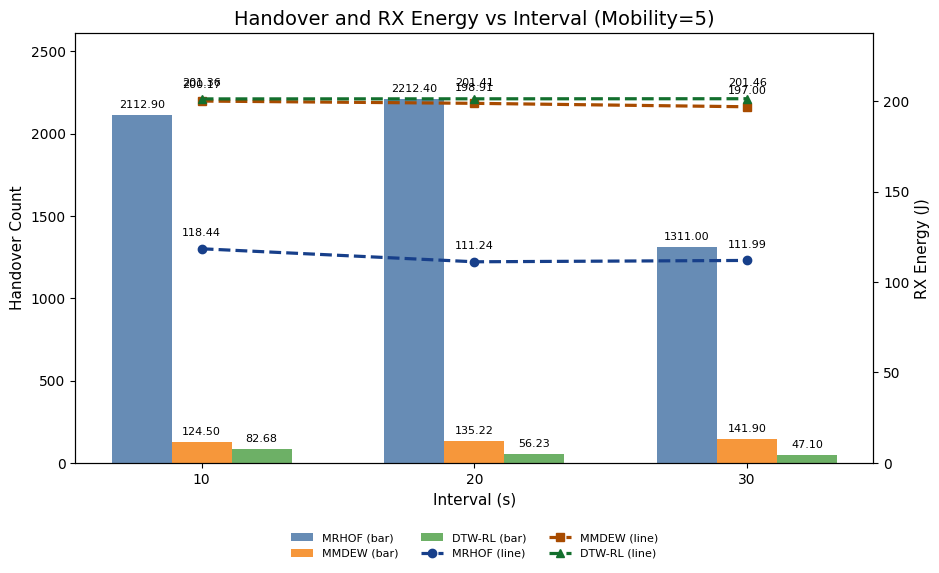

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/06_ho_rx_energy_mob5.png


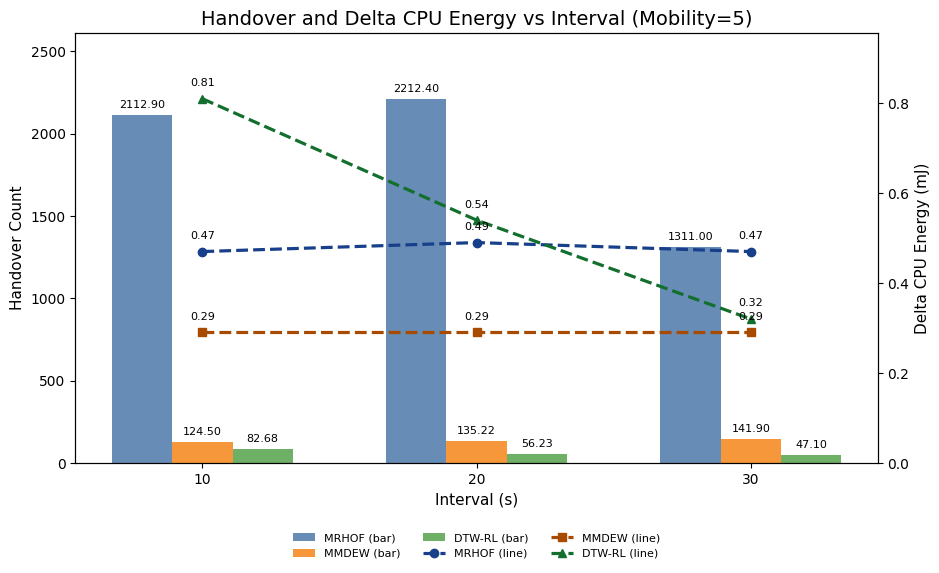

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/07_ho_delta_cpu_energy_mob5.png


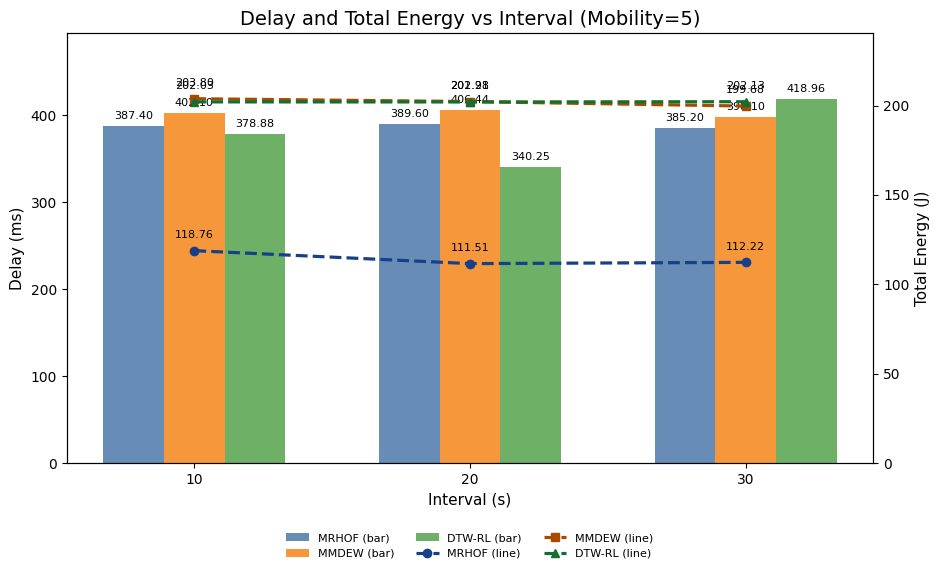

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/08_delay_total_energy_mob5.png


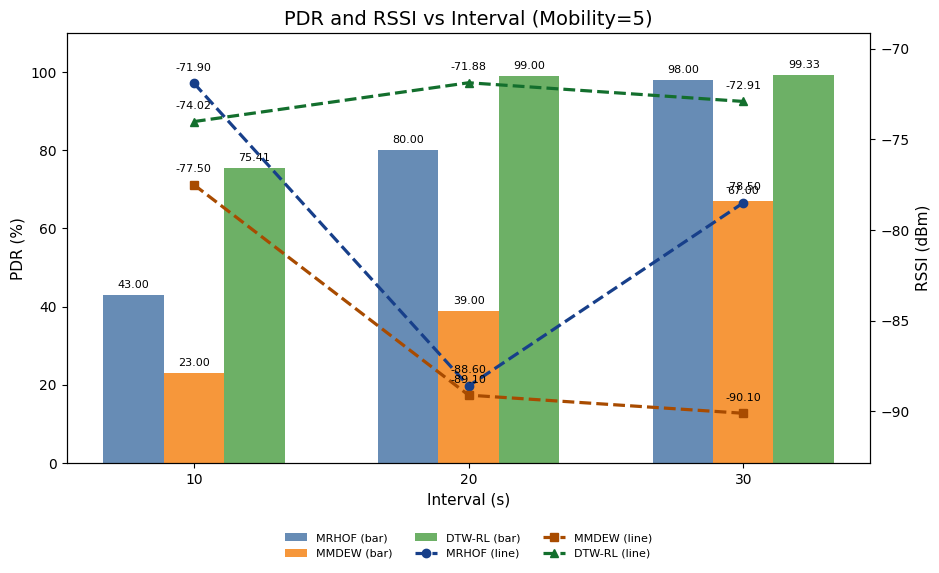

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/09_pdr_rssi_mob5.png


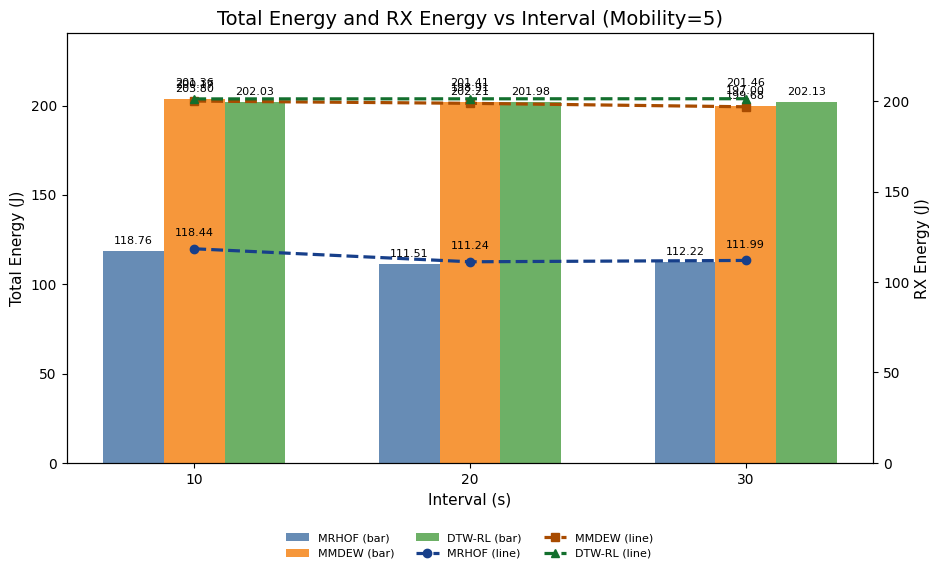

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/10_total_energy_rx_energy_mob5.png


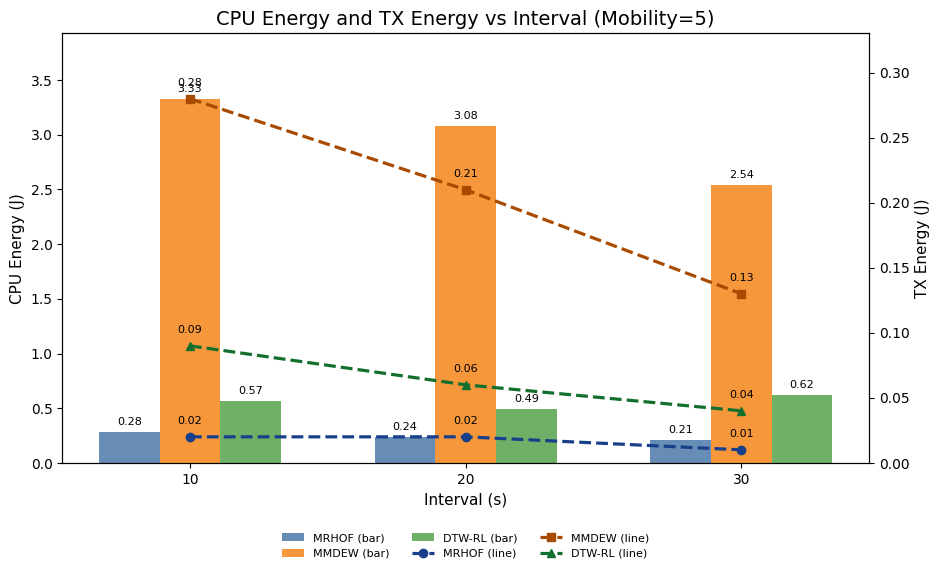

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/11_cpu_tx_energy_mob5.png


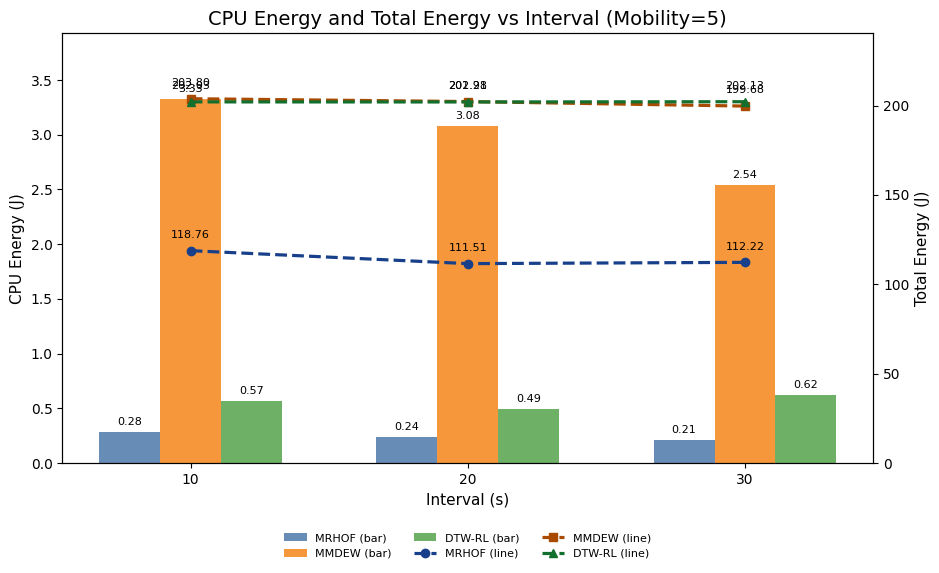

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1/12_cpu_total_energy_mob5.png
All correlation-style bar-line graphs generated in: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1


In [ ]:
# ============================================================
# GRAFIK KORELASI BAR + LINE BERDASARKAN DATA REKAP TERBARU
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

# ============================================================
# OUTPUT FOLDER
# ============================================================
output_dir = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated1"
os.makedirs(output_dir, exist_ok=True)

intervals = [10, 20, 30]
OF_LIST = ["MRHOF", "MMDEW", "DTW-RL"]

# ============================================================
# DATA UTAMA
# ============================================================

pdr_m2 = {
    "MRHOF": [56.00, 95.00, 97.00],
    "MMDEW": [27.00, 60.00, 67.00],
    "DTW-RL": [91.47, 98.83, 100.00],
}

ho_m2 = {
    "MRHOF": [1345.10, 1444.30, 1117.40],
    "MMDEW": [154.60, 121.70, 122.20],
    "DTW-RL": [62.51, 25.44, 63.51],
}

delay_m2 = {
    "MRHOF": [280.50, 285.40, 284.70],
    "MMDEW": [312.40, 302.40, 314.80],
    "DTW-RL": [277.40, 251.27, 304.27],
}

delta_cpu_mj_m2 = {
    "MRHOF": [0.43, 0.47, 0.46],
    "MMDEW": [0.31, 0.33, 0.32],
    "DTW-RL": [1.26, 0.70, 0.53],
}

rssi_m2 = {
    "MRHOF": [-72.00, -75.60, -75.20],
    "MMDEW": [-76.70, -69.70, -76.40],
    "DTW-RL": [-69.30, -74.69, -72.40],
}

cpu_j_m2 = {
    "MRHOF": [0.24, 0.20, 0.20],
    "MMDEW": [2.91, 2.09, 1.69],
    "DTW-RL": [0.60, 0.51, 0.58],
}

tx_j_m2 = {
    "MRHOF": [0.03, 0.01, 0.02],
    "MMDEW": [0.23, 0.13, 0.09],
    "DTW-RL": [0.10, 0.06, 0.06],
}

rx_j_m2 = {
    "MRHOF": [109.98, 116.27, 128.10],
    "MMDEW": [198.13, 198.45, 192.31],
    "DTW-RL": [201.40, 201.41, 201.50],
}

total_energy_j_m2 = {
    "MRHOF": [110.25, 116.49, 128.32],
    "MMDEW": [201.28, 200.68, 194.10],
    "DTW-RL": [202.13, 201.99, 202.15],
}

# ============================================================
# MOBILITY 5
# ============================================================

pdr_m5 = {
    "MRHOF": [43.00, 80.00, 98.00],
    "MMDEW": [23.00, 39.00, 67.00],
    "DTW-RL": [75.41, 99.00, 99.33],
}

ho_m5 = {
    "MRHOF": [2112.90, 2212.40, 1311.00],
    "MMDEW": [124.50, 135.22, 141.90],
    "DTW-RL": [82.68, 56.23, 47.10],
}

delay_m5 = {
    "MRHOF": [387.40, 389.60, 385.20],
    "MMDEW": [402.10, 406.44, 398.10],
    "DTW-RL": [378.88, 340.25, 418.96],
}

delta_cpu_mj_m5 = {
    "MRHOF": [0.47, 0.49, 0.47],
    "MMDEW": [0.29, 0.29, 0.29],
    "DTW-RL": [0.81, 0.54, 0.32],
}

rssi_m5 = {
    "MRHOF": [-71.90, -88.60, -78.50],
    "MMDEW": [-77.50, -89.10, -90.10],
    "DTW-RL": [-74.02, -71.88, -72.91],
}

cpu_j_m5 = {
    "MRHOF": [0.28, 0.24, 0.21],
    "MMDEW": [3.33, 3.08, 2.54],
    "DTW-RL": [0.57, 0.49, 0.62],
}

tx_j_m5 = {
    "MRHOF": [0.02, 0.02, 0.01],
    "MMDEW": [0.28, 0.21, 0.13],
    "DTW-RL": [0.09, 0.06, 0.04],
}

rx_j_m5 = {
    "MRHOF": [118.44, 111.24, 111.99],
    "MMDEW": [200.17, 198.91, 197.00],
    "DTW-RL": [201.36, 201.41, 201.46],
}

total_energy_j_m5 = {
    "MRHOF": [118.76, 111.51, 112.22],
    "MMDEW": [203.80, 202.21, 199.68],
    "DTW-RL": [202.03, 201.98, 202.13],
}

# ============================================================
# STYLE
# ============================================================

BAR_COLORS = {
    "MRHOF": "#4C78A8",
    "MMDEW": "#F58518",
    "DTW-RL": "#54A24B",
}

LINE_COLORS = {
    "MRHOF": "#173F8A",
    "MMDEW": "#A84B00",
    "DTW-RL": "#136F2D",
}

MARKERS = {
    "MRHOF": "o",
    "MMDEW": "s",
    "DTW-RL": "^",
}

plt.rcParams.update({
    "figure.figsize": (9.5, 6.0),
    "axes.grid": False,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 8,
    "font.size": 10,
})

# ============================================================
# HELPER
# ============================================================

def add_bar_labels(ax, bars, fmt="{:.2f}", y_offset_ratio=0.012, fontsize=8):
    y_min, y_max = ax.get_ylim()
    offset = (y_max - y_min) * y_offset_ratio

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + offset,
            fmt.format(height),
            ha="center",
            va="bottom",
            fontsize=fontsize
        )

def add_line_labels(ax, x, y, fmt="{:.2f}", y_offset_ratio=0.025, fontsize=8):
    y_min, y_max = ax.get_ylim()
    offset = (y_max - y_min) * y_offset_ratio

    for xi, yi in zip(x, y):
      ax.text(
            xi,
            yi + offset,
            fmt.format(yi),
            ha="center",
            va="bottom",
            fontsize=fontsize
        )

def auto_ylim_positive(metric_dict, pad_ratio=0.18):
    all_values = []
    for of in OF_LIST:
        all_values.extend(metric_dict[of])
    vmax = max(all_values)
    return 0, vmax * (1 + pad_ratio)

def auto_ylim_any(metric_dict, pad_ratio=0.15):
    all_values = []
    for of in OF_LIST:
        all_values.extend(metric_dict[of])
    vmin = min(all_values)
    vmax = max(all_values)
    span = vmax - vmin
    return vmin - span * pad_ratio, vmax + span * pad_ratio

# ============================================================
# CORE FUNCTION: BAR + LINE DUAL AXIS
# ============================================================

def plot_bar_line(
    bar_metric,
    line_metric,
    title,
    ylabel_bar,
    ylabel_line,
    filename,
    bar_ylim=None,
    line_ylim=None,
    bar_fmt="{:.2f}",
    line_fmt="{:.2f}",
    show_grid=False,
    show_line_labels=False
):
    x = np.arange(len(intervals))
    width = 0.22

    fig, ax1 = plt.subplots(figsize=(9.5, 6.0))

    # ---------------- BAR ----------------
    bars = {}
    bars["MRHOF"] = ax1.bar(
        x - width,
        bar_metric["MRHOF"],
        width,
        label="MRHOF (bar)",
        color=BAR_COLORS["MRHOF"],
        alpha=0.85
    )

    bars["MMDEW"] = ax1.bar(
        x,
        bar_metric["MMDEW"],
        width,
        label="MMDEW (bar)",
        color=BAR_COLORS["MMDEW"],
        alpha=0.85
    )

    bars["DTW-RL"] = ax1.bar(
        x + width,
        bar_metric["DTW-RL"],
        width,
        label="DTW-RL (bar)",
        color=BAR_COLORS["DTW-RL"],
        alpha=0.85
    )

    ax1.set_xlabel("Interval (s)")
    ax1.set_ylabel(ylabel_bar)
    ax1.set_xticks(x)
    ax1.set_xticklabels(intervals)

    if bar_ylim is not None:
        ax1.set_ylim(*bar_ylim)

    for of in OF_LIST:
        add_bar_labels(ax1, bars[of], fmt=bar_fmt)

    # ---------------- LINE ----------------
    ax2 = ax1.twinx()

    for of in OF_LIST:
        ax2.plot(
            x,
            line_metric[of],
            marker=MARKERS[of],
            linestyle="--",
            linewidth=2.3,
            color=LINE_COLORS[of],
            label=f"{of} (line)"
        )

    ax2.set_ylabel(ylabel_line)

    if line_ylim is not None:
        ax2.set_ylim(*line_ylim)

    for of in OF_LIST:
        add_line_labels(ax2, x, line_metric[of], fmt=line_fmt)

    # ---------------- LEGEND ----------------
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.14),
        ncol=3,
        fontsize=8,
        frameon=False
    )

    if show_grid:
        ax1.grid(axis="y", alpha=0.25)

    plt.title(title)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.22)

    save_path = os.path.join(output_dir, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)

# ============================================================
# RECOMMENDED CORRELATION-STYLE GRAPHS
# ============================================================

def generate_all_correlation_graphs(
    mobility_label,
    pdr,
    ho,
    delay,
    rssi,
    delta_cpu_mj,
    cpu_j,
    tx_j,
    rx_j,
    total_energy_j
):
    mob = f"Mobility={mobility_label}"
    suffix = f"mob{mobility_label}"

    # 1. PDR vs HO
    plot_bar_line(
        pdr, ho,
        f"PDR and Handover vs Interval ({mob})",
        "PDR (%)", "Handover Count",
        f"01_pdr_ho_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(ho),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 2. PDR vs Delay
    plot_bar_line(
        pdr, delay,
        f"PDR and Delay vs Interval ({mob})",
        "PDR (%)", "Delay (ms)",
        f"02_pdr_delay_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(delay),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 3. PDR vs Delta CPU Energy
    plot_bar_line(
        pdr, delta_cpu_mj,
        f"PDR and Delta CPU Energy vs Interval ({mob})",
        "PDR (%)", "Delta CPU Energy (mJ)",
        f"03_pdr_delta_cpu_energy_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(delta_cpu_mj),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 4. PDR vs Total Energy
    plot_bar_line(
        pdr, total_energy_j,
        f"PDR and Total Energy vs Interval ({mob})",
        "PDR (%)", "Total Energy (J)",
        f"04_pdr_total_energy_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(total_energy_j),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 5. HO vs Total Energy
    plot_bar_line(
        ho, total_energy_j,
        f"Handover and Total Energy vs Interval ({mob})",
        "Handover Count", "Total Energy (J)",
        f"05_ho_total_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(ho),
        line_ylim=auto_ylim_positive(total_energy_j),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 6. HO vs RX Energy
    plot_bar_line(
        ho, rx_j,
        f"Handover and RX Energy vs Interval ({mob})",
        "Handover Count", "RX Energy (J)",
        f"06_ho_rx_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(ho),
        line_ylim=auto_ylim_positive(rx_j),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 7. HO vs Delta CPU Energy
    plot_bar_line(
        ho, delta_cpu_mj,
        f"Handover and Delta CPU Energy vs Interval ({mob})",
        "Handover Count", "Delta CPU Energy (mJ)",
        f"07_ho_delta_cpu_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(ho),
        line_ylim=auto_ylim_positive(delta_cpu_mj),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 8. Delay vs Total Energy
    plot_bar_line(
        delay, total_energy_j,
        f"Delay and Total Energy vs Interval ({mob})",
        "Delay (ms)", "Total Energy (J)",
        f"08_delay_total_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(delay),
        line_ylim=auto_ylim_positive(total_energy_j),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 9. RSSI vs PDR
    # Catatan: RSSI bernilai negatif, jadi lebih aman RSSI sebagai line.
    plot_bar_line(
        pdr, rssi,
        f"PDR and RSSI vs Interval ({mob})",
        "PDR (%)", "RSSI (dBm)",
        f"09_pdr_rssi_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_any(rssi),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 10. Total Energy vs RX Energy
    plot_bar_line(
        total_energy_j, rx_j,
        f"Total Energy and RX Energy vs Interval ({mob})",
        "Total Energy (J)", "RX Energy (J)",
        f"10_total_energy_rx_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(total_energy_j),
        line_ylim=auto_ylim_positive(rx_j),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 11. CPU Energy vs TX Energy
    plot_bar_line(
        cpu_j, tx_j,
        f"CPU Energy and TX Energy vs Interval ({mob})",
        "CPU Energy (J)", "TX Energy (J)",
        f"11_cpu_tx_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(cpu_j),
        line_ylim=auto_ylim_positive(tx_j),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

    # 12. CPU Energy vs Total Energy
    plot_bar_line(
        cpu_j, total_energy_j,
        f"CPU Energy and Total Energy vs Interval ({mob})",
        "CPU Energy (J)", "Total Energy (J)",
        f"12_cpu_total_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(cpu_j),
        line_ylim=auto_ylim_positive(total_energy_j),
        bar_fmt="{:.2f}",
        line_fmt="{:.2f}"
    )

# ============================================================
# GENERATE MOBILITY 2 AND 5
# ============================================================

generate_all_correlation_graphs(
    mobility_label=2,
    pdr=pdr_m2,
    ho=ho_m2,
    delay=delay_m2,
    rssi=rssi_m2,
    delta_cpu_mj=delta_cpu_mj_m2,
    cpu_j=cpu_j_m2,
    tx_j=tx_j_m2,
    rx_j=rx_j_m2,
    total_energy_j=total_energy_j_m2
)

generate_all_correlation_graphs(
    mobility_label=5,
    pdr=pdr_m5,
    ho=ho_m5,
    delay=delay_m5,
    rssi=rssi_m5,
    delta_cpu_mj=delta_cpu_mj_m5,
    cpu_j=cpu_j_m5,
    tx_j=tx_j_m5,
    rx_j=rx_j_m5,
    total_energy_j=total_energy_j_m5
)

print("All correlation-style bar-line graphs generated in:", output_dir)

Lagi untuk Korelasi

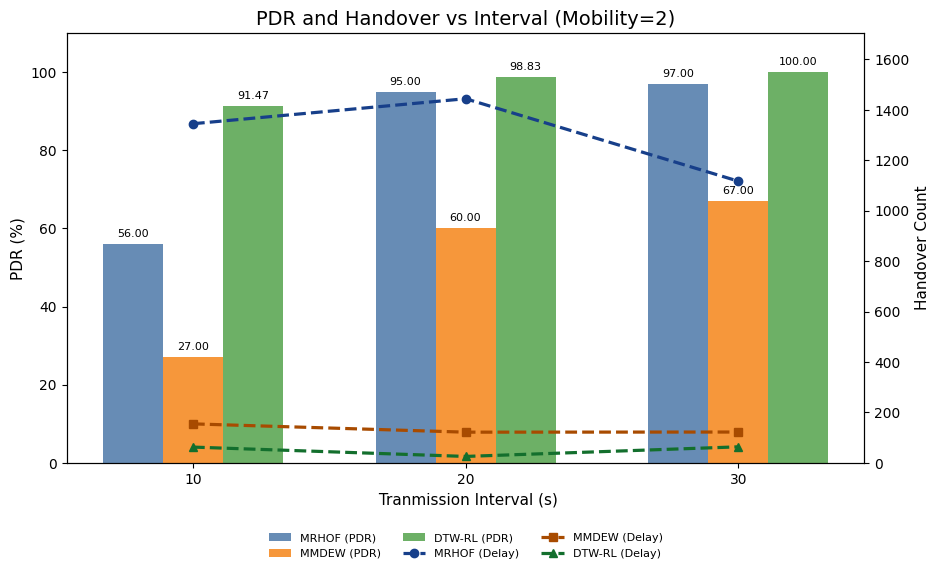

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/01_pdr_ho_mob2.png


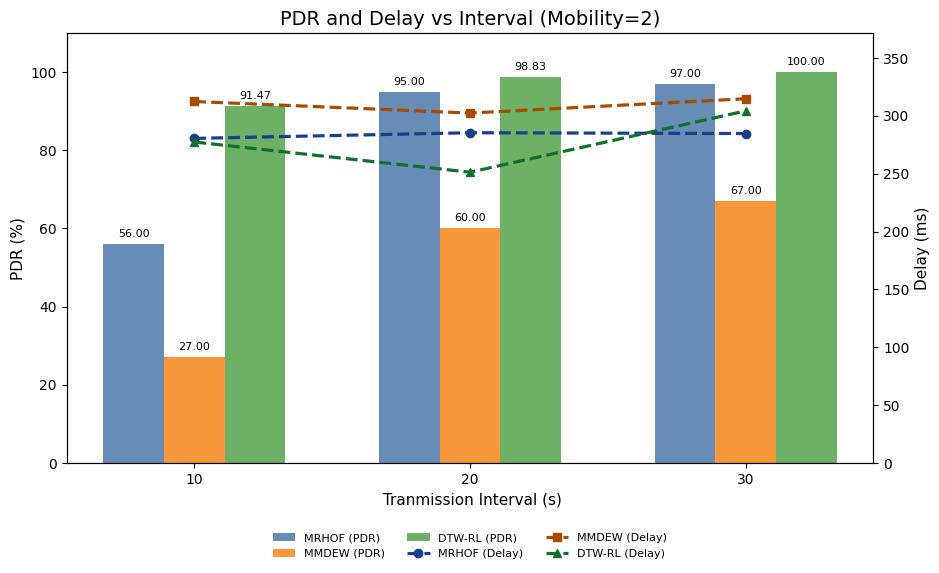

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/02_pdr_delay_mob2.png


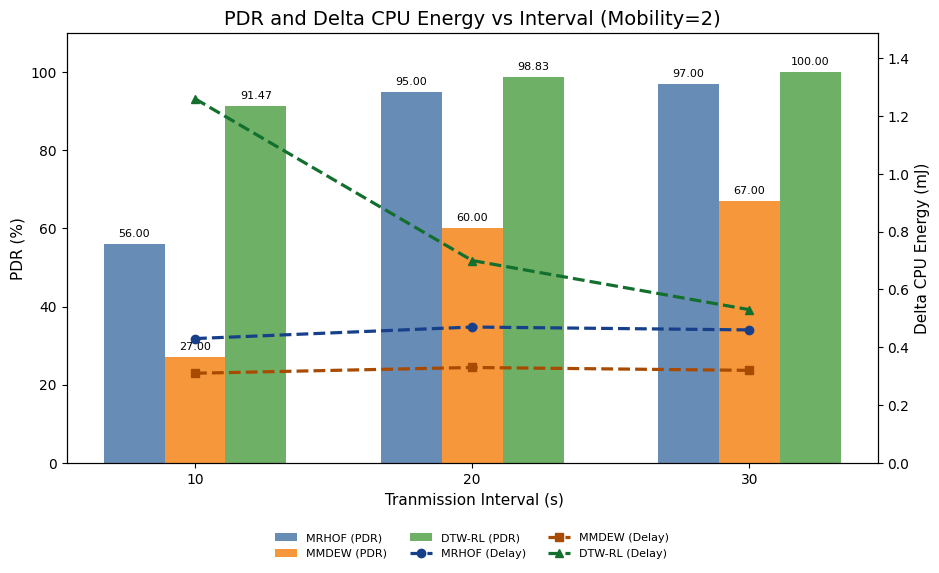

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/03_pdr_delta_cpu_energy_mob2.png


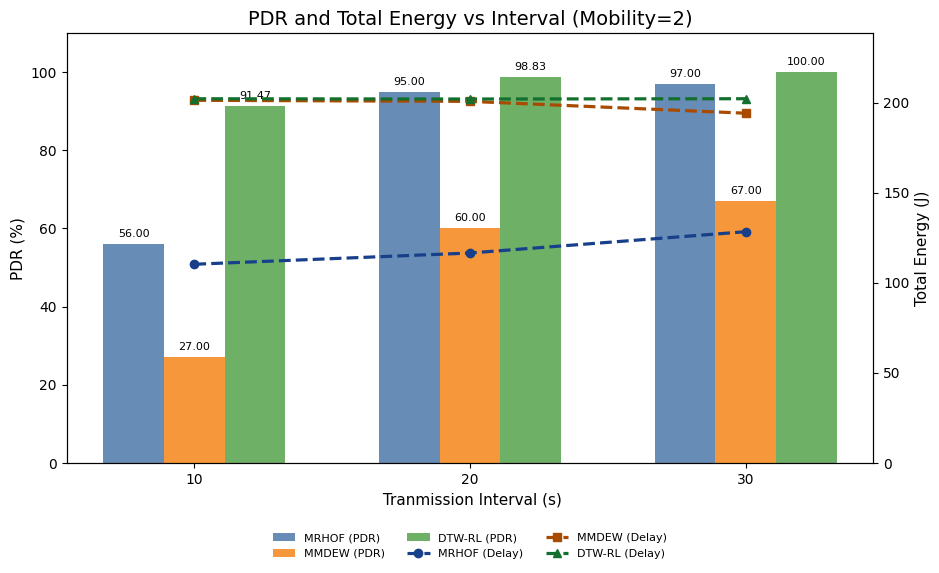

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/04_pdr_total_energy_mob2.png


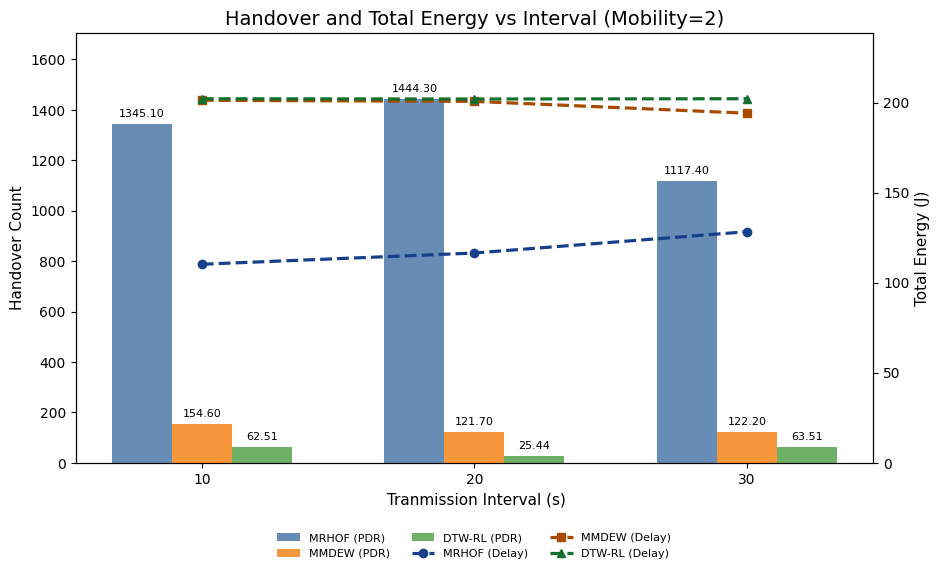

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/05_ho_total_energy_mob2.png


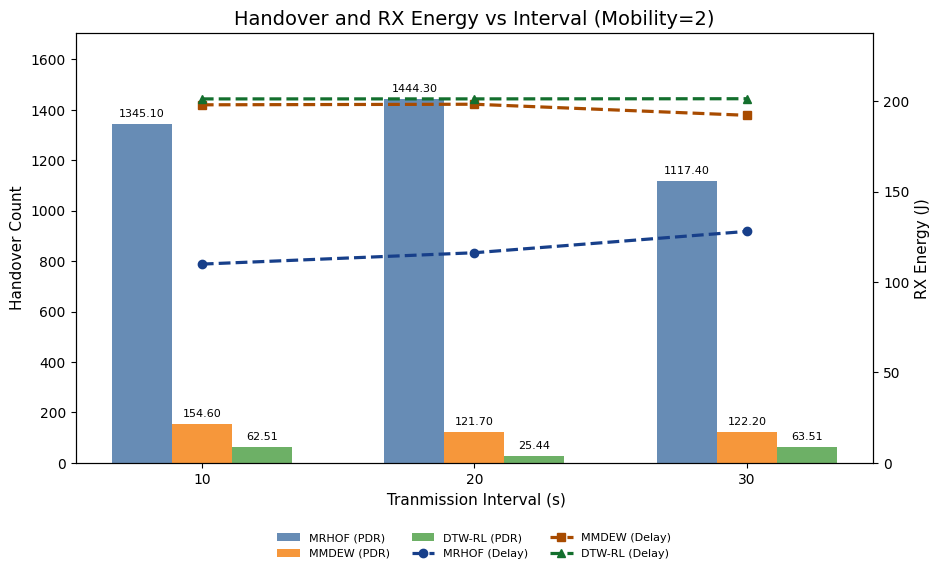

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/06_ho_rx_energy_mob2.png


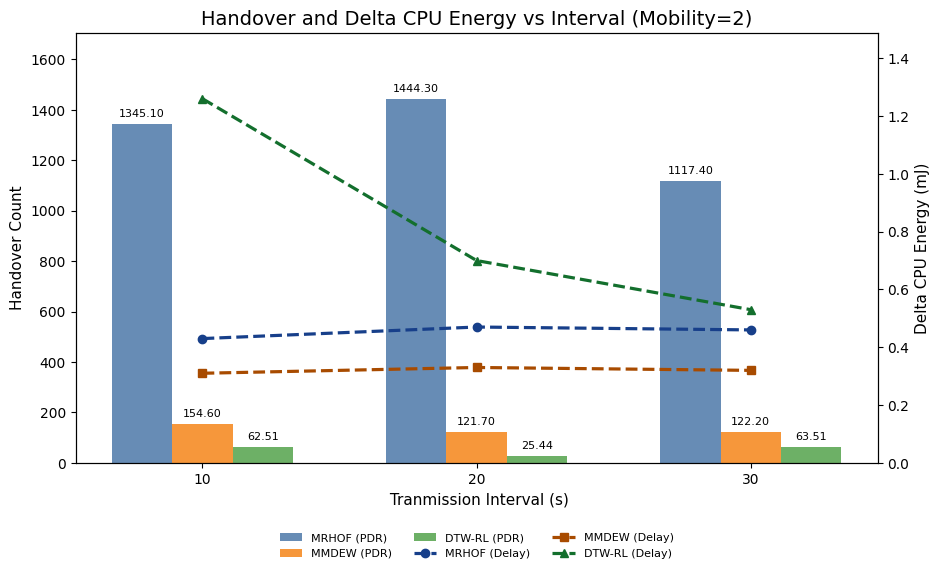

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/07_ho_delta_cpu_energy_mob2.png


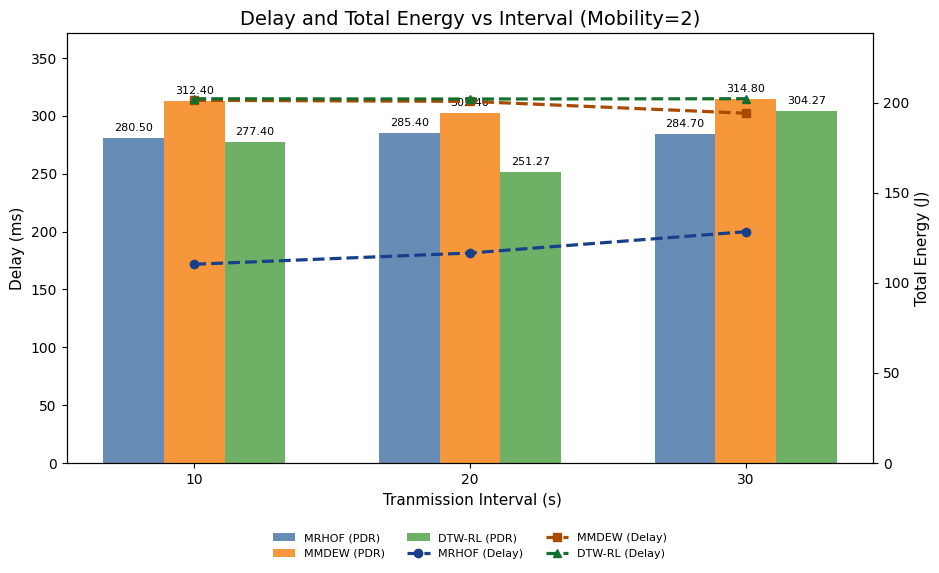

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/08_delay_total_energy_mob2.png


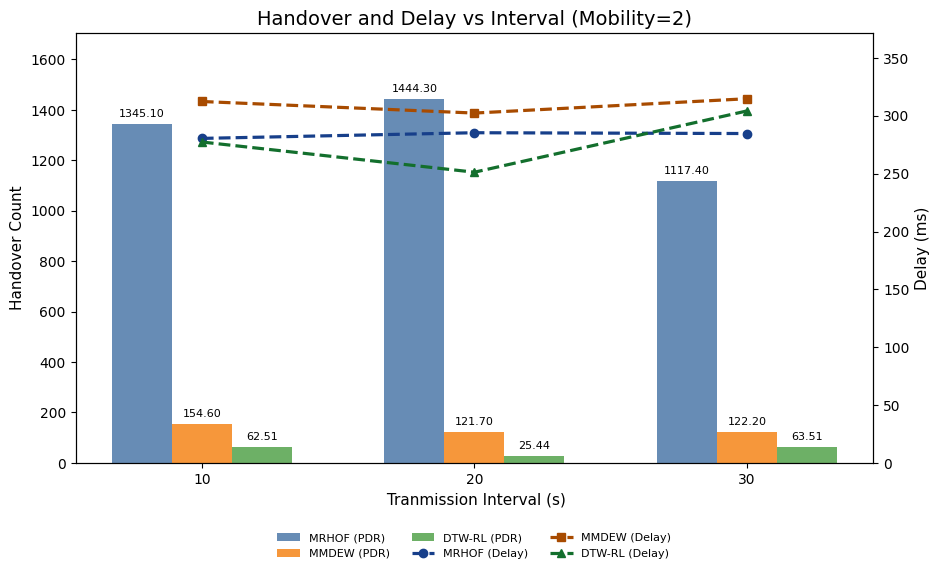

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/09_ho_delay_mob2.png


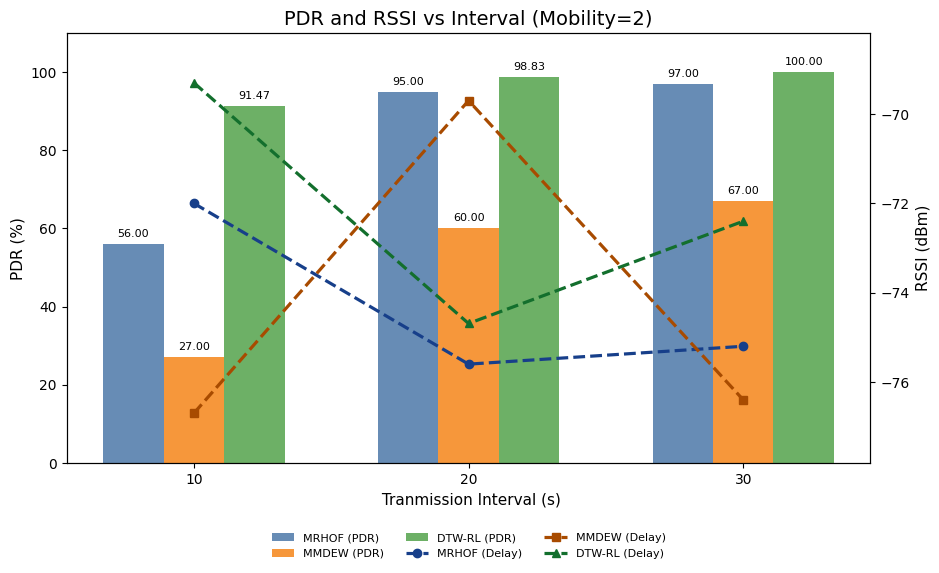

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/10_pdr_rssi_mob2.png


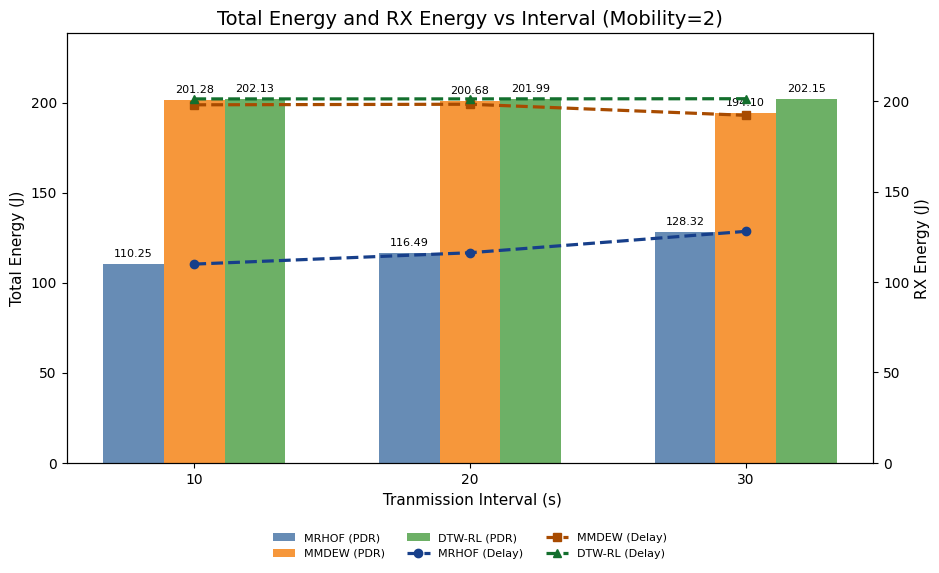

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/11_total_energy_rx_energy_mob2.png


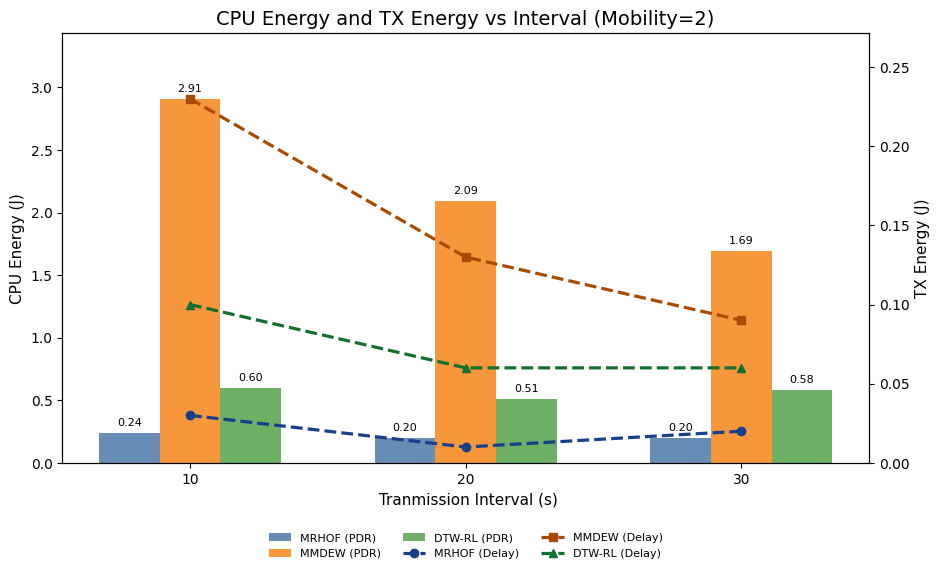

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/12_cpu_tx_energy_mob2.png


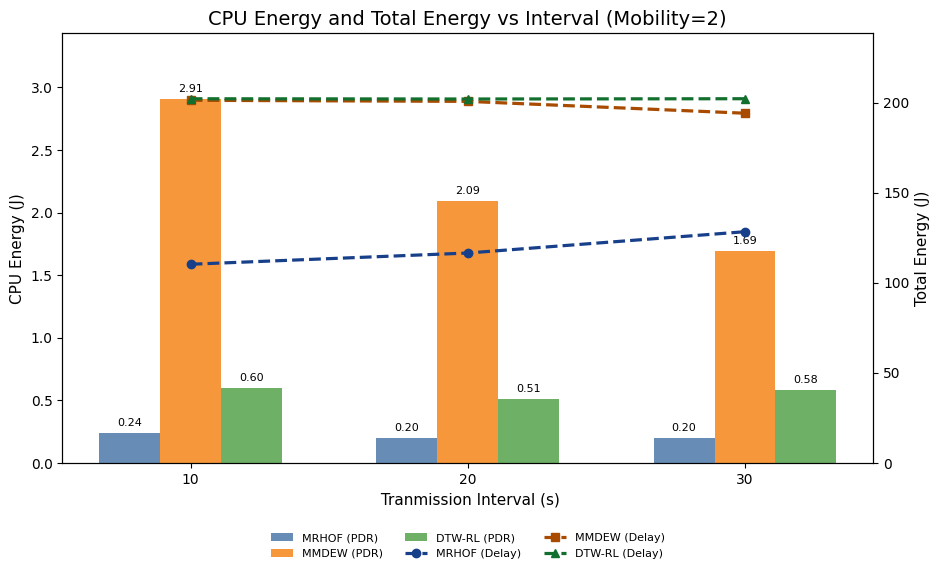

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/13_cpu_total_energy_mob2.png


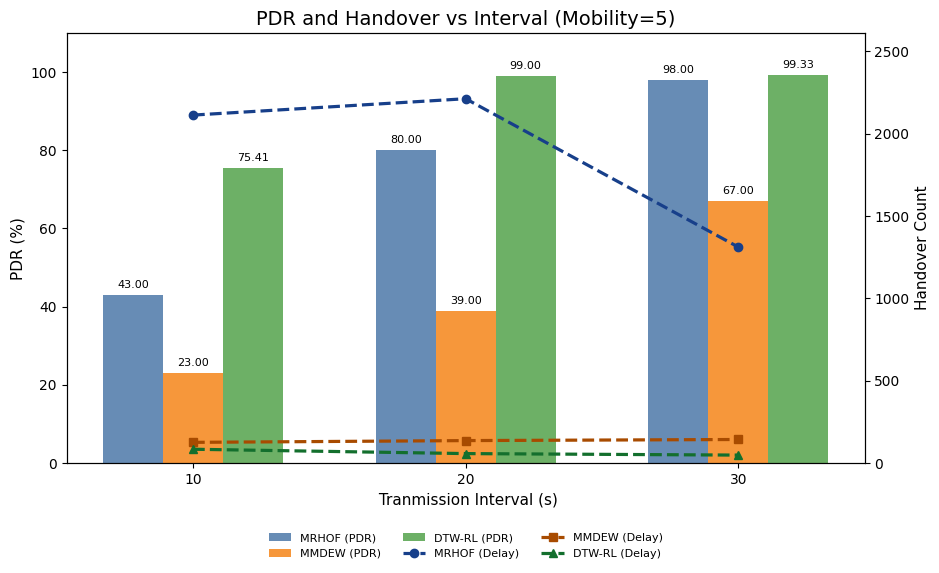

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/01_pdr_ho_mob5.png


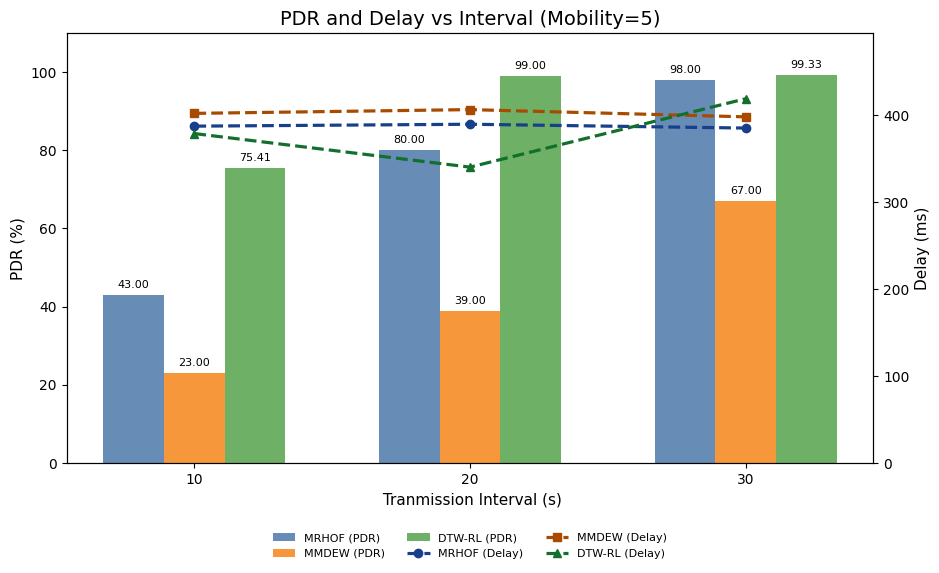

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/02_pdr_delay_mob5.png


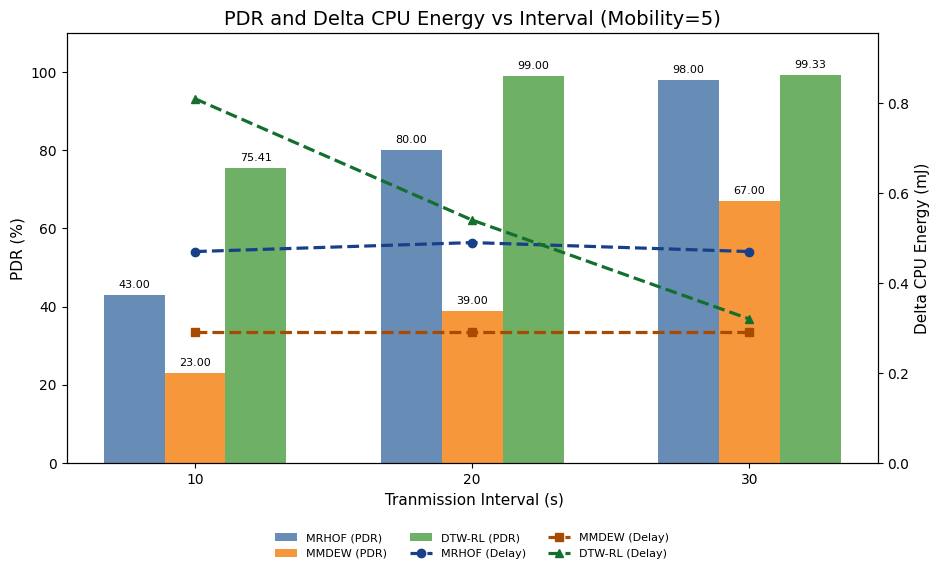

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/03_pdr_delta_cpu_energy_mob5.png


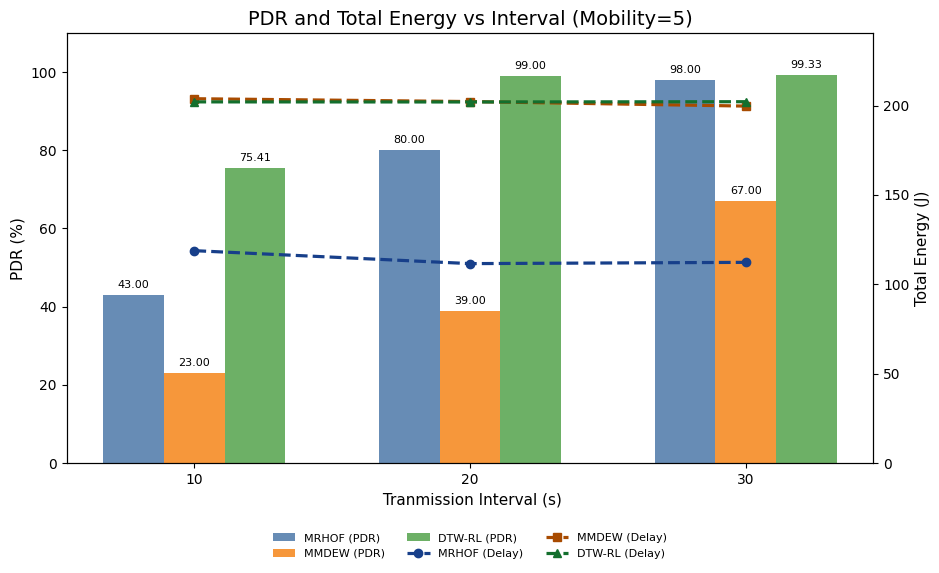

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/04_pdr_total_energy_mob5.png


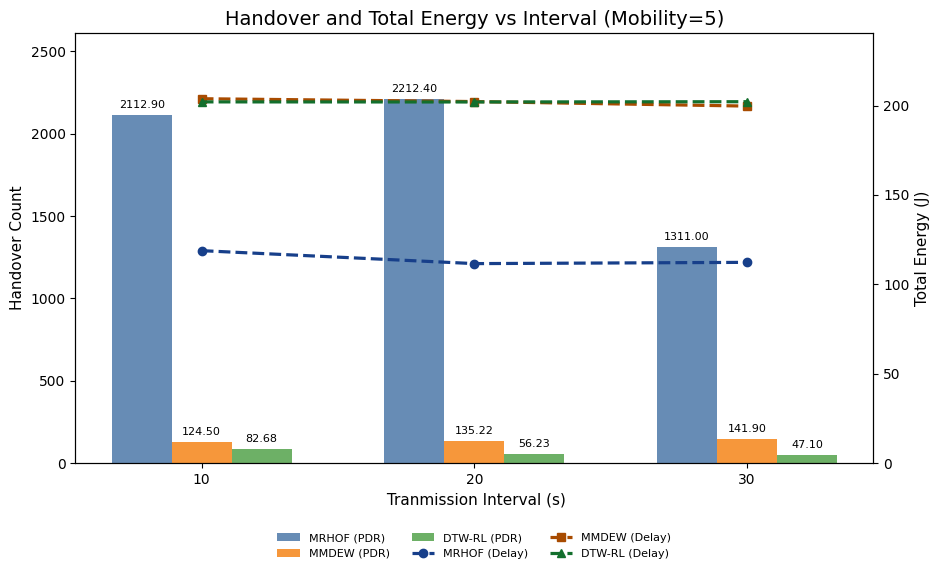

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/05_ho_total_energy_mob5.png


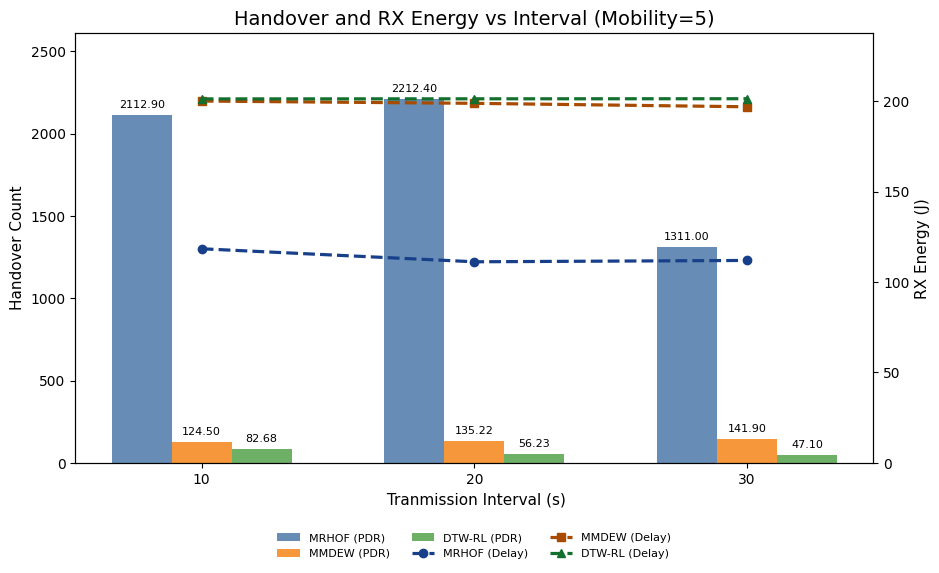

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/06_ho_rx_energy_mob5.png


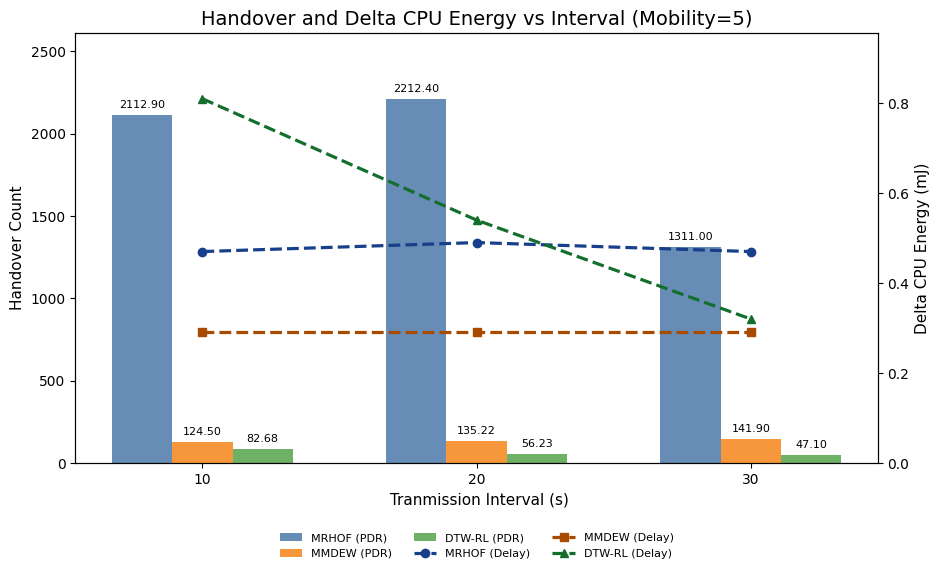

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/07_ho_delta_cpu_energy_mob5.png


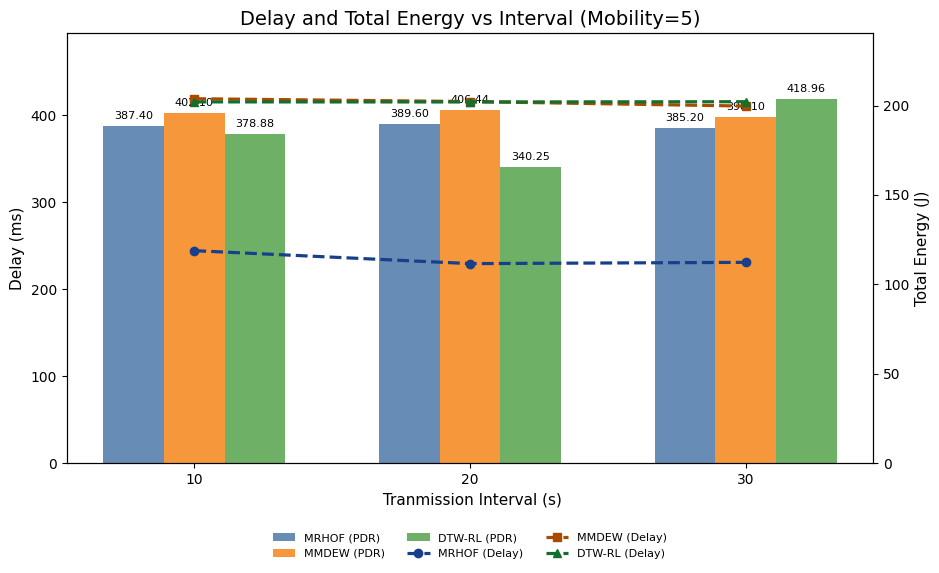

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/08_delay_total_energy_mob5.png


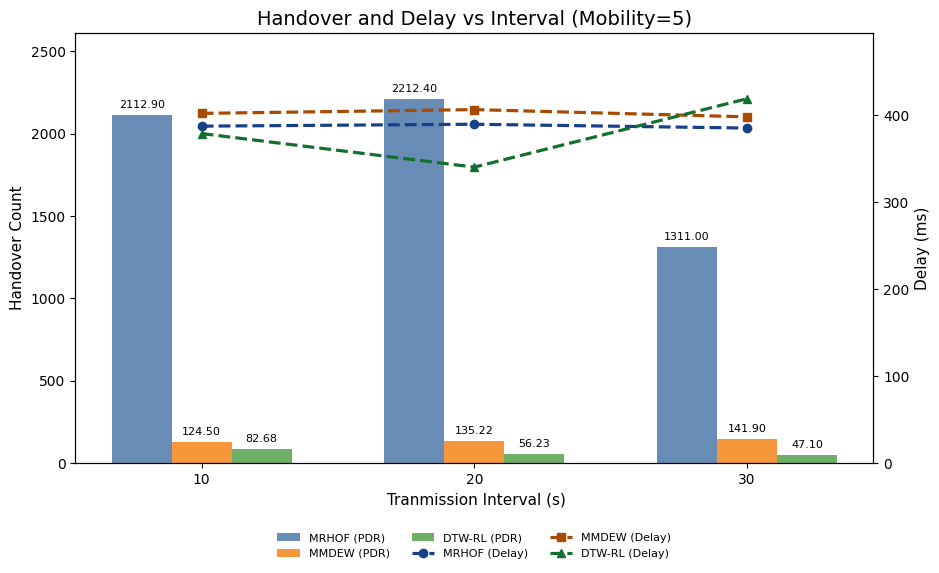

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/09_ho_delay_mob5.png


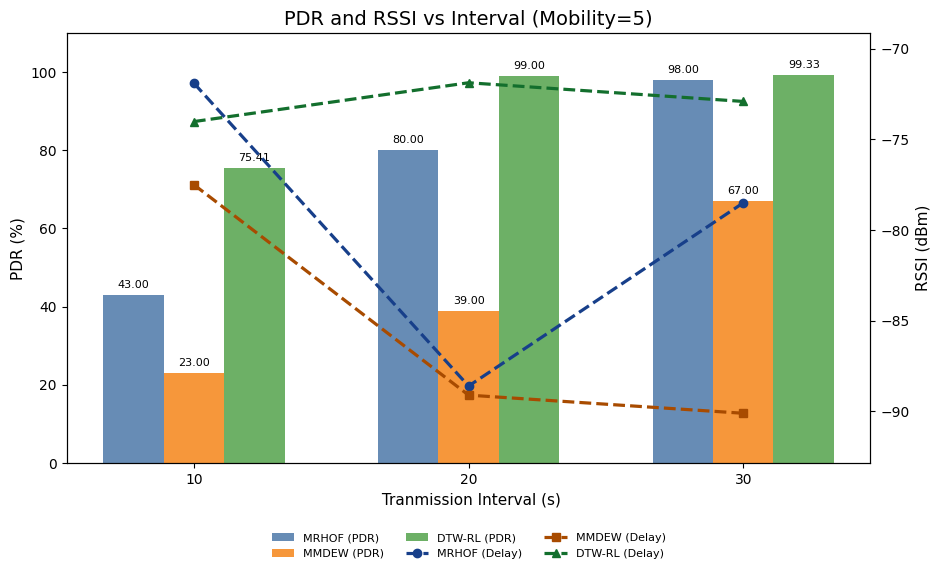

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/10_pdr_rssi_mob5.png


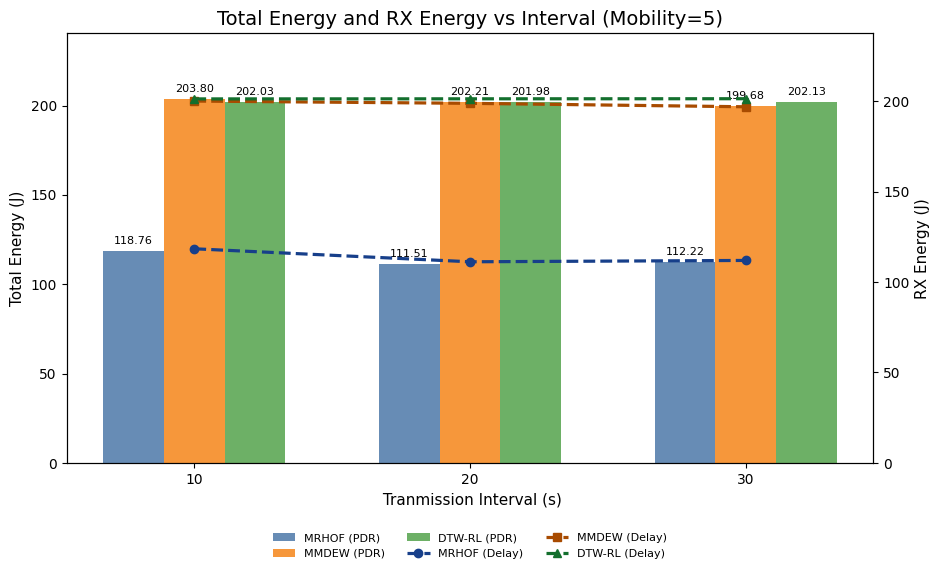

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/11_total_energy_rx_energy_mob5.png


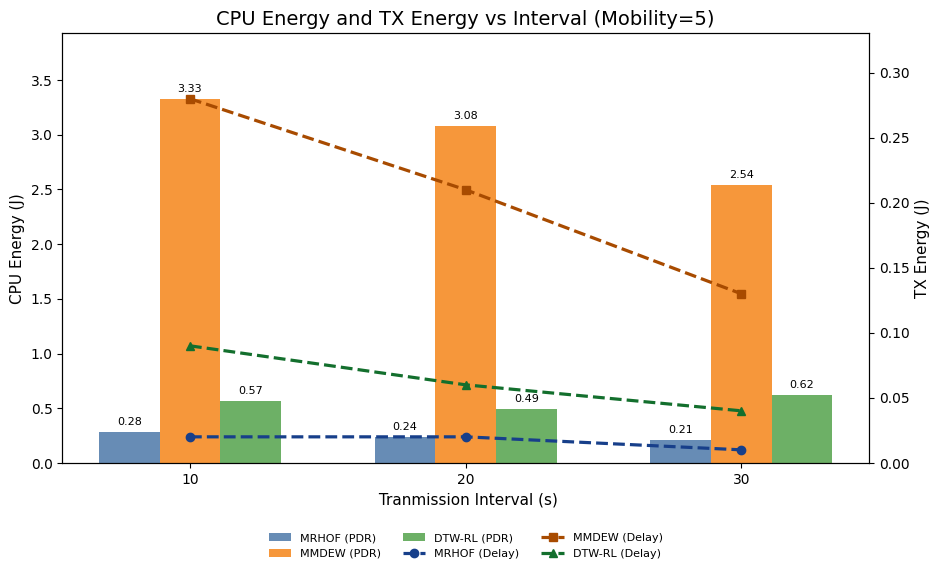

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/12_cpu_tx_energy_mob5.png


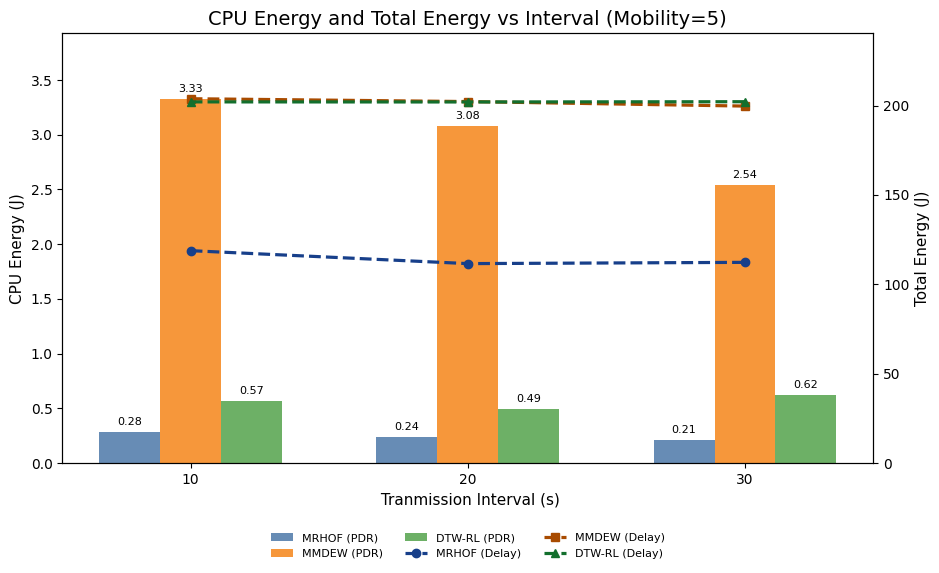

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3/13_cpu_total_energy_mob5.png
All correlation-style bar-line graphs generated in: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3


In [ ]:
# ============================================================
# GRAFIK KORELASI BAR + LINE BERDASARKAN DATA REKAP TERBARU
# BAR = metrik utama
# LINE = metrik pembanding
# Catatan:
# - Angka hanya ditampilkan pada BAR
# - LINE hanya marker + legend agar grafik tidak terlalu penuh
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

# ============================================================
# OUTPUT FOLDER
# ============================================================

output_dir = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_updated3"
os.makedirs(output_dir, exist_ok=True)

intervals = [10, 20, 30]
OF_LIST = ["MRHOF", "MMDEW", "DTW-RL"]

# ============================================================
# DATA UTAMA - MOBILITY 2
# ============================================================

pdr_m2 = {
    "MRHOF": [56.00, 95.00, 97.00],
    "MMDEW": [27.00, 60.00, 67.00],
    "DTW-RL": [91.47, 98.83, 100.00],
}

ho_m2 = {
    "MRHOF": [1345.10, 1444.30, 1117.40],
    "MMDEW": [154.60, 121.70, 122.20],
    "DTW-RL": [62.51, 25.44, 63.51],
}

delay_m2 = {
    "MRHOF": [280.50, 285.40, 284.70],
    "MMDEW": [312.40, 302.40, 314.80],
    "DTW-RL": [277.40, 251.27, 304.27],
}

delta_cpu_mj_m2 = {
    "MRHOF": [0.43, 0.47, 0.46],
    "MMDEW": [0.31, 0.33, 0.32],
    "DTW-RL": [1.26, 0.70, 0.53],
}

rssi_m2 = {
    "MRHOF": [-72.00, -75.60, -75.20],
    "MMDEW": [-76.70, -69.70, -76.40],
    "DTW-RL": [-69.30, -74.69, -72.40],
}

cpu_j_m2 = {
    "MRHOF": [0.24, 0.20, 0.20],
    "MMDEW": [2.91, 2.09, 1.69],
    "DTW-RL": [0.60, 0.51, 0.58],
}

tx_j_m2 = {
    "MRHOF": [0.03, 0.01, 0.02],
    "MMDEW": [0.23, 0.13, 0.09],
    "DTW-RL": [0.10, 0.06, 0.06],
}

rx_j_m2 = {
    "MRHOF": [109.98, 116.27, 128.10],
    "MMDEW": [198.13, 198.45, 192.31],
    "DTW-RL": [201.40, 201.41, 201.50],
}

total_energy_j_m2 = {
    "MRHOF": [110.25, 116.49, 128.32],
    "MMDEW": [201.28, 200.68, 194.10],
    "DTW-RL": [202.13, 201.99, 202.15],
}

# ============================================================
# DATA UTAMA - MOBILITY 5
# ============================================================

pdr_m5 = {
    "MRHOF": [43.00, 80.00, 98.00],
    "MMDEW": [23.00, 39.00, 67.00],
    "DTW-RL": [75.41, 99.00, 99.33],
}

ho_m5 = {
    "MRHOF": [2112.90, 2212.40, 1311.00],
    "MMDEW": [124.50, 135.22, 141.90],
    "DTW-RL": [82.68, 56.23, 47.10],
}

delay_m5 = {
    "MRHOF": [387.40, 389.60, 385.20],
    "MMDEW": [402.10, 406.44, 398.10],
    "DTW-RL": [378.88, 340.25, 418.96],
}

delta_cpu_mj_m5 = {
    "MRHOF": [0.47, 0.49, 0.47],
    "MMDEW": [0.29, 0.29, 0.29],
    "DTW-RL": [0.81, 0.54, 0.32],
}

rssi_m5 = {
    "MRHOF": [-71.90, -88.60, -78.50],
    "MMDEW": [-77.50, -89.10, -90.10],
    "DTW-RL": [-74.02, -71.88, -72.91],
}

cpu_j_m5 = {
    "MRHOF": [0.28, 0.24, 0.21],
    "MMDEW": [3.33, 3.08, 2.54],
    "DTW-RL": [0.57, 0.49, 0.62],
}

tx_j_m5 = {
    "MRHOF": [0.02, 0.02, 0.01],
    "MMDEW": [0.28, 0.21, 0.13],
    "DTW-RL": [0.09, 0.06, 0.04],
}

rx_j_m5 = {
    "MRHOF": [118.44, 111.24, 111.99],
    "MMDEW": [200.17, 198.91, 197.00],
    "DTW-RL": [201.36, 201.41, 201.46],
}

total_energy_j_m5 = {
    "MRHOF": [118.76, 111.51, 112.22],
    "MMDEW": [203.80, 202.21, 199.68],
    "DTW-RL": [202.03, 201.98, 202.13],
}

# ============================================================
# STYLE
# ============================================================

BAR_COLORS = {
    "MRHOF": "#4C78A8",
    "MMDEW": "#F58518",
    "DTW-RL": "#54A24B",
}

LINE_COLORS = {
    "MRHOF": "#173F8A",
    "MMDEW": "#A84B00",
    "DTW-RL": "#136F2D",
}

MARKERS = {
    "MRHOF": "o",
    "MMDEW": "s",
    "DTW-RL": "^",
}

plt.rcParams.update({
    "figure.figsize": (9.5, 6.0),
    "axes.grid": False,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 8,
    "font.size": 10,
})

# ============================================================
# HELPER
# ============================================================

def add_bar_labels(ax, bars, fmt="{:.2f}", y_offset_ratio=0.012, fontsize=8):
    y_min, y_max = ax.get_ylim()
    offset = (y_max - y_min) * y_offset_ratio

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + offset,
            fmt.format(height),
            ha="center",
            va="bottom",
            fontsize=fontsize
        )


def add_line_labels(ax, x, y, fmt="{:.2f}", y_offset_ratio=0.025, fontsize=8):
    y_min, y_max = ax.get_ylim()
    offset = (y_max - y_min) * y_offset_ratio

    for xi, yi in zip(x, y):
        ax.text(
            xi,
            yi + offset,
            fmt.format(yi),
            ha="center",
            va="bottom",
            fontsize=fontsize,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.0)
        )


def auto_ylim_positive(metric_dict, pad_ratio=0.18):
    all_values = []
    for of in OF_LIST:
        all_values.extend(metric_dict[of])

    vmax = max(all_values)
    return 0, vmax * (1 + pad_ratio)


def auto_ylim_any(metric_dict, pad_ratio=0.15):
    all_values = []
    for of in OF_LIST:
        all_values.extend(metric_dict[of])

    vmin = min(all_values)
    vmax = max(all_values)
    span = vmax - vmin

    if span == 0:
        return vmin - 1, vmax + 1

    return vmin - span * pad_ratio, vmax + span * pad_ratio


# ============================================================
# CORE FUNCTION: BAR + LINE DUAL AXIS
# ============================================================

def plot_bar_line(
    bar_metric,
    line_metric,
    title,
    ylabel_bar,
    ylabel_line,
    filename,
    bar_ylim=None,
    line_ylim=None,
    bar_fmt="{:.2f}",
    line_fmt="{:.2f}",
    show_grid=False,
    show_line_labels=False
):
    x = np.arange(len(intervals))
    width = 0.22

    fig, ax1 = plt.subplots(figsize=(9.5, 6.0))

    # ---------------- BAR ----------------
    bars = {}

    bars["MRHOF"] = ax1.bar(
        x - width,
        bar_metric["MRHOF"],
        width,
        label="MRHOF (PDR)",
        color=BAR_COLORS["MRHOF"],
        alpha=0.85
    )

    bars["MMDEW"] = ax1.bar(
        x,
        bar_metric["MMDEW"],
        width,
        label="MMDEW (PDR)",
        color=BAR_COLORS["MMDEW"],
        alpha=0.85
    )

    bars["DTW-RL"] = ax1.bar(
        x + width,
        bar_metric["DTW-RL"],
        width,
        label="DTW-RL (PDR)",
        color=BAR_COLORS["DTW-RL"],
        alpha=0.85
    )

    ax1.set_xlabel(" Tranmission Interval (s)")
    ax1.set_ylabel(ylabel_bar)
    ax1.set_xticks(x)
    ax1.set_xticklabels(intervals)

    if bar_ylim is not None:
        ax1.set_ylim(*bar_ylim)

    for of in OF_LIST:
        add_bar_labels(ax1, bars[of], fmt=bar_fmt)

    # ---------------- LINE ----------------
    ax2 = ax1.twinx()

    for of in OF_LIST:
        ax2.plot(
            x,
            line_metric[of],
            marker=MARKERS[of],
            linestyle="--",
            linewidth=2.3,
            color=LINE_COLORS[of],
            label=f"{of} (Delay)"
        )

    ax2.set_ylabel(ylabel_line)

    if line_ylim is not None:
        ax2.set_ylim(*line_ylim)

    if show_line_labels:
        for of in OF_LIST:
            add_line_labels(
                ax2,
                x,
                line_metric[of],
                fmt=line_fmt
            )

    # ---------------- LEGEND ----------------
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.14),
        ncol=3,
        fontsize=8,
        frameon=False
    )

    if show_grid:
        ax1.grid(axis="y", alpha=0.25)

    plt.title(title)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.22)

    save_path = os.path.join(output_dir, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)


# ============================================================
# GENERATOR: SEMUA GRAFIK KORELASI BAR + LINE
# ============================================================

def generate_all_correlation_graphs(
    mobility_label,
    pdr,
    ho,
    delay,
    rssi,
    delta_cpu_mj,
    cpu_j,
    tx_j,
    rx_j,
    total_energy_j
):
    mob = f"Mobility={mobility_label}"
    suffix = f"mob{mobility_label}"

    # 1. PDR vs HO
    plot_bar_line(
        pdr, ho,
        f"PDR and Handover vs Interval ({mob})",
        "PDR (%)", "Handover Count",
        f"01_pdr_ho_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(ho),
        show_line_labels=False
    )

    # 2. PDR vs Delay
    plot_bar_line(
        pdr, delay,
        f"PDR and Delay vs Interval ({mob})",
        "PDR (%)", "Delay (ms)",
        f"02_pdr_delay_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(delay),
        show_line_labels=False
    )

    # 3. PDR vs Delta CPU Energy
    plot_bar_line(
        pdr, delta_cpu_mj,
        f"PDR and Delta CPU Energy vs Interval ({mob})",
        "PDR (%)", "Delta CPU Energy (mJ)",
        f"03_pdr_delta_cpu_energy_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(delta_cpu_mj),
        show_line_labels=False
    )

    # 4. PDR vs Total Energy
    plot_bar_line(
        pdr, total_energy_j,
        f"PDR and Total Energy vs Interval ({mob})",
        "PDR (%)", "Total Energy (J)",
        f"04_pdr_total_energy_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(total_energy_j),
        show_line_labels=False
    )

    # 5. HO vs Total Energy
    plot_bar_line(
        ho, total_energy_j,
        f"Handover and Total Energy vs Interval ({mob})",
        "Handover Count", "Total Energy (J)",
        f"05_ho_total_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(ho),
        line_ylim=auto_ylim_positive(total_energy_j),
        show_line_labels=False
    )

    # 6. HO vs RX Energy
    plot_bar_line(
        ho, rx_j,
        f"Handover and RX Energy vs Interval ({mob})",
        "Handover Count", "RX Energy (J)",
        f"06_ho_rx_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(ho),
        line_ylim=auto_ylim_positive(rx_j),
        show_line_labels=False
    )

    # 7. HO vs Delta CPU Energy
    plot_bar_line(
        ho, delta_cpu_mj,
        f"Handover and Delta CPU Energy vs Interval ({mob})",
        "Handover Count", "Delta CPU Energy (mJ)",
        f"07_ho_delta_cpu_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(ho),
        line_ylim=auto_ylim_positive(delta_cpu_mj),
        show_line_labels=False
    )

    # 8. Delay vs Total Energy
    plot_bar_line(
        delay, total_energy_j,
        f"Delay and Total Energy vs Interval ({mob})",
        "Delay (ms)", "Total Energy (J)",
        f"08_delay_total_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(delay),
        line_ylim=auto_ylim_positive(total_energy_j),
        show_line_labels=False
    )

    # 9. HO vs Delay
    plot_bar_line(
        ho, delay,
        f"Handover and Delay vs Interval ({mob})",
        "Handover Count", "Delay (ms)",
        f"09_ho_delay_{suffix}.png",
        bar_ylim=auto_ylim_positive(ho),
        line_ylim=auto_ylim_positive(delay),
        show_line_labels=False
    )

    # 10. PDR vs RSSI
    plot_bar_line(
        pdr, rssi,
        f"PDR and RSSI vs Interval ({mob})",
        "PDR (%)", "RSSI (dBm)",
        f"10_pdr_rssi_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_any(rssi),
        show_line_labels=False
    )

    # 11. Total Energy vs RX Energy
    plot_bar_line(
        total_energy_j, rx_j,
        f"Total Energy and RX Energy vs Interval ({mob})",
        "Total Energy (J)", "RX Energy (J)",
        f"11_total_energy_rx_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(total_energy_j),
        line_ylim=auto_ylim_positive(rx_j),
        show_line_labels=False
    )

    # 12. CPU Energy vs TX Energy
    plot_bar_line(
        cpu_j, tx_j,
        f"CPU Energy and TX Energy vs Interval ({mob})",
        "CPU Energy (J)", "TX Energy (J)",
        f"12_cpu_tx_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(cpu_j),
        line_ylim=auto_ylim_positive(tx_j),
        show_line_labels=False
    )

    # 13. CPU Energy vs Total Energy
    plot_bar_line(
        cpu_j, total_energy_j,
        f"CPU Energy and Total Energy vs Interval ({mob})",
        "CPU Energy (J)", "Total Energy (J)",
        f"13_cpu_total_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(cpu_j),
        line_ylim=auto_ylim_positive(total_energy_j),
        show_line_labels=False
    )


# ============================================================
# GENERATE MOBILITY 2
# ============================================================

generate_all_correlation_graphs(
    mobility_label=2,
    pdr=pdr_m2,
    ho=ho_m2,
    delay=delay_m2,
    rssi=rssi_m2,
    delta_cpu_mj=delta_cpu_mj_m2,
    cpu_j=cpu_j_m2,
    tx_j=tx_j_m2,
    rx_j=rx_j_m2,
    total_energy_j=total_energy_j_m2
)

# ============================================================
# GENERATE MOBILITY 5
# ============================================================

generate_all_correlation_graphs(
    mobility_label=5,
    pdr=pdr_m5,
    ho=ho_m5,
    delay=delay_m5,
    rssi=rssi_m5,
    delta_cpu_mj=delta_cpu_mj_m5,
    cpu_j=cpu_j_m5,
    tx_j=tx_j_m5,
    rx_j=rx_j_m5,
    total_energy_j=total_energy_j_m5
)

print("All correlation-style bar-line graphs generated in:", output_dir)


DATA SUMMARY — MOBILITY 2 m/s
Protocol      Interval       PDR (%)      Delay (ms)            HO      Energy (J)
----------------------------------------------------------------------------------------------------
MRHOF               10         55.60          289.89       1370.46          114.35
MRHOF               20         89.00          289.47        985.86          115.55
MRHOF               30         98.00          289.99        774.18          123.99
MMDEW               10         14.60          326.53        135.62          206.92
MMDEW               20         30.00          328.36        135.12          217.54
MMDEW               30         47.20          323.13        141.00          207.34
DTW-RL              10         68.31          350.97         73.45          209.50
DTW-RL              20         99.59          367.87         48.18          208.56
DTW-RL              30         98.20          359.11         55.08          205.50


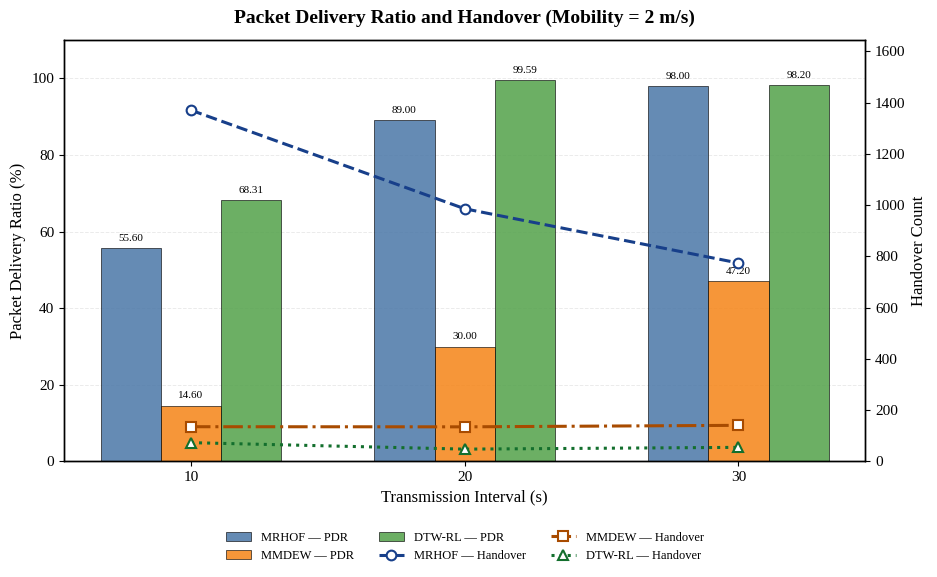

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/01_pdr_vs_handover_mobility_2.png


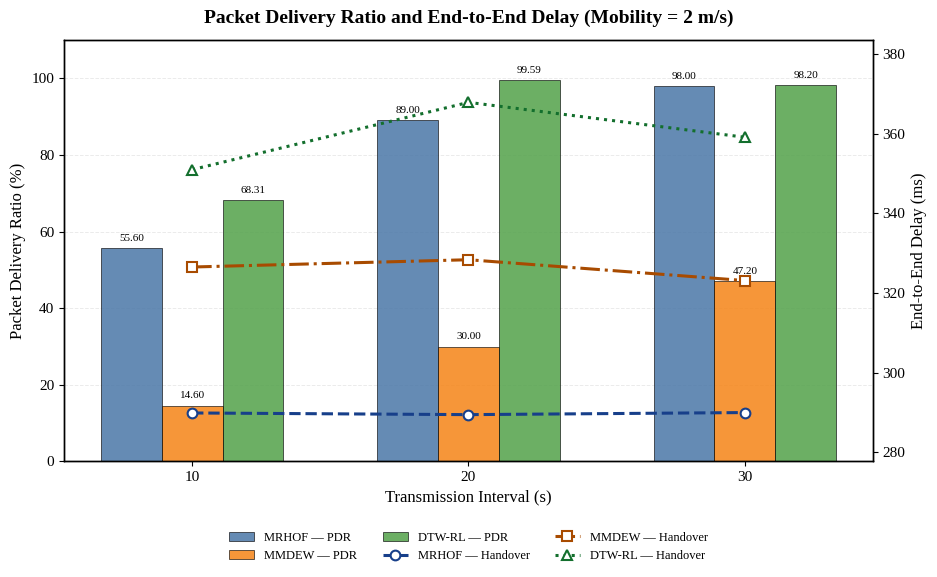

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/02_pdr_vs_delay_mobility_2.png


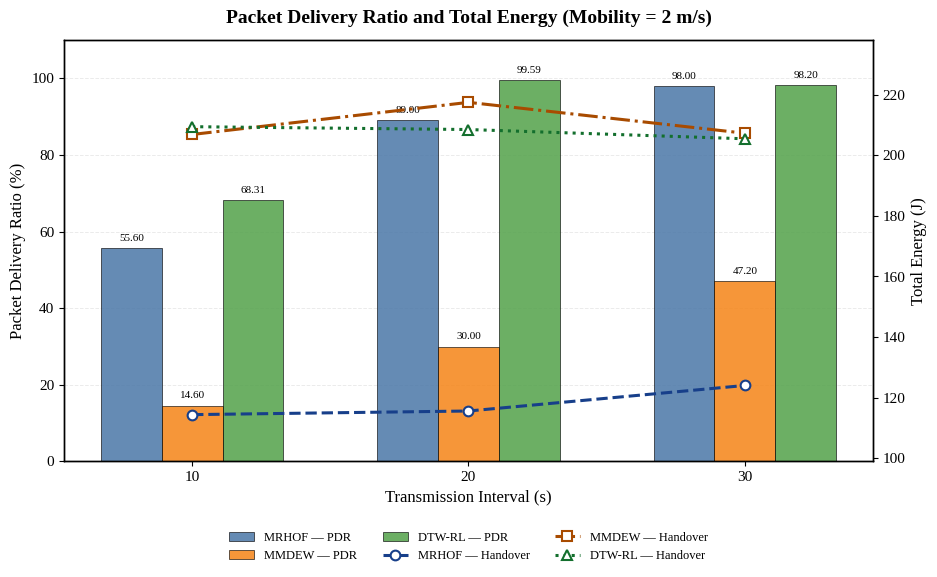

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/03_pdr_vs_total_energy_mobility_2.png


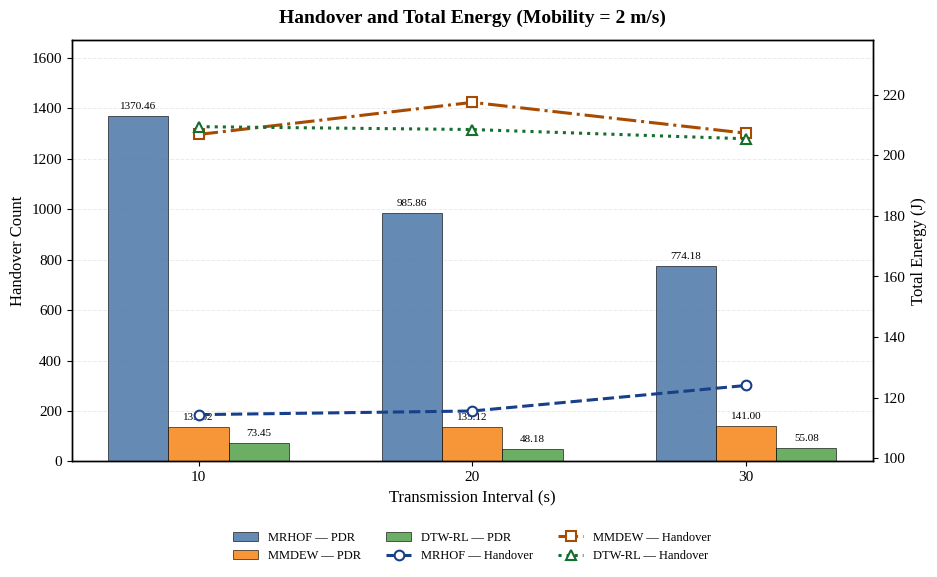

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/04_handover_vs_total_energy_mobility_2.png


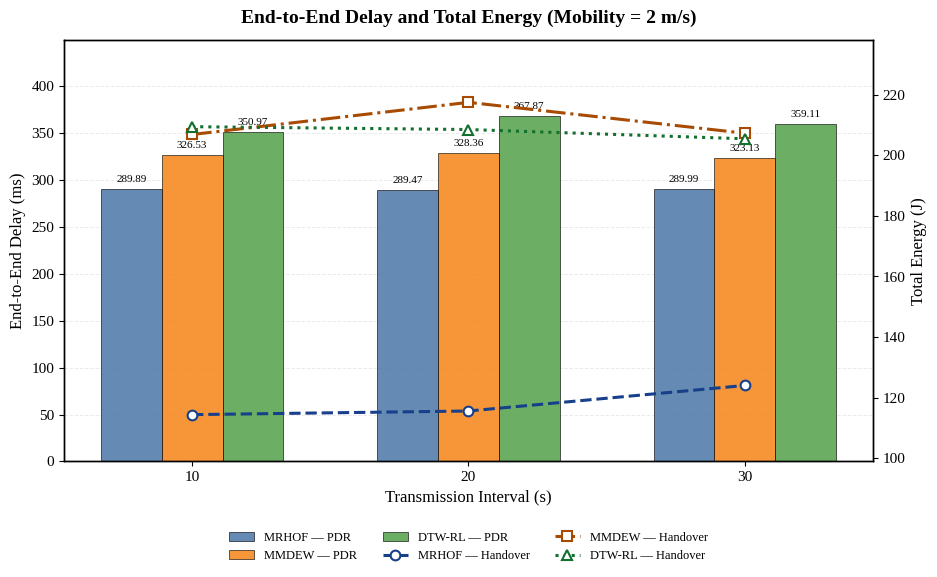

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/05_delay_vs_total_energy_mobility_2.png


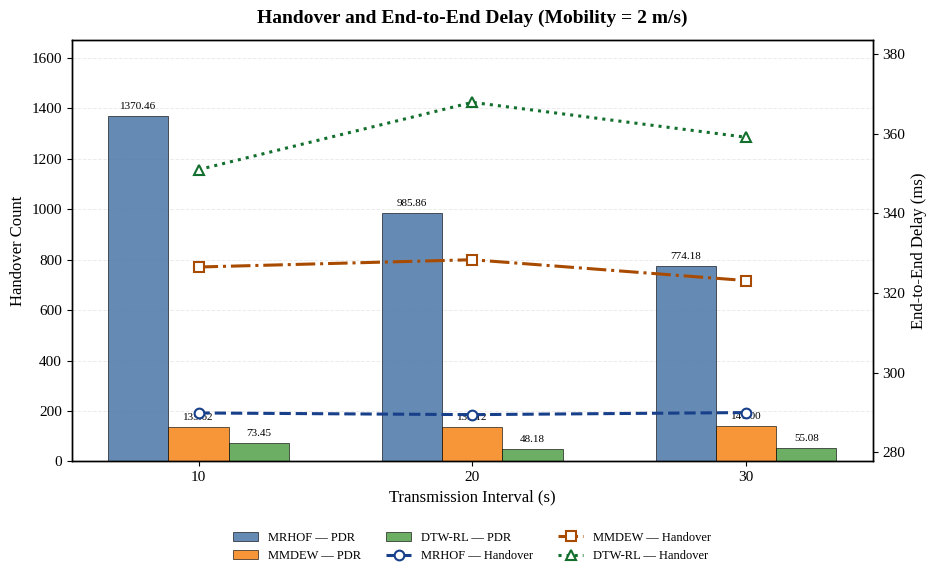

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/06_handover_vs_delay_mobility_2.png

DATA SUMMARY — MOBILITY 5 m/s
Protocol      Interval       PDR (%)      Delay (ms)            HO      Energy (J)
----------------------------------------------------------------------------------------------------
MRHOF               10         34.60          409.95       3090.10          170.41
MRHOF               20         67.20          411.49       2762.42          134.84
MRHOF               30         87.00          405.05       2163.58          143.65
MMDEW               10         23.60          408.54        108.20          211.58
MMDEW               20         40.00          418.77        120.42          206.38
MMDEW               30         51.40          415.72        123.88          206.06
DTW-RL              10         71.28          357.35        107.80          206.84
DTW-RL              20         97.37          406.74         63.03         

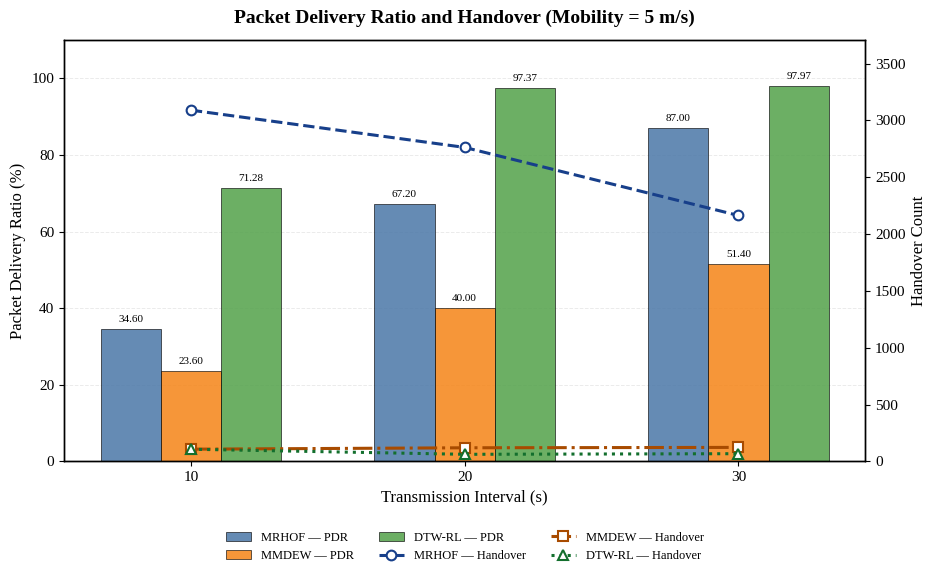

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/01_pdr_vs_handover_mobility_5.png


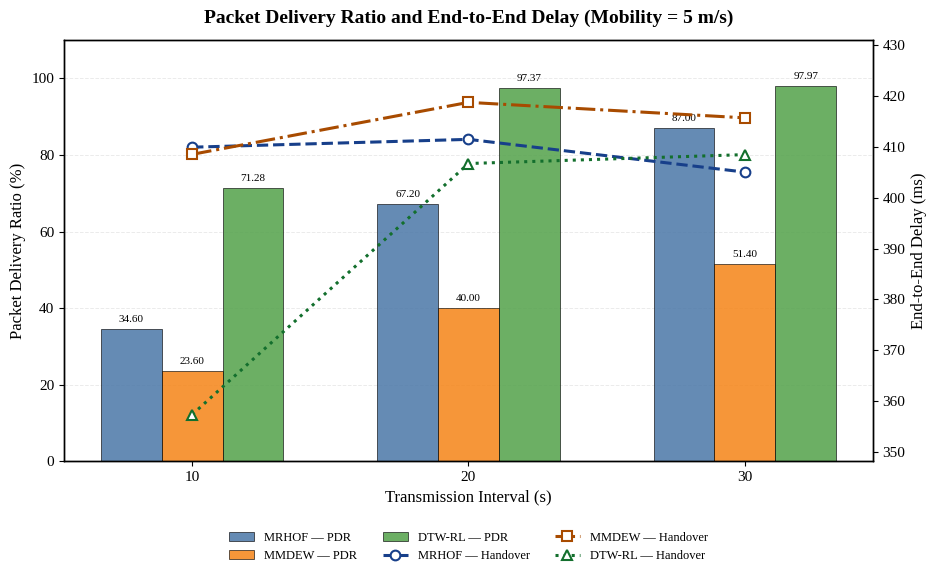

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/02_pdr_vs_delay_mobility_5.png


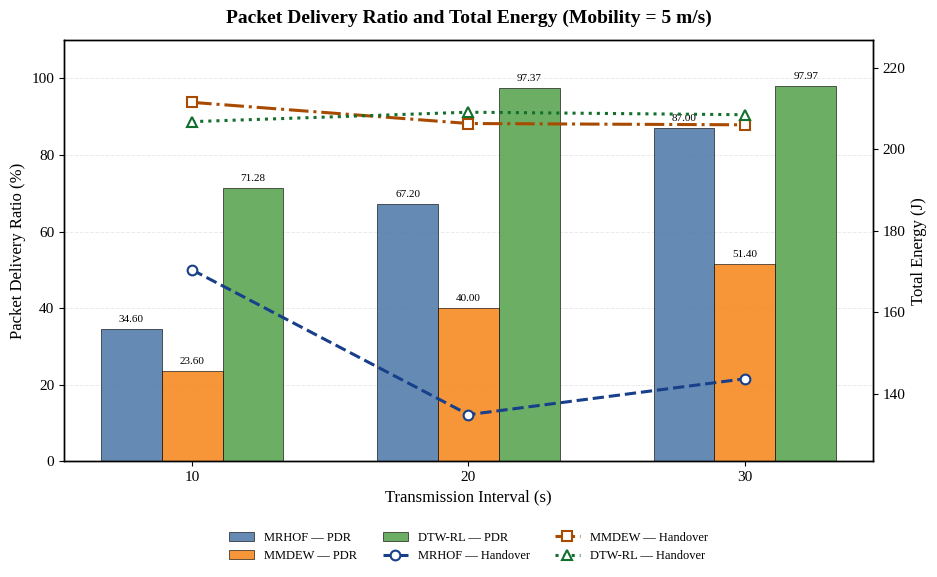

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/03_pdr_vs_total_energy_mobility_5.png


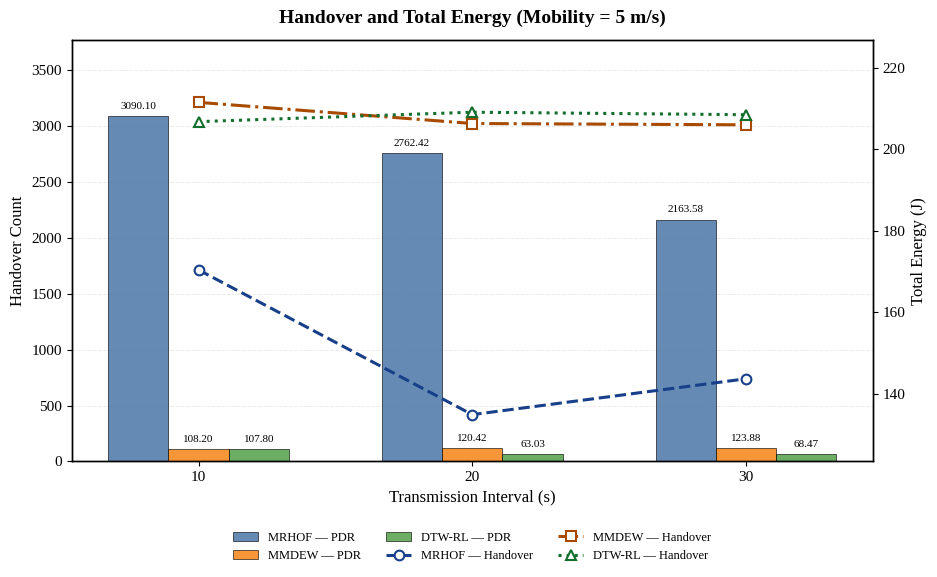

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/04_handover_vs_total_energy_mobility_5.png


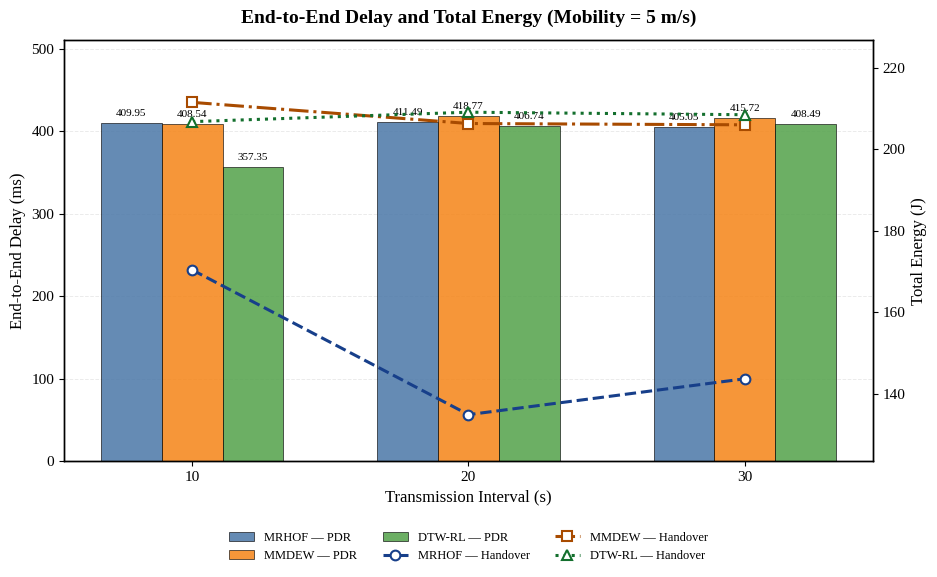

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/05_delay_vs_total_energy_mobility_5.png


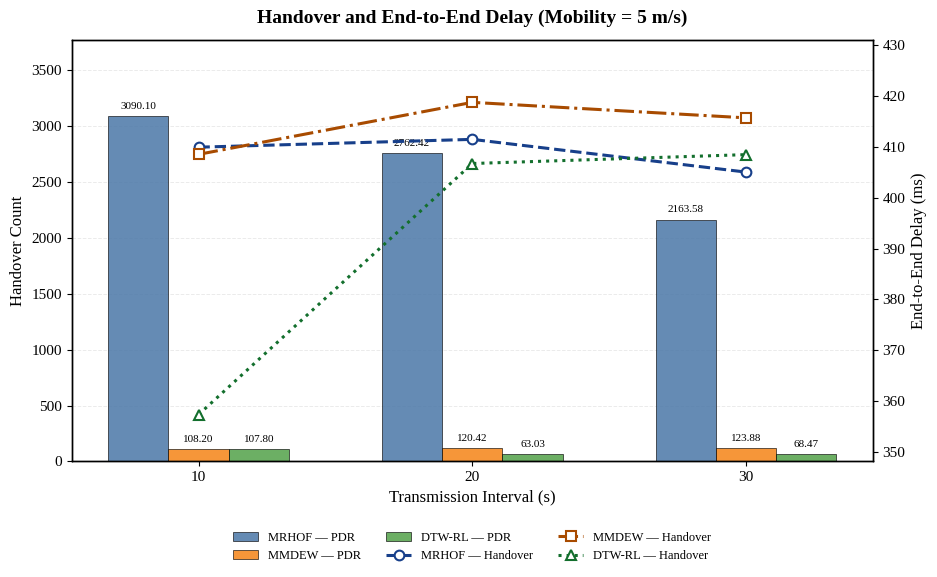

Saved: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean/06_handover_vs_delay_mobility_5.png

ALL BAR-LINE GRAPHS HAVE BEEN GENERATED
Output directory:
/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/correlation_bar_line_latest_mean

Total figures generated: 12
- 6 figures for Mobility 2 m/s
- 6 figures for Mobility 5 m/s


In [ ]:
# ============================================================
# GRAFIK BAR + LINE BERDASARKAN DATA REKAP TERBARU
#
# BAR  = metrik utama
# LINE = metrik pembanding
#
# Ketentuan:
# - Menggunakan nilai rata-rata 5 kali pengujian
# - Tanpa standard deviation/error bar
# - Nilai numerik hanya ditampilkan pada BAR
# - LINE hanya menggunakan marker dan legend
# - Font Times New Roman
# - Output PNG 300 dpi
#
# Metrik:
# 1. PDR (%)
# 2. End-to-End Delay (ms)
# 3. Handover Count
# 4. Total Energy (J)
# ============================================================

import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager


# ============================================================
# OUTPUT FOLDER
# ============================================================
output_dir = Path(
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/"
    "correlation_bar_line_latest_mean"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# GENERAL CONFIGURATION
# ============================================================
intervals = [10, 20, 30]
OF_LIST = ["MRHOF", "MMDEW", "DTW-RL"]


# ============================================================
# FONT CONFIGURATION
# ============================================================
available_fonts = {
    font.name for font in font_manager.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    selected_font = "Times New Roman"
else:
    # Fallback untuk Google Colab/Linux
    selected_font = "Liberation Serif"
    print(
        "Warning: Times New Roman tidak ditemukan. "
        "Menggunakan Liberation Serif sebagai fallback."
    )

plt.rcParams.update({
    "font.family": selected_font,
    "font.size": 11,
    "figure.figsize": (9.5, 6.0),

    "axes.grid": False,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,

    "xtick.labelsize": 11,
    "ytick.labelsize": 11,

    "legend.fontsize": 9,

    "savefig.dpi": 300,
    "savefig.bbox": "tight",

    "axes.linewidth": 1.0
})


# ============================================================
# DATA RATA-RATA TERBARU — MOBILITY 2
# ============================================================

# Packet Delivery Ratio (%)
pdr_m2 = {
    "MRHOF": [55.60, 89.00, 98.00],
    "MMDEW": [14.60, 30.00, 47.20],
    "DTW-RL": [68.31, 99.59, 98.20],
}

# Handover Count
ho_m2 = {
    "MRHOF": [1370.46, 985.86, 774.18],
    "MMDEW": [135.62, 135.12, 141.00],
    "DTW-RL": [73.45, 48.18, 55.08],
}

# End-to-End Delay (ms)
delay_m2 = {
    "MRHOF": [289.89, 289.47, 289.99],
    "MMDEW": [326.53, 328.36, 323.13],
    "DTW-RL": [350.97, 367.87, 359.11],
}

# Total Energy (J)
total_energy_j_m2 = {
    "MRHOF": [114.35, 115.55, 123.99],
    "MMDEW": [206.92, 217.54, 207.34],
    "DTW-RL": [209.50, 208.56, 205.50],
}


# ============================================================
# DATA RATA-RATA TERBARU — MOBILITY 5
# ============================================================

# Packet Delivery Ratio (%)
pdr_m5 = {
    "MRHOF": [34.60, 67.20, 87.00],
    "MMDEW": [23.60, 40.00, 51.40],
    "DTW-RL": [71.28, 97.37, 97.97],
}

# Handover Count
ho_m5 = {
    "MRHOF": [3090.10, 2762.42, 2163.58],
    "MMDEW": [108.20, 120.42, 123.88],
    "DTW-RL": [107.80, 63.03, 68.47],
}

# End-to-End Delay (ms)
delay_m5 = {
    "MRHOF": [409.95, 411.49, 405.05],
    "MMDEW": [408.54, 418.77, 415.72],
    "DTW-RL": [357.35, 406.74, 408.49],
}

# Total Energy (J)
total_energy_j_m5 = {
    "MRHOF": [170.41, 134.84, 143.65],
    "MMDEW": [211.58, 206.38, 206.06],
    "DTW-RL": [206.84, 209.16, 208.54],
}


# ============================================================
# STYLE
# ============================================================
BAR_COLORS = {
    "MRHOF": "#4C78A8",
    "MMDEW": "#F58518",
    "DTW-RL": "#54A24B",
}

LINE_COLORS = {
    "MRHOF": "#173F8A",
    "MMDEW": "#A84B00",
    "DTW-RL": "#136F2D",
}

MARKERS = {
    "MRHOF": "o",
    "MMDEW": "s",
    "DTW-RL": "^",
}

LINE_STYLES = {
    "MRHOF": "--",
    "MMDEW": "-.",
    "DTW-RL": ":",
}


# ============================================================
# VALIDATION HELPERS
# ============================================================
def validate_metric(metric_dict, metric_name):
    """
    Memastikan setiap protokol memiliki nilai sebanyak jumlah interval.
    """
    missing_protocols = [
        protocol
        for protocol in OF_LIST
        if protocol not in metric_dict
    ]

    if missing_protocols:
        raise ValueError(
            f"{metric_name}: protokol tidak ditemukan: "
            f"{missing_protocols}"
        )

    for protocol in OF_LIST:
        values = metric_dict[protocol]

        if len(values) != len(intervals):
            raise ValueError(
                f"{metric_name} - {protocol}: jumlah nilai "
                f"harus {len(intervals)}, tetapi ditemukan {len(values)}."
            )

        if not all(np.isfinite(values)):
            raise ValueError(
                f"{metric_name} - {protocol}: terdapat nilai "
                "NaN atau infinite."
            )


# ============================================================
# AXIS HELPERS
# ============================================================
def get_all_values(metric_dict):
    """
    Menggabungkan seluruh nilai dari semua protokol.
    """
    all_values = []

    for protocol in OF_LIST:
        all_values.extend(metric_dict[protocol])

    return np.asarray(all_values, dtype=float)


def auto_ylim_positive(metric_dict, pad_ratio=0.18):
    """
    Batas sumbu-Y untuk metrik bernilai positif.
    """
    values = get_all_values(metric_dict)

    vmax = np.nanmax(values)

    if vmax <= 0:
        return 0, 1

    return 0, vmax * (1 + pad_ratio)


def auto_ylim_zoom_positive(
    metric_dict,
    lower_pad_ratio=0.15,
    upper_pad_ratio=0.20
):
    """
    Batas sumbu-Y yang diperbesar pada rentang data.

    Cocok untuk line Total Energy atau Delay sehingga perbedaan
    kecil antarnilai lebih mudah dilihat.
    """
    values = get_all_values(metric_dict)

    vmin = np.nanmin(values)
    vmax = np.nanmax(values)
    span = vmax - vmin

    if span == 0:
        span = max(abs(vmax) * 0.10, 1.0)

    lower = max(0, vmin - span * lower_pad_ratio)
    upper = vmax + span * upper_pad_ratio

    return lower, upper


# ============================================================
# NUMBER FORMATTING
# ============================================================
def format_value(value, fmt="{:.2f}"):
    """
    Format nilai numerik.
    """
    return fmt.format(value)


def add_bar_labels(
    ax,
    bars,
    fmt="{:.2f}",
    y_offset_ratio=0.012,
    fontsize=8
):
    """
    Menambahkan angka rata-rata di atas masing-masing bar.
    """
    y_min, y_max = ax.get_ylim()
    axis_span = y_max - y_min
    offset = axis_span * y_offset_ratio

    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + offset,
            format_value(height, fmt),
            ha="center",
            va="bottom",
            fontsize=fontsize,
            fontfamily=selected_font,
            rotation=0,
            clip_on=False
        )


# ============================================================
# CORE FUNCTION: BAR + LINE WITH DUAL AXES
# ============================================================
def plot_bar_line(
    bar_metric,
    line_metric,
    title,
    ylabel_bar,
    ylabel_line,
    filename,
    bar_ylim=None,
    line_ylim=None,
    bar_fmt="{:.2f}",
    show_grid=True
):
    """
    Membuat grafik dual-axis:
    - Bar pada sumbu kiri
    - Line pada sumbu kanan
    - Nilai numerik hanya ditampilkan pada bar
    """

    validate_metric(bar_metric, ylabel_bar)
    validate_metric(line_metric, ylabel_line)

    x = np.arange(len(intervals))
    width = 0.22

    fig, ax1 = plt.subplots(figsize=(9.5, 6.0))

    # ========================================================
    # BAR AXIS — LEFT Y-AXIS
    # ========================================================
    bar_positions = {
        "MRHOF": x - width,
        "MMDEW": x,
        "DTW-RL": x + width,
    }

    bar_handles = {}

    for protocol in OF_LIST:
        bar_handles[protocol] = ax1.bar(
            bar_positions[protocol],
            bar_metric[protocol],
            width=width,
            label=f"{protocol} — Bar",
            color=BAR_COLORS[protocol],
            alpha=0.86,
            edgecolor="black",
            linewidth=0.50,
            zorder=2
        )

    ax1.set_xlabel(
        "Transmission Interval (s)",
        fontfamily=selected_font
    )

    ax1.set_ylabel(
        ylabel_bar,
        fontfamily=selected_font
    )

    ax1.set_xticks(x)
    ax1.set_xticklabels(
        intervals,
        fontfamily=selected_font
    )

    if bar_ylim is None:
        bar_ylim = auto_ylim_positive(bar_metric)

    ax1.set_ylim(*bar_ylim)

    if show_grid:
        ax1.grid(
            axis="y",
            linestyle="--",
            linewidth=0.7,
            alpha=0.25,
            zorder=0
        )

    # Nilai hanya ditampilkan pada bar
    for protocol in OF_LIST:
        add_bar_labels(
            ax=ax1,
            bars=bar_handles[protocol],
            fmt=bar_fmt,
            fontsize=8
        )

    # ========================================================
    # LINE AXIS — RIGHT Y-AXIS
    # ========================================================
    ax2 = ax1.twinx()

    line_handles = {}

    for protocol in OF_LIST:
        line_handles[protocol], = ax2.plot(
            x,
            line_metric[protocol],
            marker=MARKERS[protocol],
            linestyle=LINE_STYLES[protocol],
            linewidth=2.2,
            markersize=7,
            markerfacecolor="white",
            markeredgewidth=1.5,
            color=LINE_COLORS[protocol],
            label=f"{protocol} — Line",
            zorder=3
        )

    ax2.set_ylabel(
        ylabel_line,
        fontfamily=selected_font
    )

    if line_ylim is None:
        line_ylim = auto_ylim_zoom_positive(line_metric)

    ax2.set_ylim(*line_ylim)

    # ========================================================
    # TITLE
    # ========================================================
    ax1.set_title(
        title,
        fontfamily=selected_font,
        fontweight="bold",
        pad=12
    )

    # ========================================================
    # FONT FOR TICK LABELS
    # ========================================================
    for tick_label in ax1.get_xticklabels():
        tick_label.set_fontfamily(selected_font)

    for tick_label in ax1.get_yticklabels():
        tick_label.set_fontfamily(selected_font)

    for tick_label in ax2.get_yticklabels():
        tick_label.set_fontfamily(selected_font)

    # ========================================================
    # LEGEND
    # ========================================================
    combined_handles = (
        [bar_handles[protocol] for protocol in OF_LIST]
        + [line_handles[protocol] for protocol in OF_LIST]
    )

    combined_labels = (
        [f"{protocol} — PDR" for protocol in OF_LIST]
        + [f"{protocol} — Handover" for protocol in OF_LIST]
    )

    legend = ax1.legend(
        combined_handles,
        combined_labels,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.14),
        ncol=3,
        fontsize=9,
        frameon=False
    )

    for legend_text in legend.get_texts():
        legend_text.set_fontfamily(selected_font)

    # ========================================================
    # SAVE
    # ========================================================
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.22)

    save_path = output_dir / filename

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)


# ============================================================
# GENERATE ALL GRAPHS FOR ONE MOBILITY
# ============================================================
def generate_all_correlation_graphs(
    mobility_label,
    pdr,
    ho,
    delay,
    total_energy_j
):
    """
    Menghasilkan enam grafik untuk satu tingkat mobility.
    """

    mobility_text = f"Mobility = {mobility_label} m/s"
    suffix = f"mobility_{mobility_label}"

    # ========================================================
    # 1. PDR vs HANDOVER
    # ========================================================
    plot_bar_line(
        bar_metric=pdr,
        line_metric=ho,
        title=(
            f"Packet Delivery Ratio and Handover "
            f"({mobility_text})"
        ),
        ylabel_bar="Packet Delivery Ratio (%)",
        ylabel_line="Handover Count",
        filename=f"01_pdr_vs_handover_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_positive(
            ho,
            pad_ratio=0.20
        ),
        bar_fmt="{:.2f}",
        show_grid=True
    )

    # ========================================================
    # 2. PDR vs END-TO-END DELAY
    # ========================================================
    plot_bar_line(
        bar_metric=pdr,
        line_metric=delay,
        title=(
            f"Packet Delivery Ratio and End-to-End Delay "
            f"({mobility_text})"
        ),
        ylabel_bar="Packet Delivery Ratio (%)",
        ylabel_line="End-to-End Delay (ms)",
        filename=f"02_pdr_vs_delay_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_zoom_positive(delay),
        bar_fmt="{:.2f}",
        show_grid=True
    )

    # ========================================================
    # 3. PDR vs TOTAL ENERGY
    # ========================================================
    plot_bar_line(
        bar_metric=pdr,
        line_metric=total_energy_j,
        title=(
            f"Packet Delivery Ratio and Total Energy "
            f"({mobility_text})"
        ),
        ylabel_bar="Packet Delivery Ratio (%)",
        ylabel_line="Total Energy (J)",
        filename=f"03_pdr_vs_total_energy_{suffix}.png",
        bar_ylim=(0, 110),
        line_ylim=auto_ylim_zoom_positive(total_energy_j),
        bar_fmt="{:.2f}",
        show_grid=True
    )

    # ========================================================
    # 4. HANDOVER vs TOTAL ENERGY
    # ========================================================
    plot_bar_line(
        bar_metric=ho,
        line_metric=total_energy_j,
        title=(
            f"Handover and Total Energy "
            f"({mobility_text})"
        ),
        ylabel_bar="Handover Count",
        ylabel_line="Total Energy (J)",
        filename=f"04_handover_vs_total_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(
            ho,
            pad_ratio=0.22
        ),
        line_ylim=auto_ylim_zoom_positive(total_energy_j),
        bar_fmt="{:.2f}",
        show_grid=True
    )

    # ========================================================
    # 5. END-TO-END DELAY vs TOTAL ENERGY
    # ========================================================
    plot_bar_line(
        bar_metric=delay,
        line_metric=total_energy_j,
        title=(
            f"End-to-End Delay and Total Energy "
            f"({mobility_text})"
        ),
        ylabel_bar="End-to-End Delay (ms)",
        ylabel_line="Total Energy (J)",
        filename=f"05_delay_vs_total_energy_{suffix}.png",
        bar_ylim=auto_ylim_positive(
            delay,
            pad_ratio=0.22
        ),
        line_ylim=auto_ylim_zoom_positive(total_energy_j),
        bar_fmt="{:.2f}",
        show_grid=True
    )

    # ========================================================
    # 6. HANDOVER vs END-TO-END DELAY
    # ========================================================
    plot_bar_line(
        bar_metric=ho,
        line_metric=delay,
        title=(
            f"Handover and End-to-End Delay "
            f"({mobility_text})"
        ),
        ylabel_bar="Handover Count",
        ylabel_line="End-to-End Delay (ms)",
        filename=f"06_handover_vs_delay_{suffix}.png",
        bar_ylim=auto_ylim_positive(
            ho,
            pad_ratio=0.22
        ),
        line_ylim=auto_ylim_zoom_positive(delay),
        bar_fmt="{:.2f}",
        show_grid=True
    )


# ============================================================
# PRINT DATA SUMMARY
# ============================================================
def print_data_summary(
    mobility_label,
    pdr,
    ho,
    delay,
    energy
):
    """
    Menampilkan nilai rata-rata yang digunakan pada grafik.
    """

    print("\n" + "=" * 100)
    print(
        f"DATA SUMMARY — MOBILITY {mobility_label} m/s"
    )
    print("=" * 100)

    header = (
        f"{'Protocol':<10}"
        f"{'Interval':>12}"
        f"{'PDR (%)':>14}"
        f"{'Delay (ms)':>16}"
        f"{'HO':>14}"
        f"{'Energy (J)':>16}"
    )

    print(header)
    print("-" * 100)

    for protocol in OF_LIST:
        for index, interval in enumerate(intervals):
            print(
                f"{protocol:<10}"
                f"{interval:>12}"
                f"{pdr[protocol][index]:>14.2f}"
                f"{delay[protocol][index]:>16.2f}"
                f"{ho[protocol][index]:>14.2f}"
                f"{energy[protocol][index]:>16.2f}"
            )


# ============================================================
# GENERATE MOBILITY 2
# ============================================================
print_data_summary(
    mobility_label=2,
    pdr=pdr_m2,
    ho=ho_m2,
    delay=delay_m2,
    energy=total_energy_j_m2
)

generate_all_correlation_graphs(
    mobility_label=2,
    pdr=pdr_m2,
    ho=ho_m2,
    delay=delay_m2,
    total_energy_j=total_energy_j_m2
)


# ============================================================
# GENERATE MOBILITY 5
# ============================================================
print_data_summary(
    mobility_label=5,
    pdr=pdr_m5,
    ho=ho_m5,
    delay=delay_m5,
    energy=total_energy_j_m5
)

generate_all_correlation_graphs(
    mobility_label=5,
    pdr=pdr_m5,
    ho=ho_m5,
    delay=delay_m5,
    total_energy_j=total_energy_j_m5
)


# ============================================================
# FINAL MESSAGE
# ============================================================
print("\n" + "=" * 100)
print("ALL BAR-LINE GRAPHS HAVE BEEN GENERATED")
print("=" * 100)
print("Output directory:")
print(output_dir)
print("\nTotal figures generated: 12")
print("- 6 figures for Mobility 2 m/s")
print("- 6 figures for Mobility 5 m/s")

sadfsadfdasf

In [ ]:
#!/usr/bin/env python3
"""Extract defensible DTW-RL metrics from five Contiki-NG CSV logs.

The input CSV files must contain the columns ``time``, ``node``, and
``message``.  The script intentionally does not use the PDR printed by the
current UDP server because that implementation keeps one global sequence
counter for multiple senders.  Network PDR is reconstructed from unique
``(source node, sequence number)`` pairs found in the client and sink logs.

Outputs are written as CSV files so that the raw per-run and per-node values
remain available for checking and statistical analysis.
"""

from __future__ import annotations

import argparse
import re
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd


# These defaults follow the paths used by the previous Colab script.  They can
# be replaced here or overridden by passing five CSV paths on the command line.
CSV_FILES = [
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau2/mob5/DTWRL101.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau2/mob5/DTWRL201.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau2/mob5/DTWRL301.csv",

]

DEFAULT_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau2/mob5"
    "dtw_rl_valid_metrics_5runs"
)
DEFAULT_SINK_NODE = 30


FLOAT = r"(-?[0-9]+(?:\.[0-9]+)?)"
INT = r"([0-9]+)"


def numeric_stats(values: Iterable[float], prefix: str) -> dict[str, float]:
    """Return count, mean, sample SD, median, min, max, and p95."""
    # Pandas nullable columns can contain pd.NA.  Recent pandas versions do not
    # allow pd.NA to be cast directly to NumPy float64, so normalize all missing
    # values to np.nan before performing the numeric conversion.
    if isinstance(values, pd.Series):
        raw = values.astype("object").where(values.notna(), np.nan)
    else:
        raw = pd.Series(list(values), dtype="object")
        raw = raw.where(pd.notna(raw), np.nan)
    s = pd.to_numeric(raw, errors="coerce").astype("float64").dropna()
    if s.empty:
        return {
            f"{prefix}_n": 0,
            f"{prefix}_mean": np.nan,
            f"{prefix}_sd": np.nan,
            f"{prefix}_median": np.nan,
            f"{prefix}_min": np.nan,
            f"{prefix}_max": np.nan,
            f"{prefix}_p95": np.nan,
        }
    return {
        f"{prefix}_n": int(s.size),
        f"{prefix}_mean": float(s.mean()),
        f"{prefix}_sd": float(s.std(ddof=1)) if s.size > 1 else np.nan,
        f"{prefix}_median": float(s.median()),
        f"{prefix}_min": float(s.min()),
        f"{prefix}_max": float(s.max()),
        f"{prefix}_p95": float(s.quantile(0.95)),
    }


def parse_clock_value(value: str) -> tuple[float, bool]:
    """Parse MM:SS.sss or HH:MM:SS.sss and report whether it is MM:SS."""
    parts = str(value).strip().split(":")
    try:
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1]), True
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2]), False
    except (TypeError, ValueError):
        pass
    return np.nan, False


def unwrap_timestamps(series: pd.Series) -> tuple[pd.Series, int]:
    """Convert Cooja timestamps to monotonic seconds, handling hourly wrap."""
    result: list[float] = []
    offset = 0.0
    previous_raw: float | None = None
    rollovers = 0
    for value in series:
        raw, is_minute_format = parse_clock_value(value)
        if np.isnan(raw):
            result.append(np.nan)
            continue
        # Cooja logs observed here use MM:SS and return to 00:00 after 59:59.
        if (
            is_minute_format
            and previous_raw is not None
            and raw < previous_raw - 300.0
        ):
            offset += 3600.0
            rollovers += 1
        result.append(raw + offset)
        previous_raw = raw
    return pd.Series(result, index=series.index, dtype="float64"), rollovers


def last_hex_group(ip: str) -> float:
    match = re.search(r":([0-9a-fA-F]+)$", str(ip).strip())
    return float(int(match.group(1), 16)) if match else np.nan


def extract_number(message: pd.Series, pattern: str) -> pd.Series:
    return pd.to_numeric(message.str.extract(pattern, expand=False), errors="coerce")


def read_log(csv_path: Path) -> tuple[pd.DataFrame, int]:
    df = pd.read_csv(
        csv_path,
        dtype={"time": "string", "node": "Int64", "message": "string"},
        engine="python",
        on_bad_lines="warn",
    )
    required = {"time", "node", "message"}
    if not required.issubset(df.columns):
        raise ValueError(f"{csv_path} must contain columns: time, node, message")
    df = df.loc[:, ["time", "node", "message"]].copy()
    df["message"] = df["message"].fillna("")
    df["row_order"] = np.arange(len(df), dtype=np.int64)
    df["time_s"], rollovers = unwrap_timestamps(df["time"])
    return df, rollovers


def extract_run(csv_path: Path, run_name: str, sink_node: int) -> dict[str, pd.DataFrame | dict]:
    df, rollovers = read_log(csv_path)
    msg = df["message"]

    # ------------------------------------------------------------------
    # Application packets: use exact UDP client/server messages and unique
    # (node, sequence) keys.  "Sent" means submitted by the application to
    # simple_udp_sendto(), not a MAC ACK or confirmed end-to-end delivery.
    # ------------------------------------------------------------------
    sent_mask = msg.str.contains(r"\[INFO:\s*UDP-Client\].*Sent Seq=", regex=True, na=False)
    sent = df.loc[sent_mask, ["row_order", "time_s", "node", "message"]].copy()
    sent["seq"] = extract_number(sent["message"], rf"Sent Seq={INT}").astype("Int64")
    sent = sent.dropna(subset=["node", "seq"])
    sent_duplicate_lines = int(sent.duplicated(["node", "seq"]).sum())
    sent_unique = sent.drop_duplicates(["node", "seq"], keep="first").copy()

    recv_mask = msg.str.contains(r"\[INFO:\s*UDP-Server\].*From .*Seq=", regex=True, na=False)
    recv = df.loc[recv_mask, ["row_order", "time_s", "node", "message"]].copy()
    recv["source_ip"] = recv["message"].str.extract(r"From\s+([^,]+),\s*Seq=", expand=False)
    recv["source_node"] = recv["source_ip"].apply(last_hex_group).astype("Int64")
    recv["seq"] = extract_number(recv["message"], rf"Seq={INT}").astype("Int64")
    recv["delay_ms"] = extract_number(recv["message"], rf"Delay={FLOAT}ms")
    recv["rssi_dbm"] = extract_number(recv["message"], rf"RSSI={FLOAT}dBm")
    recv = recv.dropna(subset=["source_node", "seq"])
    recv_duplicate_lines = int(recv.duplicated(["source_node", "seq"]).sum())
    recv_unique = recv.drop_duplicates(["source_node", "seq"], keep="first").copy()

    sent_keys = pd.MultiIndex.from_frame(sent_unique[["node", "seq"]])
    recv_keys = pd.MultiIndex.from_frame(
        recv_unique[["source_node", "seq"]].rename(columns={"source_node": "node"})
    )
    matched_recv = int(recv_keys.isin(sent_keys).sum())
    unmatched_recv = int((~recv_keys.isin(sent_keys)).sum())
    sent_count = int(len(sent_unique))
    received_count = matched_recv
    lost_count = max(sent_count - received_count, 0)
    pdr_network = 100.0 * received_count / sent_count if sent_count else np.nan

    sent_per_node = sent_unique.groupby("node").size().rename("sent_unique")
    recv_per_node = recv_unique.groupby("source_node").size().rename("received_unique")
    client_nodes = sorted(set(sent_per_node.index.astype(int)))
    node_delivery = pd.DataFrame({"node": client_nodes})
    node_delivery = node_delivery.merge(sent_per_node, on="node", how="left")
    node_delivery = node_delivery.merge(
        recv_per_node, left_on="node", right_on="source_node", how="left"
    ).drop(columns=["source_node"], errors="ignore")
    node_delivery[["sent_unique", "received_unique"]] = node_delivery[
        ["sent_unique", "received_unique"]
    ].fillna(0).astype(int)
    node_delivery["lost"] = node_delivery["sent_unique"] - node_delivery["received_unique"]
    node_delivery["pdr_pct"] = np.where(
        node_delivery["sent_unique"] > 0,
        100.0 * node_delivery["received_unique"] / node_delivery["sent_unique"],
        np.nan,
    )
    node_delivery.insert(0, "run", run_name)

    # ------------------------------------------------------------------
    # DTW-RL controller telemetry.  TC is a controller-window update.  It is
    # not automatically labelled as an objective-function/rank evaluation.
    # ------------------------------------------------------------------
    tc_mask = msg.str.contains(r"\bTC,W=", regex=True, na=False)
    tc = df.loc[tc_mask, ["row_order", "time_s", "node", "message"]].copy()
    tc_fields = {
        "window_index": rf"\bTC,W={INT}",
        "tau_s": rf"\btau={FLOAT}",
        "target_tau_s": rf"\btgt={FLOAT}",
        "action": rf"\ba={INT}",
        "inverse_trust": rf"\binvT={FLOAT}",
        "energy_state": rf"\bdE={FLOAT}",
        "window_energy_mj": rf"\bdE_mJ={FLOAT}",
        "cpu_energy_change_mj": rf"\bdEC={FLOAT}",
        "instability_index": rf"\bI={FLOAT}",
        "evidence": rf"\bevid={INT}",
        "epsilon": rf"\beps={FLOAT}",
    }
    for column, pattern in tc_fields.items():
        tc[column] = extract_number(tc["message"], pattern)
    tc.insert(0, "run", run_name)

    controller_per_node = []
    for node, sub in tc.groupby("node", observed=True):
        controller_per_node.append(
            {
                "run": run_name,
                "node": int(node),
                "controller_updates": int(len(sub)),
                "tau_mean_event_weighted_s": float(sub["tau_s"].mean()),
                "tau_sd_s": float(sub["tau_s"].std(ddof=1)),
                "tau_min_s": float(sub["tau_s"].min()),
                "tau_max_s": float(sub["tau_s"].max()),
                "tau_last_s": float(sub.iloc[-1]["tau_s"]),
                "action_dec": int((sub["action"] == 0).sum()),
                "action_inc": int((sub["action"] == 1).sum()),
                "instability_mean": float(sub["instability_index"].mean()),
                "inverse_trust_mean": float(sub["inverse_trust"].mean()),
                "window_energy_mean_mj": float(sub["window_energy_mj"].mean()),
                "cpu_energy_change_mean_mj": float(sub["cpu_energy_change_mj"].mean()),
                "epsilon_last": float(sub.iloc[-1]["epsilon"]),
            }
        )
    controller_per_node = pd.DataFrame(controller_per_node)

    # ------------------------------------------------------------------
    # Confirmed custom HO lines and diagnostic core-RPL parent-change lines.
    # Keep the counters separate because they do not have identical totals.
    # ------------------------------------------------------------------
    ho_mask = msg.str.contains(r"\bHO,\d+,delay_ms=\d+", regex=True, na=False)
    handover = df.loc[ho_mask, ["row_order", "time_s", "node", "message"]].copy()
    handover["local_handover_counter"] = extract_number(
        handover["message"], rf"\bHO,{INT},delay_ms="
    ).astype("Int64")
    handover["delay_ms"] = extract_number(handover["message"], rf"delay_ms={INT}")
    handover.insert(0, "run", run_name)

    ho_per_node = handover.groupby("node").size().rename("handover_events")
    eligible_nodes = sorted(set(client_nodes) | set(tc["node"].dropna().astype(int)))
    handover_per_node = pd.DataFrame({"node": eligible_nodes})
    handover_per_node = handover_per_node.merge(ho_per_node, on="node", how="left")
    handover_per_node["handover_events"] = handover_per_node["handover_events"].fillna(0).astype(int)
    handover_per_node.insert(0, "run", run_name)

    changed_parent_count = int(msg.str.contains("Changed preferred parent", na=False).sum())
    set_parent_count = int(msg.str.contains("rpl_set_preferred_parent", na=False).sum())

    # ------------------------------------------------------------------
    # RPL control overhead from the explicit transmit instrumentation.
    # ------------------------------------------------------------------
    control = df.loc[
        msg.str.contains(r"MMDEW-CTRL:\s*Tx\s+(?:DIO|DAO|DIS)", regex=True, na=False),
        ["row_order", "time_s", "node", "message"],
    ].copy()
    control["control_type"] = control["message"].str.extract(
        r"MMDEW-CTRL:\s*Tx\s+(DIO|DAO|DIS)", expand=False
    )
    control_per_node = (
        control.pivot_table(index="node", columns="control_type", values="row_order", aggfunc="count", fill_value=0)
        .reindex(columns=["DIO", "DAO", "DIS"], fill_value=0)
        .reset_index()
    )
    control_per_node["control_total"] = control_per_node[["DIO", "DAO", "DIS"]].sum(axis=1)
    control_per_node.insert(0, "run", run_name)
    control_counts = control["control_type"].value_counts()

    # ------------------------------------------------------------------
    # Cumulative Energest-derived energy snapshots.  The latest snapshot for
    # each node is used.  If the sink has no EN,TOTAL line, the sum is labelled
    # as energy across logged nodes, not total energy of every simulated node.
    # ------------------------------------------------------------------
    energy_mask = msg.str.contains(r"\bEN,TOTAL,N=", regex=True, na=False)
    energy = df.loc[energy_mask, ["row_order", "time_s", "node", "message"]].copy()
    energy["reported_node"] = extract_number(energy["message"], rf"\bEN,TOTAL,N={INT}").astype("Int64")
    energy["cpu_mj"] = extract_number(energy["message"], rf"cpu_mJ={FLOAT}")
    energy["tx_mj"] = extract_number(energy["message"], rf"tx_mJ={FLOAT}")
    energy["rx_mj"] = extract_number(energy["message"], rf"rx_mJ={FLOAT}")
    energy["total_mj"] = extract_number(energy["message"], rf"total_mJ={FLOAT}")
    energy_latest = (
        energy.sort_values("row_order")
        .dropna(subset=["reported_node"])
        .drop_duplicates("reported_node", keep="last")
        .copy()
    )
    energy_latest["node"] = energy_latest["reported_node"].astype(int)
    energy_latest["cpu_j"] = energy_latest["cpu_mj"] / 1000.0
    energy_latest["tx_j"] = energy_latest["tx_mj"] / 1000.0
    energy_latest["rx_j"] = energy_latest["rx_mj"] / 1000.0
    energy_latest["total_j"] = energy_latest["total_mj"] / 1000.0
    energy_latest.insert(0, "run", run_name)
    node_energy = energy_latest[
        ["run", "node", "time_s", "cpu_j", "tx_j", "rx_j", "total_j"]
    ].sort_values("node")

    # ------------------------------------------------------------------
    # Other diagnostic routing events.
    # ------------------------------------------------------------------
    local_repair_count = int(msg.str.contains("Starting a local instance repair", na=False).sum())
    root_unknown_skipped = int(msg.str.contains("Root IP unknown, skipped", na=False).sum())
    csma_error_lines = int(msg.str.contains(r"\[ERR\s*:\s*CSMA", regex=True, na=False).sum())

    # Printed server summaries are retained only for discrepancy checking.
    final_rows = df.loc[msg.str.contains("FINAL_STATS", na=False), "message"]
    if final_rows.empty:
        server_final_received = server_final_lost = server_final_pdr = np.nan
    else:
        final_message = final_rows.iloc[-1]
        server_final_received = float(re.search(r"Received=(\d+)", final_message).group(1))
        server_final_lost = float(re.search(r"Lost=(\d+)", final_message).group(1))
        server_final_pdr = float(re.search(r"PDR=([0-9.]+)%", final_message).group(1))

    valid_times = df["time_s"].dropna()
    duration_s = float(valid_times.max() - valid_times.min()) if len(valid_times) else np.nan
    duration_min = duration_s / 60.0 if duration_s > 0 else np.nan
    tc_count = int(len(tc))
    ho_count = int(len(handover))
    total_control = int(len(control))

    tau_node_equal_mean = (
        float(controller_per_node["tau_mean_event_weighted_s"].mean())
        if not controller_per_node.empty
        else np.nan
    )

    summary = {
        "run": run_name,
        "source_file": str(csv_path),
        "simulation_duration_s": duration_s,
        "timestamp_rollovers_detected": rollovers,
        "sink_node": sink_node,
        "client_nodes_with_sent_logs": len(client_nodes),
        "application_sent_unique": sent_count,
        "application_received_unique_matched": received_count,
        "application_lost_reconstructed": lost_count,
        "network_pdr_pct_reconstructed": pdr_network,
        "sent_duplicate_lines": sent_duplicate_lines,
        "received_duplicate_lines": recv_duplicate_lines,
        "received_without_matching_sent": unmatched_recv,
        "root_unknown_skipped": root_unknown_skipped,
        "server_final_received_diagnostic": server_final_received,
        "server_final_lost_invalid_multisender": server_final_lost,
        "server_final_pdr_invalid_multisender_pct": server_final_pdr,
        "controller_updates_tc": tc_count,
        "tau_mean_event_weighted_s": float(tc["tau_s"].mean()) if tc_count else np.nan,
        "tau_mean_node_equal_weight_s": tau_node_equal_mean,
        "tau_min_s": float(tc["tau_s"].min()) if tc_count else np.nan,
        "tau_max_s": float(tc["tau_s"].max()) if tc_count else np.nan,
        "action_dec": int((tc["action"] == 0).sum()),
        "action_inc": int((tc["action"] == 1).sum()),
        "handover_custom_events": ho_count,
        "handover_per_100_tc_updates_proxy": 100.0 * ho_count / tc_count if tc_count else np.nan,
        "core_changed_preferred_parent_lines": changed_parent_count,
        "set_preferred_parent_lines_including_initialization": set_parent_count,
        "dio_tx": int(control_counts.get("DIO", 0)),
        "dao_tx": int(control_counts.get("DAO", 0)),
        "dis_tx": int(control_counts.get("DIS", 0)),
        "control_packets_tx_total": total_control,
        "control_packets_per_min": total_control / duration_min if duration_min else np.nan,
        "local_repairs": local_repair_count,
        "csma_error_log_lines_diagnostic": csma_error_lines,
        "energy_nodes_logged": int(len(node_energy)),
        "sink_energy_available": bool(sink_node in set(node_energy["node"])) if len(node_energy) else False,
        "energy_cpu_sum_logged_nodes_j": float(node_energy["cpu_j"].sum()),
        "energy_tx_sum_logged_nodes_j": float(node_energy["tx_j"].sum()),
        "energy_rx_sum_logged_nodes_j": float(node_energy["rx_j"].sum()),
        "energy_total_sum_logged_nodes_j": float(node_energy["total_j"].sum()),
        "energy_total_mean_per_logged_node_j": float(node_energy["total_j"].mean()),
        "energy_total_sd_per_logged_node_j": float(node_energy["total_j"].std(ddof=1)),
        "energy_total_min_per_logged_node_j": float(node_energy["total_j"].min()),
        "energy_total_max_per_logged_node_j": float(node_energy["total_j"].max()),
    }
    summary.update(numeric_stats(recv_unique["delay_ms"], "packet_delay_ms"))
    summary.update(numeric_stats(recv_unique["rssi_dbm"], "packet_rssi_dbm"))
    summary.update(numeric_stats(handover["delay_ms"], "handover_delay_ms_diagnostic"))

    issues: list[dict[str, str]] = []
    def issue(code: str, detail: str) -> None:
        issues.append({"run": run_name, "issue_code": code, "detail": detail})

    if not np.isnan(server_final_pdr) and abs(server_final_pdr - pdr_network) > 0.5:
        issue(
            "SERVER_PDR_NOT_VALID_FOR_MULTISENDER",
            f"Server={server_final_pdr:.2f}%, reconstructed={pdr_network:.2f}%.",
        )
    if not np.isnan(server_final_received) and int(server_final_received) != received_count:
        issue(
            "FINAL_STATS_NOT_AT_END",
            f"FINAL_STATS received={int(server_final_received)}, full log received={received_count}.",
        )
    if sink_node not in set(node_energy["node"]) if len(node_energy) else True:
        issue(
            "SINK_ENERGY_MISSING",
            "Energy sum covers logged nodes only and must not be called all-node network energy.",
        )
    if not (ho_count == changed_parent_count == set_parent_count):
        issue(
            "HANDOVER_COUNTERS_DIFFER",
            f"custom HO={ho_count}, Changed preferred parent={changed_parent_count}, "
            f"set_preferred_parent={set_parent_count} (includes initialization).",
        )
    if rollovers:
        issue("TIMESTAMP_ROLLOVER_CORRECTED", f"Corrected {rollovers} hourly timestamp rollover(s).")
    if unmatched_recv:
        issue("RECEIVED_WITHOUT_MATCHING_SENT", f"Unmatched unique receive keys={unmatched_recv}.")

    return {
        "summary": summary,
        "node_delivery": node_delivery,
        "controller_per_node": controller_per_node,
        "handover_per_node": handover_per_node,
        "handover_events": handover[
            ["run", "time_s", "node", "local_handover_counter", "delay_ms"]
        ],
        "control_per_node": control_per_node,
        "node_energy": node_energy,
        "issues": pd.DataFrame(issues, columns=["run", "issue_code", "detail"]),
    }


def aggregate_run_summary(run_summary: pd.DataFrame) -> pd.DataFrame:
    rows = []
    excluded = {"run", "source_file"}
    for column in run_summary.columns:
        if column in excluded or pd.api.types.is_bool_dtype(run_summary[column]):
            continue
        values = pd.to_numeric(run_summary[column], errors="coerce").dropna()
        if values.empty:
            continue
        rows.append(
            {
                "metric": column,
                "n_runs": int(values.size),
                "mean": float(values.mean()),
                "sample_sd": float(values.std(ddof=1)) if values.size > 1 else np.nan,
                "min": float(values.min()),
                "max": float(values.max()),
            }
        )
    return pd.DataFrame(rows)


def metric_definitions() -> pd.DataFrame:
    rows = [
        ("network_pdr_pct_reconstructed", "valid", "Unique received (source,seq) divided by unique submitted (node,seq)."),
        ("application_lost_reconstructed", "valid", "Unique submitted packet keys minus matched unique received keys."),
        ("packet_delay_ms", "available_with_caveat", "Packet-level delays printed by the sink; requires synchronized sender/sink clocks."),
        ("packet_rssi_dbm", "valid", "RSSI recorded at the sink for received application packets."),
        ("controller_updates_tc", "valid", "Number of TC window-end controller update records."),
        ("handover_custom_events", "requires_counter_validation", "Custom HO event lines; reconcile with core RPL parent-change logs."),
        ("handover_per_100_tc_updates_proxy", "proxy", "Not handovers per rank_via_parent evaluation unless event coupling is verified."),
        ("DIO_DAO_DIS", "valid", "Explicit MMDEW-CTRL transmit instrumentation."),
        ("local_repairs", "valid", "Count of 'Starting a local instance repair' records."),
        ("energy_total_sum_logged_nodes_j", "available_with_caveat", "Latest cumulative EN,TOTAL snapshot summed over nodes that logged it."),
        ("cpu_energy_change_mj", "not_controller_specific", "Whole-window CPU energy change, not isolated DTW-RL execution cost."),
        ("server_final_pdr", "invalid_multisender", "One global sequence counter is used for multiple sources."),
        ("parent_change_opportunities", "unavailable", "Candidate/rank evaluation calls are not explicitly logged."),
        ("stale_parent_loss", "unavailable", "No explicit stale-parent state is joined to packet outcomes."),
        ("radio_duty_cycle", "unavailable", "Raw radio/LPM timing states are not logged."),
        ("firmware_code_size_and_ram", "unavailable_from_csv", "Must be measured from the compiled firmware ELF/map."),
    ]
    return pd.DataFrame(rows, columns=["metric", "status", "definition_or_limitation"])


def run_analysis(
    csv_files: Iterable[str | Path],
    output_dir: str | Path,
    sink_node: int = DEFAULT_SINK_NODE,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Run the five-file analysis without command-line argument parsing.

    This entry point is intended for Jupyter and Google Colab notebooks.
    """
    files = [Path(path) for path in csv_files]
    if len(files) != 5:
        raise ValueError(f"Exactly five CSV files are required; received {len(files)}.")
    missing = [str(path) for path in files if not path.exists()]
    if missing:
        raise FileNotFoundError("Missing input file(s):\n" + "\n".join(missing))

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    results = [
        extract_run(path, f"run{i}", sink_node)
        for i, path in enumerate(files, start=1)
    ]

    run_summary = pd.DataFrame([result["summary"] for result in results])
    multirun_summary = aggregate_run_summary(run_summary)
    run_summary.to_csv(output_dir / "run_summary_valid_metrics.csv", index=False)
    multirun_summary.to_csv(output_dir / "multirun_summary_mean_sd.csv", index=False)

    output_tables = {
        "node_delivery_all_runs.csv": "node_delivery",
        "node_controller_all_runs.csv": "controller_per_node",
        "node_handover_all_runs.csv": "handover_per_node",
        "handover_events_all_runs.csv": "handover_events",
        "node_control_overhead_all_runs.csv": "control_per_node",
        "node_energy_all_runs.csv": "node_energy",
        "validation_issues.csv": "issues",
    }
    for filename, key in output_tables.items():
        tables = [result[key] for result in results if not result[key].empty]
        combined = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()
        combined.to_csv(output_dir / filename, index=False)

    metric_definitions().to_csv(output_dir / "metric_definitions.csv", index=False)

    issue_tables = [result["issues"] for result in results if not result["issues"].empty]
    validation_issues = (
        pd.concat(issue_tables, ignore_index=True) if issue_tables else
        pd.DataFrame(columns=["run", "issue_code", "detail"])
    )

    print(f"Processed {len(files)} runs.")
    print(f"Outputs: {output_dir}")
    print(run_summary[
        [
            "run",
            "application_sent_unique",
            "application_received_unique_matched",
            "network_pdr_pct_reconstructed",
            "handover_custom_events",
            "controller_updates_tc",
            "control_packets_tx_total",
            "energy_total_sum_logged_nodes_j",
        ]
    ].to_string(index=False))
    return run_summary, multirun_summary, validation_issues


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "csv_files",
        nargs="*",
        help="Five input CSV files. If omitted, CSV_FILES in the script is used.",
    )
    parser.add_argument("--output-dir", type=Path, default=DEFAULT_OUTPUT_DIR)
    parser.add_argument("--sink-node", type=int, default=DEFAULT_SINK_NODE)
    args = parser.parse_args()
    run_analysis(args.csv_files or CSV_FILES, args.output_dir, args.sink_node)


if __name__ == "__main__":
    main()


usage: colab_kernel_launcher.py [-h] [--output-dir OUTPUT_DIR]
                                [--sink-node SINK_NODE]
                                [csv_files ...]
colab_kernel_launcher.py: error: unrecognized arguments: -f


SystemExit: 2

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)
